# AI Solutions for Uber: Predicting Ride Completion in NCR
**A booking-time model, seven business questions, and an honest answer to "is there signal?"**

## 1. Business story
A ride-hailing platform in the National Capital Region (NCR) loses revenue and customers whenever a request does not end in a finished trip: the driver cancels, the customer cancels, nobody is found, or the trip is abandoned part-way. Each failure wastes driver time and fuel, frustrates the rider, and pushes both sides towards competitors.

**The ask.** Estimate, *at the moment a ride is requested*, the probability that it will be **Completed**, so operations can intervene early (incentives, surge, priority dispatch, pre-emptive messaging) instead of reacting after the failure.

**How this notebook is organised** (it follows the order of the Approach Document):

| Part | Content |
|---|---|
| A | Business understanding, KPIs, target definition, leakage rules, data audit |
| B | Cleaning and booking-time feature engineering |
| C | Exploratory analysis with significance checks |
| D | Modelling: baseline, Random Forest, LightGBM, tuning, calibration, cost-based threshold |
| E | "Is there signal?" check, explainability, error analysis, what-if simulations |
| Q1 to Q7 | One section per business question, each with analysis, chart, Insight and Recommendation |
| Exec. summary and appendices | Decisions, mapping tables, assumptions |

**A principle used throughout.** Every number quoted in an *Insight* is computed by the cell above it. Where a difference is within sampling noise, the notebook says so, and where the data cannot support a business recommendation, it says that too.

In [1]:
from IPython.display import display, Markdown
_h = display(Markdown("## Executive summary\n\n*Populated at the end of the run, once every result has been computed.*"), display_id="exec_summary")

## Executive summary

**The question.** Can we predict, at the moment a ride is requested, whether it will be completed, so operations can intervene early? Across 150,000 NCR bookings in 2024, **38.0%** did not complete.

**Headline result.** *Not with the information available at booking time.* The final LightGBM (time-based 80/20 split, class-weighted, tuned, calibrated) reaches a test ROC-AUC of **0.502** (95% CI 0.495 to 0.508) and PR-AUC 0.382 against 0.379 for random guessing. A model trained on shuffled labels scores 0.498, and a stratified random split gives 0.499. Every score that looked impressive used information that exists only after a driver accepts or the ride starts (flags alone reach 0.92); all of it was excluded from the deployable model and used only for diagnosis.

**What the data does show.** Avg VTAT is the one operational variable with a large effect: customers cancelled **100%** of matches with VTAT above 16 minutes, and matches above 14 minutes hold **40%** of all customer cancellations (⚠ the sharp cut-off looks like a synthetic-data artefact, so read it as direction, not magnitude).

| Question | Finding | Recommendation | Confidence |
|---|---|---|---|
| **Q1. Time slots** | No hour or weekday is distinguishable from noise (worst-slot permutation p = 0.67; hourly chi-square p = 0.80); CTAT does not vary by hour. | No fixed surge calendar; budget-capped live supply-ratio triggers with a holdout test. | High: n = 150,000, narrow intervals, no effect found |
| **Q2. Zones** | 0 of 9 zones differ on cancellation, 0 of 9 on No Driver Found (p = 0.77 / 0.72); hot spots do not persist (Spearman +0.03). | No static high-risk list or premium driver pool; weight dispatch by live imbalance and monitor with CIs. | High that zones are equal in this data; Medium for live data |
| **Q3. Top drivers** | Booking-time model: drop_te, pickup_te, drop_density (none beats noise). Diagnostic SHAP top 3: Ride Distance, Avg VTAT, month; 2 pass both the noise-multiple and permutation checks; **Avg VTAT** is the one actionable at dispatch. ⚠ 100% cancellation beyond 16 min is a synthetic-data artefact. | Cap VTAT and re-dispatch matches above it (4,176 cancellations a year above 14 min); in-trip support for Incomplete trips; no vehicle restrictions. | Medium for VTAT (large but observational, synthetic-looking); Low for booking-time drivers |
| **Q4. Fare vs driver cancellations** | Booking Value is missing for every driver-cancelled ride; route-fare proxy shows no trend (p = 0.22); fare is uncorrelated with distance (r = +0.005, ⚠ synthetic-data artefact). | No commission change yet; randomised driver-bonus test; fix the fare field. | Low: the key variable cannot be observed |
| **Q5. Driver reasons** | Four reasons at about 25% each (p = 0.61, ⚠ equal shares are a synthetic-data artefact); driver cancellations are 47% of failures; 44% of customer cancellations cite driver behaviour. | Four-module onboarding plus quarterly refresher; per-driver reason tracking; rank reasons from production logs first. | High that no reason dominates here; Medium for training priorities |
| **Q6. Vehicle types** | Completion 61.4% to 62.6%; best-vs-worst gap 1.1 points, p = 0.40. | Keep supply demand-led and pricing neutral; do not favour Uber XL. | High: every type has at least 4,449 requests; gap within noise |
| **Q7. Fairness** | Equal outcomes and ROC-AUC about 0.5 in every zone, but the model flags **22% to 60%** of rides by fine zone; Delhi-vs-satellite F1 gap 0.043 (p < 0.002). | Drop location features (c) or per-zone thresholds (b): fine-zone gap 0.264 to 0.065 / 0.088; monthly parity monitor. | High for the disparity (30,000 test rides); Medium for the fix (one test period) |

*Confidence is the analyst's judgement of how far the finding would survive in live data: sample size, effect size, whether the key variable is observed, and whether the pattern looks like a synthetic-data artefact (⚠).*

### 0. Environment and reproducibility
The first cell installs the dependencies (quietly). All random seeds are fixed, all paths are relative, and the notebook runs top to bottom with *Restart and Run All*.

**Page-limit note.** Only pure plumbing has collapsed source (cell tag `hide-input`): the statistical and fairness helper functions, the feature-matrix builder and the zone dictionary. Cells that only print computed commentary are collapsed as well. **All modelling code (split, tuning, training, calibration, SHAP, threshold selection, fairness mitigation) is visible.** Nothing is removed; delete the tag in Jupyter to expand any cell.

In [2]:
%%capture
%pip install -q lightgbm shap holidays scikit-learn pandas numpy matplotlib seaborn scipy tabulate

In [3]:
import warnings, random, os
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display, Markdown, update_display
from scipy import stats
from scipy.stats import chi2_contingency
import holidays
import lightgbm as lgb, shap
from sklearn.model_selection import KFold, TimeSeriesSplit, RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, brier_score_loss,
                             make_scorer)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance

SEED = 42
random.seed(SEED); np.random.seed(SEED)
DATA_FILE = "ncr_ride_bookings.csv"          # relative path: file sits next to the notebook

# consistent palette and chart defaults
C_OK, C_BAD, C_NEUT, C_ACC, C_DARK = "#1b7f79", "#d9480f", "#8a94a6", "#3b5bdb", "#1f2937"
plt.rcParams.update({"figure.figsize": (8, 3.4), "figure.dpi": 100, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titlesize": 11, "axes.titleweight": "bold",
                     "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8,
                     "legend.fontsize": 8, "axes.grid": True, "grid.alpha": .25, "savefig.bbox": "tight"})
pd.set_option("display.max_columns", 30, "display.width", 140, "display.precision", 3)

In [4]:
def md(text):
    """Render computed text as markdown (used so every quoted number comes from code)."""
    display(Markdown(text))

# ---- statistics helpers ---------------------------------------------------
def wilson(k, n, z=1.96):
    """Wilson 95% interval for a proportion."""
    k = np.asarray(k, float); n = np.asarray(n, float)
    p = k / n; d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return c - h, c + h

def rate_table(d, by, flag):
    g = d.groupby(by, observed=True)[flag].agg(n="size", k="sum")
    g["rate"] = g.k / g.n
    g["lo"], g["hi"] = wilson(g.k, g.n)
    return g

def chi2_p(d, by, flag):
    return chi2_contingency(pd.crosstab(d[by], d[flag]))[1]

def perm_test(codes, y, reps=500, seed=SEED):
    """Permutation test: are group rates more spread out than label shuffling would produce?
    Returns observed min/max/std of group rates and one-sided p-values against the shuffled null."""
    rng = np.random.default_rng(seed)
    codes = np.asarray(codes); y = np.asarray(y, float)
    g = codes.max() + 1; cnt = np.bincount(codes, minlength=g)
    def stat(yy):
        r = np.bincount(codes, weights=yy, minlength=g) / cnt
        return r.min(), r.max(), r.std()
    obs = stat(y)
    null = np.array([stat(rng.permutation(y)) for _ in range(reps)])
    return dict(min=obs[0], max=obs[1], std=obs[2],
                p_min=((null[:, 0] <= obs[0]).sum() + 1) / (reps + 1),
                p_max=((null[:, 1] >= obs[1]).sum() + 1) / (reps + 1),
                p_std=((null[:, 2] >= obs[2]).sum() + 1) / (reps + 1),
                null_std95=np.quantile(null[:, 2], .95), null_min5=np.quantile(null[:, 0], .05),
                null_max95=np.quantile(null[:, 1], .95))

def boot_f1(y_true, y_pred, reps=300, seed=SEED):
    """Point estimate and 95% bootstrap CI for F1 (non-completed class, completed class, macro).
    y = 1 means Completed; the non-completed class is y == 0."""
    y_true = np.asarray(y_true); y_pred = np.asarray(y_pred); n = len(y_true)
    def comps(pos):
        t = y_true == pos; p = y_pred == pos
        return (t & p).astype(np.int32), (~t & p).astype(np.int32), (t & ~p).astype(np.int32)
    parts = {0: comps(0), 1: comps(1)}
    f1 = lambda tp, fp, fn: 2 * tp / np.maximum(2 * tp + fp + fn, 1)
    pt = {c: f1(*[a.sum() for a in parts[c]]) for c in (0, 1)}
    rng = np.random.default_rng(seed); idx = rng.integers(0, n, (reps, n), dtype=np.int32)
    bs = {c: f1(*[a[idx].sum(1) for a in parts[c]]) for c in (0, 1)}
    out = {}
    for name, p_, b_ in [("F1 non-completed", pt[0], bs[0]), ("F1 completed", pt[1], bs[1]),
                         ("Macro F1", (pt[0] + pt[1]) / 2, (bs[0] + bs[1]) / 2)]:
        out[name] = (p_, *np.quantile(b_, [.025, .975]))
    return out

def boot_auc(y_true, score, reps=300, seed=SEED):
    rng = np.random.default_rng(seed); y_true = np.asarray(y_true); score = np.asarray(score)
    vals = []
    for _ in range(reps):
        i = rng.integers(0, len(y_true), len(y_true))
        vals.append(roc_auc_score(y_true[i], score[i]))
    return roc_auc_score(y_true, score), *np.quantile(vals, [.025, .975])

def pv(p):
    """Format a p-value; 0.002 is the smallest value a 500-shuffle permutation test can return."""
    return "< 0.002" if p < 0.002 else (f"= {p:.3f}" if p < 0.01 else f"= {p:.2f}")
def pct(x, d=1): return f"{100 * x:.{d}f}%"
R = {}   # computed results collected for the executive summary

## Part A. Business understanding and data audit
### A1. KPIs
* **Model performance.** The model is selected on **PR-AUC for the non-completed class** (the class operations care about, and the one that is the minority). **ROC-AUC**, **F1 for both classes** and **macro F1** are reported next to it.
* **Business impact.** Cost of misclassification, tuned with an explicit and clearly labelled cost-ratio assumption (a false "will complete" costs 3 times a false alarm), with a sensitivity table at 1:1, 2:1, 3:1 and 5:1.

### A2. Target and the prediction moment
The **target** is binary: `Completed = 1`, everything else (*Cancelled by Driver, Cancelled by Customer, No Driver Found, Incomplete*) `= 0`. The prediction is made **at booking time**, because that is when an intervention is still possible. This is stricter than the Approach Document's "booking/driver acceptance" wording; we follow the problem statement.

Loading the data first:

In [5]:
raw = pd.read_csv(DATA_FILE)
audit = pd.DataFrame({"dtype": raw.dtypes.astype(str), "nulls": raw.isna().sum(),
                      "null %": (raw.isna().mean() * 100).round(1), "unique": raw.nunique()})
md(f"The file has **{raw.shape[0]:,} rows and {raw.shape[1]} columns**, covering **{raw['Date'].min()} to {raw['Date'].max()}**.")
display(audit)

The file has **150,000 rows and 21 columns**, covering **2024-01-01 to 2024-12-30**.

,dtype,nulls,null %,unique
Date,object,0,0.0,365
Time,object,0,0.0,62910
Booking ID,object,0,0.0,148767
Booking Status,object,0,0.0,5
Customer ID,object,0,0.0,148788
Vehicle Type,object,0,0.0,7
Pickup Location,object,0,0.0,176
Drop Location,object,0,0.0,176
Avg VTAT,float64,10500,7.0,181
Avg CTAT,float64,48000,32.0,351


### A3. Data audit: which nulls are "real" and which are the outcome in disguise?
**Definitions used (taken from the Dataset Description).** *Avg VTAT* is the **Average Vehicle Travel Time to Acceptance** (the average time a vehicle takes to reach the driver when the driver accepts a ride). *Avg CTAT* is the **Average Customer Travel Time to Acceptance** (the average time a driver takes to reach the customer after acceptance). Both are durations in minutes recorded once a driver has accepted. The Approach Document paraphrases them more loosely ("time to acceptance", "time to pickup"); this notebook uses the Dataset Description wording and assumes nothing more about them.

The Dataset Description says the many nulls are "expected" because they only apply to some outcomes. That is true, but it is also exactly the **leakage trap**: if a column is empty *because* the ride failed, then "is this value missing?" tells the model the answer. The table below shows, for each booking status, the share of rows where each column is populated.

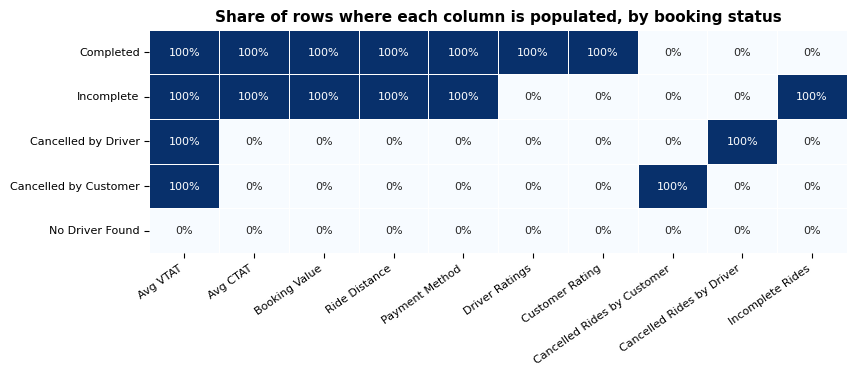

Booking Status,Completed,Incomplete,Cancelled by Driver,Cancelled by Customer,No Driver Found
rows,93000,9000,27000,10500,10500
share,62.0%,6.0%,18.0%,7.0%,7.0%


In [6]:
status_order = ["Completed", "Incomplete", "Cancelled by Driver", "Cancelled by Customer", "No Driver Found"]
post_cols = ["Avg VTAT", "Avg CTAT", "Booking Value", "Ride Distance", "Payment Method",
             "Driver Ratings", "Customer Rating", "Cancelled Rides by Customer",
             "Cancelled Rides by Driver", "Incomplete Rides"]
avail = raw.groupby("Booking Status")[post_cols].agg(lambda s: s.notna().mean()).loc[status_order]
cnt = raw["Booking Status"].value_counts().loc[status_order]
avail.insert(0, "rows", cnt)
fig, ax = plt.subplots(figsize=(9, 2.9))
sns.heatmap(avail.drop(columns="rows"), annot=True, fmt=".0%", cmap="Blues", cbar=False, ax=ax,
            linewidths=.5, annot_kws={"size": 8})
ax.set_title("Share of rows where each column is populated, by booking status")
ax.set_xlabel(""); ax.set_ylabel(""); ax.grid(False); plt.xticks(rotation=35, ha="right")
plt.show()
display(avail[["rows"]].assign(share=lambda d: (d.rows / d.rows.sum()).map(pct)).T)

In [7]:
vt = raw.groupby("Booking Status")["Avg VTAT"].agg(["mean", "count"]).loc[status_order]
md(f"""**Reading the table.** Whether `Avg VTAT` exists, whether `Avg CTAT`, `Booking Value`, `Ride Distance`
or `Payment Method` exist, and whether a rating exists, each *identify the outcome by themselves*: `Avg VTAT` is
populated for 100% of rides except *No Driver Found* (0%); `Booking Value`/`Ride Distance`/`Avg CTAT`/`Payment Method` are populated only for
*Completed* and *Incomplete* rides; ratings only for *Completed* rides. The three `Cancelled/Incomplete` flag columns and their reason columns are
the outcome label itself (always 1 or null).
Even the *values* are not neutral: mean `Avg VTAT` is {vt.loc['Cancelled by Customer','mean']:.1f} min for customer cancellations,
{vt.loc['Cancelled by Driver','mean']:.1f} for driver cancellations, {vt.loc['Incomplete','mean']:.1f} for incomplete and {vt.loc['Completed','mean']:.1f} for completed rides.
All of this is known only **after** a driver is assigned or the trip has started.""")

**Reading the table.** Whether `Avg VTAT` exists, whether `Avg CTAT`, `Booking Value`, `Ride Distance`
or `Payment Method` exist, and whether a rating exists, each *identify the outcome by themselves*: `Avg VTAT` is
populated for 100% of rides except *No Driver Found* (0%); `Booking Value`/`Ride Distance`/`Avg CTAT`/`Payment Method` are populated only for
*Completed* and *Incomplete* rides; ratings only for *Completed* rides. The three `Cancelled/Incomplete` flag columns and their reason columns are
the outcome label itself (always 1 or null).
Even the *values* are not neutral: mean `Avg VTAT` is 12.5 min for customer cancellations,
7.5 for driver cancellations, 6.0 for incomplete and 8.5 for completed rides.
All of this is known only **after** a driver is assigned or the trip has started.

### A4. Leakage rules (explicit)
A feature may enter the **deployable** model only if it is known when the request is created. The decision for every column:

In [8]:
leak = pd.DataFrame([
 ("Date, Time", "Booking-time", "Used (hour, weekday, holiday, peak flags)"),
 ("Vehicle Type, Pickup Location, Drop Location", "Booking-time", "Used (zone, density, target encoding)"),
 ("Booking ID, Customer ID", "Identifier", "Dropped (no information; see customer-history note)"),
 ("Avg VTAT", "Post-acceptance", "Excluded. Null exactly when status = No Driver Found; values differ by status"),
 ("Avg CTAT", "Post-acceptance", "Excluded. Only exists for rides that started (Completed / Incomplete)"),
 ("Booking Value, Ride Distance", "Post-booking in this data", "Excluded. Only exist for Completed/Incomplete rides; Incomplete rides are visibly shorter. A route-average distance built on train rows only is the one allowed proxy"),
 ("Payment Method", "Post-booking in this data", "Excluded. Null for every ride that never started"),
 ("Driver Ratings, Customer Rating", "Post-trip", "Excluded. Exist for Completed rides only"),
 ("Cancelled Rides by Customer/Driver, Incomplete Rides + 3 reason columns", "Outcome itself", "Excluded. These are the label spread over six columns"),
 ("Is_..._Available flags built from any post-booking column", "Missingness proxy", "Excluded. A flag such as Is_Booking_Value_Available is a perfect proxy for 'Completed or Incomplete', so it would leak the outcome"),
], columns=["Column(s)", "Known when?", "Decision"])
display(leak.style.hide(axis="index").set_properties(**{"text-align": "left", "font-size": "9pt"}))

Column(s),Known when?,Decision
"Date, Time",Booking-time,"Used (hour, weekday, holiday, peak flags)"
"Vehicle Type, Pickup Location, Drop Location",Booking-time,"Used (zone, density, target encoding)"
"Booking ID, Customer ID",Identifier,Dropped (no information; see customer-history note)
Avg VTAT,Post-acceptance,Excluded. Null exactly when status = No Driver Found; values differ by status
Avg CTAT,Post-acceptance,Excluded. Only exists for rides that started (Completed / Incomplete)
"Booking Value, Ride Distance",Post-booking in this data,Excluded. Only exist for Completed/Incomplete rides; Incomplete rides are visibly shorter. A route-average distance built on train rows only is the one allowed proxy
Payment Method,Post-booking in this data,Excluded. Null for every ride that never started
"Driver Ratings, Customer Rating",Post-trip,Excluded. Exist for Completed rides only
"Cancelled Rides by Customer/Driver, Incomplete Rides + 3 reason columns",Outcome itself,Excluded. These are the label spread over six columns
Is_..._Available flags built from any post-booking column,Missingness proxy,"Excluded. A flag such as Is_Booking_Value_Available is a perfect proxy for 'Completed or Incomplete', so it would leak the outcome"


**Why not the Approach Document's availability flag?** Section B1 of the Approach Document suggests an `Is_Booking_Value_Available` flag. Because `Booking Value` is empty for every *Cancelled* and *No Driver Found* ride, that flag reproduces the label almost perfectly (we verify it in section E and show the AUC it would produce). It would give a spectacular but meaningless score and zero operational value. **We do not use it.** Post-booking columns are used only for exploration, for answering the business questions, and for a separately labelled diagnostic model.

**Customer history.** The Approach Document calls the customer's historical cancellation rate "the single strongest indicator", but the data cannot support it (check below): almost every customer ID occurs exactly once, and the `Cancelled Rides by ...` columns are per-ride flags, not running counts. We therefore build **no** customer-history feature.

In [9]:
vc = raw["Customer ID"].value_counts()
single = (vc == 1).sum() / len(vc)
# Booking-ID collision investigation
dups = raw[raw["Booking ID"].duplicated(keep=False)]
g = dups.groupby("Booking ID")
n_ids = g.ngroups
diff_cust = (g["Customer ID"].nunique() > 1).mean()
diff_date = (g["Date"].nunique() > 1).mean()
same_all = raw.duplicated(keep=False).sum()
md(f"""**Customer IDs:** {raw['Customer ID'].nunique():,} distinct IDs over {len(raw):,} rows; **{pct(single)}** of customers appear once, the maximum is {vc.max()} bookings per customer. A behavioural history feature is therefore impossible.

**Repeated Booking IDs:** {n_ids:,} Booking IDs appear more than once ({len(dups):,} rows). In **{pct(diff_cust)}** of those IDs the rows belong to *different customers* and in **{pct(diff_date)}** they fall on *different dates*; fully identical rows: {same_all}.
This is a pattern of random ID collisions, not duplicated records. **Decision:** keep every row (dropping them would remove real, distinct rides), and never use `Booking ID` as a key or feature.""")
R["single_customer_share"] = single; R["dup_ids"] = n_ids

**Customer IDs:** 148,788 distinct IDs over 150,000 rows; **99.2%** of customers appear once, the maximum is 3 bookings per customer. A behavioural history feature is therefore impossible.

**Repeated Booking IDs:** 1,224 Booking IDs appear more than once (2,457 rows). In **100.0%** of those IDs the rows belong to *different customers* and in **99.6%** they fall on *different dates*; fully identical rows: 0.
This is a pattern of random ID collisions, not duplicated records. **Decision:** keep every row (dropping them would remove real, distinct rides), and never use `Booking ID` as a key or feature.

## Part B. Cleaning and feature engineering (booking-time only)
### B1. Cleaning decisions
* IDs contain literal quote characters (e.g. `"CNR5884300"`), which are stripped.
* `Date` and `Time` are merged into one timestamp; rows are sorted chronologically.
* Nulls in post-booking columns are **legitimate** and are **left as they are** for EDA. They are never imputed with a mean and never turned into flags for the deployable model (see A4).
* Target created: `completed` (1) / `non_completed` (0 for the ML target).

### B2. Zones
The data has 176 pickup locations and no zone column, so a **hand-built lookup** maps each location to a zone. It is listed in *Appendix A* (collapsed below to save space). Three views are used: **fine groups** (Q2), **North / South / Other** and **Delhi vs satellite cities** (Q7). A sensitivity check on the uncertain placements is in Q7.

In [10]:
ZONE_FINE = {
 "North Delhi": ["Adarsh Nagar","Ashok Vihar","Azadpur","GTB Nagar","Jahangirpuri","Kashmere Gate","Kashmere Gate ISBT","Keshav Puram","Model Town","Pitampura","Samaypur Badli","Shastri Nagar","Tis Hazari","Vishwavidyalaya","Rohini","Rohini East","Rohini West","Rithala","Netaji Subhash Place","Kanhaiya Nagar","Pulbangash","Vidhan Sabha","Inderlok"],
 "Central Delhi": ["Connaught Place","Rajiv Chowk","Barakhamba Road","Mandi House","ITO","India Gate","Pragati Maidan","Central Secretariat","Lok Kalyan Marg","Udyog Bhawan","Paharganj","New Delhi Railway Station","Karol Bagh","Khan Market","Jor Bagh","Chanakyapuri","Patel Chowk","Satguru Ram Singh Marg","Indraprastha","Chandni Chowk","Jama Masjid","Lal Quila","Delhi Gate","Sarojini Nagar"],
 "West Delhi": ["Janakpuri","Kirti Nagar","Moti Nagar","Punjabi Bagh","Rajouri Garden","Peeragarhi","Paschim Vihar","Madipur","Mundka","Nawada","Ashok Park Main","Ramesh Nagar","Subhash Nagar","Tagore Garden","Tilak Nagar","Uttam Nagar","Shivaji Park","Dwarka Mor","Dwarka Sector 21","IGI Airport"],
 "East Delhi": ["Anand Vihar","Anand Vihar ISBT","Akshardham","Dilshad Garden","Karkarduma","Laxmi Nagar","Mayur Vihar","Preet Vihar","Seelampur","Shahdara","Shastri Park","Yamuna Bank","Jhilmil","Nirman Vihar","Welcome","Mansarovar Park"],
 "South Delhi": ["AIIMS","Ashram","Aya Nagar","Badarpur","Bhikaji Cama Place","Chhatarpur","Chirag Delhi","Ghitorni","Ghitorni Village","Govindpuri","Greater Kailash","Green Park","Hauz Khas","Hauz Rani","IIT Delhi","IGNOU Road","INA Market","Jasola","Kalkaji","Lajpat Nagar","Maidan Garhi","Malviya Nagar","Mehrauli","Moolchand","Munirka","Nehru Place","Okhla","Panchsheel Park","Qutub Minar","RK Puram","Saidulajab","Saket","Saket A Block","Sarai Kale Khan","South Extension","Sultanpur","Tughlakabad","Vasant Kunj","Vinobapuri","Arjangarh"],
 "Gurgaon": ["Ambience Mall","Ardee City","Badshahpur","Basai Dhankot","Civil Lines Gurgaon","Cyber Hub","DLF City Court","DLF Phase 3","Golf Course Road","Gurgaon Railway Station","Gurgaon Sector 29","Gurgaon Sector 56","Gwal Pahari","Hero Honda Chowk","Huda City Centre","IFFCO Chowk","Kadarpur","Khandsa","Kherki Daula Toll","MG Road","Narsinghpur","New Colony","Old Gurgaon","Palam Vihar","Pataudi Chowk","Rajiv Nagar","Sadar Bazar Gurgaon","Sikanderpur","Sohna Road","Subhash Chowk","Sushant Lok","Udyog Vihar","Udyog Vihar Phase 4","Vatika Chowk","Manesar","IMT Manesar"],
 "Noida": ["Noida Extension","Noida Film City","Noida Sector 18","Noida Sector 62","Greater Noida","Botanical Garden"],
 "Ghaziabad": ["Ghaziabad","Kaushambi","Vaishali","Indirapuram","Raj Nagar Extension"],
 "Faridabad": ["Faridabad Sector 15"],
 "Outer NCR": ["Bhiwadi","Bahadurgarh","Panipat","Sonipat","Meerut"],
}
REGION_NSO = {"North Delhi":"North","West Delhi":"North","East Delhi":"North","Ghaziabad":"North",
              "South Delhi":"South","Gurgaon":"South","Faridabad":"South",
              "Central Delhi":"Other","Noida":"Other","Outer NCR":"Other"}
REGION_DS = {z: ("Delhi" if z.endswith("Delhi") else "Satellite cities") for z in ZONE_FINE}
# uncertain placements and their plausible alternative (used only in the Q7 sensitivity check)
ALT_ZONE = {"Rajiv Nagar":"North Delhi","New Colony":"South Delhi","Ambience Mall":"South Delhi","MG Road":"Central Delhi",
            "Sultanpur":"Gurgaon","Gwal Pahari":"South Delhi","Shastri Nagar":"Ghaziabad","Mansarovar Park":"Ghaziabad",
            "Botanical Garden":"South Delhi","IGI Airport":"Gurgaon","Sarai Kale Khan":"East Delhi","Subhash Chowk":"West Delhi",
            "Arjangarh":"Gurgaon","Indraprastha":"East Delhi","Inderlok":"Central Delhi","Pulbangash":"Central Delhi","Welcome":"North Delhi"}

In [11]:
LOC2ZONE = {loc: z for z, locs in ZONE_FINE.items() for loc in locs}
assert len(LOC2ZONE) == sum(map(len, ZONE_FINE.values())), "a location is listed in two zones"

df = raw.copy()
for c in ["Booking ID", "Customer ID"]:
    df[c] = df[c].str.replace('"', "", regex=False)
df["ts"] = pd.to_datetime(df["Date"] + " " + df["Time"])
df = df.sort_values("ts").reset_index(drop=True)
df["completed"] = (df["Booking Status"] == "Completed").astype(int)
df["non_completed"] = 1 - df["completed"]
df["pickup_zone"] = df["Pickup Location"].map(LOC2ZONE)
df["drop_zone"] = df["Drop Location"].map(LOC2ZONE)
assert df["pickup_zone"].notna().all() and df["drop_zone"].notna().all(), "unmapped location"
df["region_nso"] = df["pickup_zone"].map(REGION_NSO)
df["region_ds"] = df["pickup_zone"].map(REGION_DS)
df["hour"] = df.ts.dt.hour; df["dow"] = df.ts.dt.dayofweek
df["dow_name"] = df.ts.dt.day_name().str[:3]
df["cancelled"] = df["Booking Status"].isin(["Cancelled by Driver", "Cancelled by Customer"]).astype(int)
df["driver_cancel"] = (df["Booking Status"] == "Cancelled by Driver").astype(int)
df["no_driver"] = (df["Booking Status"] == "No Driver Found").astype(int)
md(f"All **{df['Pickup Location'].nunique()}** pickup and **{df['Drop Location'].nunique()}** drop locations are mapped to zones. "
   f"Rows: {len(df):,}; period {df.ts.min():%d %b %Y} to {df.ts.max():%d %b %Y}; **non-completion rate {pct(df.non_completed.mean())}**.")
R["n"] = len(df); R["nc_rate"] = df.non_completed.mean()

All **176** pickup and **176** drop locations are mapped to zones. Rows: 150,000; period 01 Jan 2024 to 30 Dec 2024; **non-completion rate 38.0%**.

### B3. Booking-time features that need no fitting
Temporal features follow the Approach Document: hour, weekday, month, peak-hour flags (7 to 10 AM and 5 to 8 PM), a time-of-day slot, and a **day type** (weekday / weekend / public holiday, from the `holidays` package for India, 2024). Geographic features at this stage are the zones. Features that need *fitting on training data* (density, target encoding, route distance) are built later, after the split, so nothing from the test period can leak in.

In [12]:
IN_HOL = holidays.India(years=2024)
SLOT_BINS = [-1, 4, 6, 10, 16, 20, 23]
SLOT_LABELS = ["Night (0-4)", "Early (5-6)", "Morning peak (7-10)", "Midday (11-16)", "Evening peak (17-20)", "Late evening (21-23)"]

def static_features(d):
    """Features computable from a single booking row, with no statistics learned from other rows."""
    X = pd.DataFrame(index=d.index)
    X["hour"] = d.ts.dt.hour
    X["dow"] = d.ts.dt.dayofweek
    X["month"] = d.ts.dt.month
    X["day_of_month"] = d.ts.dt.day
    X["is_weekend"] = (X.dow >= 5).astype(int)
    X["is_holiday"] = d.ts.dt.date.isin(IN_HOL).astype(int)
    X["peak_am"] = X.hour.between(7, 10).astype(int)
    X["peak_pm"] = X.hour.between(17, 20).astype(int)
    X["is_night"] = ((X.hour >= 22) | (X.hour < 5)).astype(int)
    X["time_slot"] = pd.cut(X.hour, SLOT_BINS, labels=SLOT_LABELS).astype(str)
    X["day_type"] = np.where(X.is_holiday == 1, "Holiday", np.where(X.is_weekend == 1, "Weekend", "Weekday"))
    X["Vehicle Type"] = d["Vehicle Type"].values
    X["pickup_zone"] = d["pickup_zone"].values
    X["drop_zone"] = d["drop_zone"].values
    X["cross_zone"] = (d["pickup_zone"] != d["drop_zone"]).astype(int).values
    return X

CATS = ["time_slot", "day_type", "Vehicle Type", "pickup_zone", "drop_zone"]
n_hol = df.ts.dt.date.drop_duplicates().isin(IN_HOL).sum()
md(f"Static features defined. The calendar contains **{n_hol} public-holiday dates** in the data window.")

Static features defined. The calendar contains **18 public-holiday dates** in the data window.

### B4. Time-based split (defined once, before anything is fitted)
Following the Approach Document, the **earliest 80% of rides (by timestamp) train the model and the latest 20% test it**, which mimics deploying on future days. The last 15% of the training period is further held out as a **validation/calibration slice** (used for tuning decisions, calibration and thresholds), so the test set is touched only for final reporting.

In [13]:
cut = int(0.8 * len(df))
train, test = df.iloc[:cut].copy(), df.iloc[cut:].copy()
cut2 = int(0.85 * len(train))
train_fit, cal = train.iloc[:cut2], train.iloc[cut2:]
split_tbl = pd.DataFrame({"from": [train_fit.ts.min(), cal.ts.min(), test.ts.min()],
                          "to": [train_fit.ts.max(), cal.ts.max(), test.ts.max()],
                          "rows": [len(train_fit), len(cal), len(test)],
                          "non-completion rate": [x.non_completed.mean() for x in (train_fit, cal, test)]},
                         index=["Train (fit)", "Validation/calibration", "Test (future)"])
split_tbl["from"] = split_tbl["from"].dt.strftime("%d %b %Y"); split_tbl["to"] = split_tbl["to"].dt.strftime("%d %b %Y")
split_tbl["non-completion rate"] = split_tbl["non-completion rate"].map(pct)
display(split_tbl)

,from,to,rows,non-completion rate
Train (fit),01 Jan 2024,04 Sep 2024,102000,38.0%
Validation/calibration,04 Sep 2024,18 Oct 2024,18000,38.0%
Test (future),18 Oct 2024,30 Dec 2024,30000,37.9%


### B5. Class-imbalance check
The Approach Document asks whether the minority class is below 10%. Here the *non-completed* class is the minority, so we measure it. The chosen remedy is **class weighting** (no SMOTE), applied in every model.

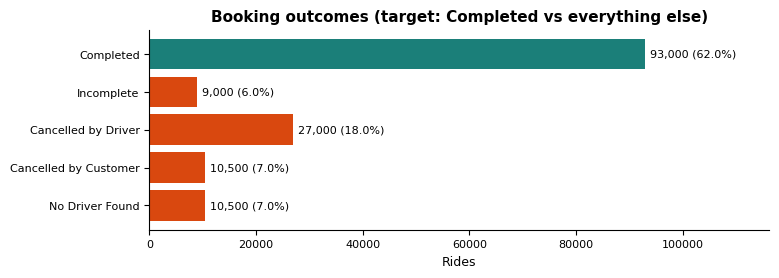

In [14]:
status_counts = df["Booking Status"].value_counts().loc[status_order]
fig, ax = plt.subplots(figsize=(8, 2.6))
colors = [C_OK] + [C_BAD] * 4
ax.barh(status_counts.index[::-1], status_counts.values[::-1], color=colors[::-1])
for i, v in enumerate(status_counts.values[::-1]):
    ax.text(v + 800, i, f"{v:,} ({v/len(df):.1%})", va="center", fontsize=8)
ax.set_xlim(0, status_counts.max() * 1.25); ax.set_xlabel("Rides"); ax.set_title("Booking outcomes (target: Completed vs everything else)")
ax.grid(False); plt.show()

In [15]:
md(f"""**Insight.** {pct(df.non_completed.mean())} of requests do not complete. The largest failure mode is *Cancelled by Driver* ({pct(status_counts['Cancelled by Driver']/len(df))}),
then customer cancellations and *No Driver Found* ({pct(status_counts['Cancelled by Customer']/len(df))} each) and *Incomplete* ({pct(status_counts['Incomplete']/len(df))}).
The minority class is far above the 10% rule of thumb, so imbalance is **mild**; class weights are still used so that errors on the non-completed class are not under-penalised.""")

**Insight.** 38.0% of requests do not complete. The largest failure mode is *Cancelled by Driver* (18.0%),
then customer cancellations and *No Driver Found* (7.0% each) and *Incomplete* (6.0%).
The minority class is far above the 10% rule of thumb, so imbalance is **mild**; class weights are still used so that errors on the non-completed class are not under-penalised.

## Part C. Exploratory analysis
Because the Approach Document warns that small differences can look like "hot spots", every pattern below is tested against **label shuffling** (a permutation test) or a chi-square test before it is called a pattern. EDA uses the full data, including post-booking columns, purely to understand the problem.

### C1. Temporal risk

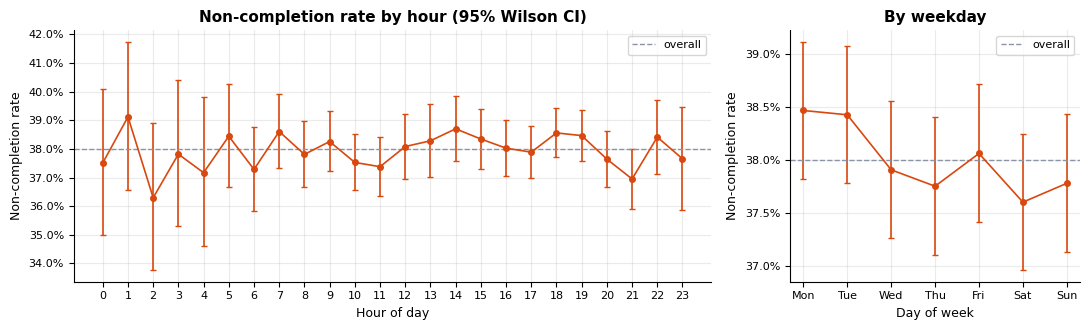

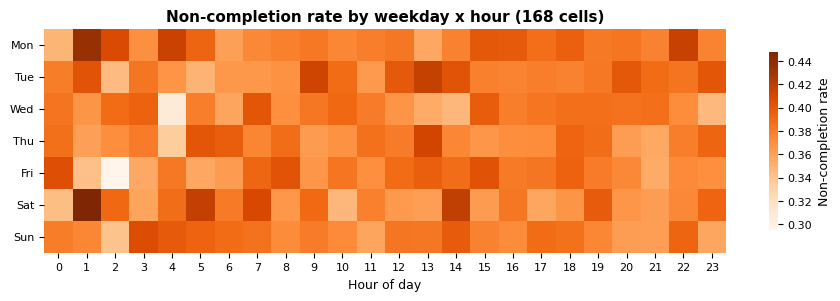

In [16]:
def rate_plot(ax, tab, xlabel, title, labels=None, color=C_BAD):
    x = np.arange(len(tab))
    ax.errorbar(x, tab.rate, yerr=[tab.rate - tab.lo, tab.hi - tab.rate], fmt="o-", color=color, ms=4, lw=1.2, capsize=2)
    ax.axhline(df.non_completed.mean(), color=C_NEUT, ls="--", lw=1, label="overall")
    ax.set_xticks(x); ax.set_xticklabels(labels if labels is not None else tab.index)
    ax.set_xlabel(xlabel); ax.set_ylabel("Non-completion rate"); ax.set_title(title)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1%}")); ax.legend()

by_hour = rate_table(df, "hour", "non_completed")
by_dow = rate_table(df, "dow", "non_completed")
fig, axs = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={"width_ratios": [2.2, 1]})
rate_plot(axs[0], by_hour, "Hour of day", "Non-completion rate by hour (95% Wilson CI)")
rate_plot(axs[1], by_dow, "Day of week", "By weekday", labels=["Mon","Tue","Wed","Thu","Fri","Sat","Sun"])
plt.tight_layout(); plt.show()

hd = df.assign(cell=df.hour * 7 + df.dow)
codes = pd.factorize(hd["cell"])[0]
pt_cell = perm_test(codes, df.non_completed.values)
pt_hour = perm_test(df.hour.values, df.non_completed.values)
pt_dow = perm_test(df.dow.values, df.non_completed.values)
p_hour, p_dow = chi2_p(df, "hour", "non_completed"), chi2_p(df, "dow", "non_completed")
piv = df.pivot_table(index="dow", columns="hour", values="non_completed", aggfunc="mean")
fig, ax = plt.subplots(figsize=(11, 2.9))
sns.heatmap(piv, cmap="Oranges", ax=ax, cbar_kws={"label": "Non-completion rate", "shrink": .8}, vmin=piv.values.min(), vmax=piv.values.max())
ax.set_yticklabels(["Mon","Tue","Wed","Thu","Fri","Sat","Sun"], rotation=0); ax.set_xlabel("Hour of day"); ax.set_ylabel("")
ax.set_title("Non-completion rate by weekday x hour (168 cells)"); ax.grid(False); plt.show()

In [17]:
md(f"""**Insight.** Across hours the non-completion rate ranges only from {pct(by_hour.rate.min())} to {pct(by_hour.rate.max())}, and across weekdays from {pct(by_dow.rate.min())} to {pct(by_dow.rate.max())}.
Chi-square tests give **p = {p_hour:.2f} (hour)** and **p = {p_dow:.2f} (weekday)**. For the 168 weekday-hour cells, the spread of cell rates (SD {pt_cell['std']:.4f}) is compared with
what random shuffling of the labels produces (95th percentile {pt_cell['null_std95']:.4f}): permutation p = {pt_cell['p_std']:.2f}.
So the apparent "rush-hour spikes" visible in the chart are within sampling noise; the data does **not** show a statistically distinguishable peak-hour or weekday effect on non-completion.""")
R.update(p_hour=p_hour, p_dow=p_dow, p_cell=pt_cell["p_std"])

**Insight.** Across hours the non-completion rate ranges only from 36.3% to 39.1%, and across weekdays from 37.6% to 38.5%.
Chi-square tests give **p = 0.80 (hour)** and **p = 0.40 (weekday)**. For the 168 weekday-hour cells, the spread of cell rates (SD 0.0202) is compared with
what random shuffling of the labels produces (95th percentile 0.0239): permutation p = 0.78.
So the apparent "rush-hour spikes" visible in the chart are within sampling noise; the data does **not** show a statistically distinguishable peak-hour or weekday effect on non-completion.

### C2. Geographic risk
With 176 pickup locations of about 850 rides each, some will look "hot" by chance alone. The chart sorts all locations by non-completion rate and overlays the range expected from pure noise (95% band around the overall rate for that location's sample size).

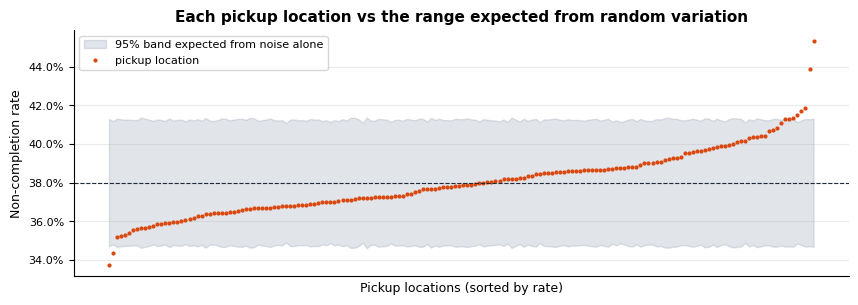

,rides,non-completed,rate,CI low,CI high
Pickup Location,,,,,
Vinobapuri,823,373,45.3%,42.0%,48.7%
Akshardham,839,368,43.9%,40.5%,47.2%
Chhatarpur,829,347,41.9%,38.5%,45.2%
Badshahpur,868,362,41.7%,38.5%,45.0%
Pragati Maidan,920,382,41.5%,38.4%,44.7%


In [18]:
loc = rate_table(df, "Pickup Location", "non_completed").sort_values("rate")
p0 = df.non_completed.mean()
band = 1.96 * np.sqrt(p0 * (1 - p0) / loc.n)
outside = ((loc.rate > p0 + band) | (loc.rate < p0 - band)).mean()
fig, ax = plt.subplots(figsize=(10, 3.2))
x = np.arange(len(loc))
ax.fill_between(x, p0 - band.values, p0 + band.values, color=C_NEUT, alpha=.25, label="95% band expected from noise alone")
ax.plot(x, loc.rate.values, ".", color=C_BAD, ms=4, label="pickup location")
ax.axhline(p0, color=C_DARK, lw=.8, ls="--")
ax.set_xlabel("Pickup locations (sorted by rate)"); ax.set_ylabel("Non-completion rate"); ax.set_xticks([])
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1%}"))
ax.set_title("Each pickup location vs the range expected from random variation"); ax.legend(loc="upper left"); plt.show()
pt_loc = perm_test(pd.factorize(df["Pickup Location"])[0], df.non_completed.values)
display(loc.sort_values("rate", ascending=False).head(5).assign(rate=lambda d: d.rate.map(pct), lo=lambda d: d.lo.map(pct), hi=lambda d: d.hi.map(pct))
        .rename(columns={"n": "rides", "k": "non-completed", "lo": "CI low", "hi": "CI high"}))

In [19]:
z_loc = (loc.rate - p0) / np.sqrt(p0 * (1 - p0) / loc.n)
p_loc_adj = np.minimum(2 * stats.norm.sf(np.abs(z_loc)) * len(loc), 1)       # Bonferroni over all locations
n_out = int(((loc.rate > p0 + band) | (loc.rate < p0 - band)).sum()); n_bonf = int((p_loc_adj < .05).sum())
md(f"""**Insight.** Location rates run from {pct(loc.rate.min())} to {pct(loc.rate.max())}. **{n_out} of {len(loc)} locations ({pct(outside)})** fall outside the noise band, almost exactly the ~5% ({0.05*len(loc):.0f} locations) expected if every location were identical.
The permutation test on the spread of location rates gives p = {pt_loc['p_std']:.2f}, and after correcting for testing {len(loc)} locations at once (Bonferroni) **{n_bonf} location{'s' if n_bonf != 1 else ''}** {'remains' if n_bonf == 1 else 'remain'} significantly different from the overall {pct(p0)}.
Individual locations such as the worst one in the table can look bad on their own (its interval excludes the average), but when 176 are inspected some always do; that is not evidence of a persistent hot spot.
Zone-level results (Q2) are tested the same way.""")
R["p_loc"] = pt_loc["p_std"]

**Insight.** Location rates run from 33.7% to 45.3%. **9 of 176 locations (5.1%)** fall outside the noise band, almost exactly the ~5% (9 locations) expected if every location were identical.
The permutation test on the spread of location rates gives p = 0.31, and after correcting for testing 176 locations at once (Bonferroni) **1 location** remains significantly different from the overall 38.0%.
Individual locations such as the worst one in the table can look bad on their own (its interval excludes the average), but when 176 are inspected some always do; that is not evidence of a persistent hot spot.
Zone-level results (Q2) are tested the same way.

### C3. Vehicle type and operational time signals (VTAT / CTAT)
`Avg VTAT` (Average Vehicle Travel Time to Acceptance) and `Avg CTAT` (Average Customer Travel Time to Acceptance, i.e. the average time a driver takes to reach the customer after acceptance) are recorded only after a driver accepts, so they are used here for diagnosis, never for the booking-time model. The boxplots state the number of rides behind each box (the denominator) because the nulls differ by status.

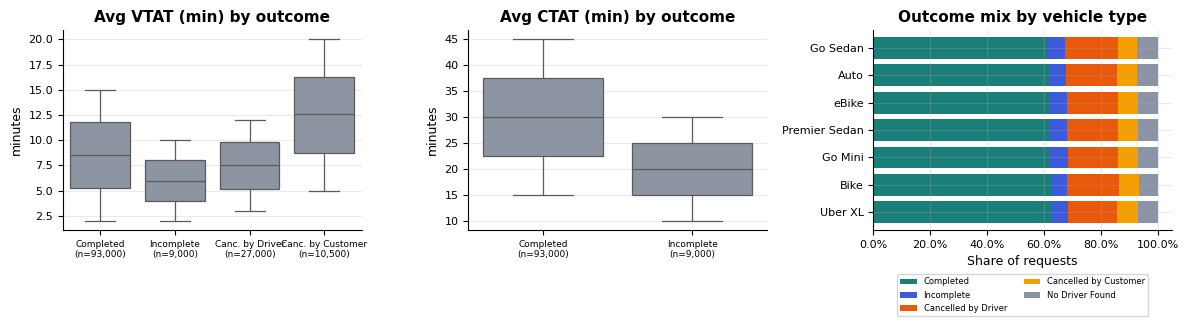

In [20]:
vt_order = df.groupby("Vehicle Type").non_completed.mean().sort_values().index.tolist()
stat_vehicle = pd.crosstab(df["Vehicle Type"], df["Booking Status"], normalize="index")[status_order].loc[vt_order]
fig, axs = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, col, ttl in [(axs[0], "Avg VTAT", "Avg VTAT (min) by outcome"), (axs[1], "Avg CTAT", "Avg CTAT (min) by outcome")]:
    sub = df.dropna(subset=[col]); order = [s for s in status_order if s in sub["Booking Status"].unique()]
    sns.boxplot(data=sub, x="Booking Status", y=col, order=order, ax=ax, color=C_NEUT, showfliers=False, linewidth=.9)
    ax.set_xticklabels([f"{s.replace('Cancelled by','Canc. by')}\n(n={(sub['Booking Status']==s).sum():,})" for s in order], fontsize=6.5)
    ax.set_xlabel(""); ax.set_ylabel("minutes"); ax.set_title(ttl)
stat_vehicle.plot(kind="barh", stacked=True, ax=axs[2], color=[C_OK, C_ACC, "#e8590c", "#f59f00", C_NEUT], width=.8, legend=False)
axs[2].set_title("Outcome mix by vehicle type"); axs[2].set_xlabel("Share of requests"); axs[2].set_ylabel("")
axs[2].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1%}"))
axs[2].legend(status_order, fontsize=6, loc="upper center", bbox_to_anchor=(.5, -.2), ncol=2)
plt.tight_layout(); plt.show()
g = df.groupby("Booking Status")[["Avg VTAT", "Avg CTAT"]].agg(["mean", "count"]).loc[status_order]
p_veh = chi2_p(df, "Vehicle Type", "non_completed")

In [21]:
md(f"""**Insight.** Unlike the booking-time features, the post-acceptance time measures *do* differ by outcome: mean VTAT is {g[('Avg VTAT','mean')]['Cancelled by Customer']:.1f} min
for customer-cancelled rides (n = {int(g[('Avg VTAT','count')]['Cancelled by Customer']):,}) versus {g[('Avg VTAT','mean')]['Completed']:.1f} min for completed rides (n = {int(g[('Avg VTAT','count')]['Completed']):,}), consistent with riders cancelling when the
VTAT is long. CTAT is {g[('Avg CTAT','mean')]['Completed']:.1f} min for completed (n = {int(g[('Avg CTAT','count')]['Completed']):,}) versus {g[('Avg CTAT','mean')]['Incomplete']:.1f} for incomplete rides
(n = {int(g[('Avg CTAT','count')]['Incomplete']):,}); CTAT does not exist for cancelled rides at all, so it cannot rank cancellation risk.
By contrast, the outcome mix is almost identical across vehicle types (chi-square p = {p_veh:.2f}).
These are *consequences* of a ride being matched, so they inform operations (Q1, Q3) but are unavailable when the request is made.""")
R["p_veh"] = p_veh

**Insight.** Unlike the booking-time features, the post-acceptance time measures *do* differ by outcome: mean VTAT is 12.5 min
for customer-cancelled rides (n = 10,500) versus 8.5 min for completed rides (n = 93,000), consistent with riders cancelling when the
VTAT is long. CTAT is 30.0 min for completed (n = 93,000) versus 20.0 for incomplete rides
(n = 9,000); CTAT does not exist for cancelled rides at all, so it cannot rank cancellation risk.
By contrast, the outcome mix is almost identical across vehicle types (chi-square p = 0.40).
These are *consequences* of a ride being matched, so they inform operations (Q1, Q3) but are unavailable when the request is made.

## Part D. Modelling
### D1. Fit-dependent features (built on training rows only)
Four features need statistics learned from data. Each is fitted **only on the training window** and then applied to the validation and test rows:

| Feature | Definition | Leakage guard |
|---|---|---|
| `pickup_density`, `drop_density` | share of training bookings that start / end at the location | counts only, no labels |
| `pickup_te`, `drop_te` | smoothed historical **completion rate** of the location (target encoding, smoothing strength 30) | **out-of-fold** for training rows, so a row never sees its own label |
| `route_dist_proxy` | smoothed mean `Ride Distance` of earlier rides on the same pickup-to-drop route (strength 3), a booking-time stand-in for trip length | computed on training rows only, out-of-fold for training rows |

The distance proxy is kept **only if it does not hurt validation performance** (decision shown below).

In [22]:
def smooth_mean(keys_fit, vals_fit, keys_apply, prior, m):
    """Smoothed per-key mean learned on (keys_fit, vals_fit), looked up for keys_apply. NaN values are ignored."""
    s = pd.DataFrame({"k": keys_fit, "v": vals_fit}).dropna().groupby("k")["v"].agg(["sum", "count"])
    j = s.reindex(keys_apply)
    return (j["sum"].fillna(0).values + m * prior) / (j["count"].fillna(0).values + m)

def oof_smooth_mean(keys, vals, prior, m, n_splits=5):
    """Same encoding for training rows, but each row is encoded from the other folds only."""
    out = np.zeros(len(keys))
    for a, b in KFold(n_splits).split(keys):            # contiguous (time) blocks, no shuffling
        out[b] = smooth_mean(keys[a], vals[a], keys[b], prior, m)
    return out

def build_matrices(tr, others, use_proxy=True):
    """Booking-time feature matrices. Statistics are learned on `tr` only."""
    Xtr = static_features(tr); Xo = [static_features(o) for o in others]
    prior = tr.completed.mean()
    for name, col in [("pickup", "Pickup Location"), ("drop", "Drop Location")]:
        freq = tr[col].value_counts(normalize=True)
        Xtr[f"{name}_density"] = tr[col].map(freq).values
        Xtr[f"{name}_te"] = oof_smooth_mean(tr[col].values, tr.completed.values, prior, 30)
        for X, o in zip(Xo, others):
            X[f"{name}_density"] = o[col].map(freq).fillna(freq.median()).values
            X[f"{name}_te"] = smooth_mean(tr[col].values, tr.completed.values, o[col].values, prior, 30)
    if use_proxy:
        route = lambda d: (d["Pickup Location"] + ">" + d["Drop Location"]).values
        pr = tr["Ride Distance"].mean()
        Xtr["route_dist_proxy"] = oof_smooth_mean(route(tr), tr["Ride Distance"].values, pr, 3)
        for X, o in zip(Xo, others):
            X["route_dist_proxy"] = smooth_mean(route(tr), tr["Ride Distance"].values, route(o), pr, 3)
    cats = {c: sorted(Xtr[c].unique()) for c in CATS}
    for X in [Xtr] + Xo:
        for c in CATS: X[c] = pd.Categorical(X[c], categories=cats[c])
    return [Xtr] + Xo

LGB_BASE = dict(n_estimators=200, learning_rate=0.05, num_leaves=15, min_child_samples=100, subsample=0.8,
                subsample_freq=1, colsample_bytree=0.8, class_weight="balanced", random_state=SEED, n_jobs=4, verbose=-1)

def evaluate(y, p_comp, thr=0.5):
    """y = 1 completed. Ranking metrics treat NON-completion as the positive class."""
    y = np.asarray(y); pred = (np.asarray(p_comp) >= thr).astype(int)
    return {"PR-AUC (non-comp.)": average_precision_score(1 - y, 1 - p_comp), "ROC-AUC": roc_auc_score(y, p_comp),
            "F1 non-comp.": f1_score(y, pred, pos_label=0), "F1 completed": f1_score(y, pred, pos_label=1),
            "Macro F1": f1_score(y, pred, average="macro")}

In [23]:
# ---- keep-or-drop decision for the distance proxy (judged on the validation slice only) ----
chk = {}
for flag in (True, False):
    Xa, Xb = build_matrices(train_fit, [cal], use_proxy=flag)
    m_ = lgb.LGBMClassifier(**LGB_BASE).fit(Xa, train_fit.completed)
    chk[f"with proxy" if flag else "without proxy"] = evaluate(cal.completed, m_.predict_proba(Xb)[:, 1])
chk = pd.DataFrame(chk).T[["PR-AUC (non-comp.)", "ROC-AUC"]]
USE_PROXY = bool(chk.loc["with proxy", "ROC-AUC"] >= chk.loc["without proxy", "ROC-AUC"])
display(chk.round(4))
md(f"Validation ROC-AUC {chk.loc['with proxy','ROC-AUC']:.4f} with the proxy vs {chk.loc['without proxy','ROC-AUC']:.4f} without, "
   f"so the route-distance proxy is **{'kept' if USE_PROXY else 'dropped'}** (rule: keep only if it does not lower validation ROC-AUC).")

X_fit, X_cal, X_test = build_matrices(train_fit, [cal, test], use_proxy=USE_PROXY)
y_fit, y_cal, y_test = train_fit.completed.values, cal.completed.values, test.completed.values
NUM = [c for c in X_fit.columns if c not in CATS]
md(f"Final booking-time feature matrix: **{X_fit.shape[1]} features** ({len(NUM)} numeric, {len(CATS)} categorical), "
   f"{len(X_fit):,} training rows, {len(X_cal):,} validation rows, {len(X_test):,} test rows.")

,PR-AUC (non-comp.),ROC-AUC
with proxy,0.38,0.498
without proxy,0.38,0.504


Validation ROC-AUC 0.4983 with the proxy vs 0.5038 without, so the route-distance proxy is **dropped** (rule: keep only if it does not lower validation ROC-AUC).

Final booking-time feature matrix: **19 features** (14 numeric, 5 categorical), 102,000 training rows, 18,000 validation rows, 30,000 test rows.

### D2. Drift check: is the future like the past?
A time-based split is only informative if train and test are comparable. The chart shows the monthly non-completion rate; the test below compares the mix of vehicle types and pickup regions between the training window and the test window.

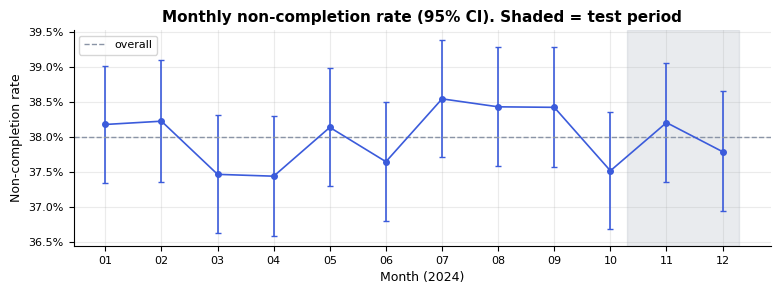

In [24]:
mon = df.assign(month=df.ts.dt.to_period("M").astype(str)).pipe(rate_table, "month", "non_completed")
fig, ax = plt.subplots(figsize=(9, 2.8))
rate_plot(ax, mon, "Month (2024)", "Monthly non-completion rate (95% CI). Shaded = test period", labels=[m[-2:] for m in mon.index], color=C_ACC)
ax.axvspan(len(mon) - 2.7, len(mon) - .7, color=C_NEUT, alpha=.18); plt.show()
dr = {}
mix_tr = pd.concat([train_fit.assign(g="train"), test.assign(g="test")])
mix_tr["time_slot"] = static_features(mix_tr)["time_slot"].values
for c in ["Vehicle Type", "region_nso", "time_slot"]:
    dr[c] = chi2_contingency(pd.crosstab(mix_tr[c], mix_tr["g"]))[1]
p_trend = chi2_p(mix_tr.assign(nc=mix_tr.non_completed), "g", "nc")
vs = pd.crosstab(mix_tr["Vehicle Type"], mix_tr["g"], normalize="columns"); veh_shift = (vs["train"] - vs["test"]).abs().max()

In [25]:
veh_sentence = (f"differs statistically (p = {dr['Vehicle Type']:.2f}) but the largest shift in the share of any vehicle type is only {100*veh_shift:.2f} percentage points"
                if dr['Vehicle Type'] < .05 else f"is stable (p = {dr['Vehicle Type']:.2f})")
md(f"""**Insight.** Monthly rates stay between {pct(mon.rate.min())} and {pct(mon.rate.max())} with overlapping intervals, and the train-vs-test non-completion rates ({pct(train_fit.non_completed.mean())} vs {pct(test.non_completed.mean())}) do not differ (p = {p_trend:.2f}).
The mix of vehicle types {veh_sentence}; pickup regions (p = {dr['region_nso']:.2f}) and time slots (p = {dr['time_slot']:.2f}) are stable.
**There is no material drift**, so a time-based split is a fair, deployment-like test.""")

**Insight.** Monthly rates stay between 37.4% and 38.5% with overlapping intervals, and the train-vs-test non-completion rates (38.0% vs 37.9%) do not differ (p = 0.80).
The mix of vehicle types differs statistically (p = 0.02) but the largest shift in the share of any vehicle type is only 0.79 percentage points; pickup regions (p = 0.74) and time slots (p = 0.90) are stable.
**There is no material drift**, so a time-based split is a fair, deployment-like test.

### D3. Models: baseline, Random Forest, LightGBM
All three use **class weighting** for the minority (non-completed) class. Selection metric: **PR-AUC of the non-completed class on the validation slice**. The test set is used only for the final report. LightGBM is tuned with a **randomized search using time-ordered cross-validation** inside the training window.

In [26]:
def make_preprocessor():
    return ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATS),
                              ("num", StandardScaler(), NUM)])

ap_nc = make_scorer(lambda y, p: average_precision_score(1 - y, 1 - p), response_method="predict_proba")
models = {
 "Logistic Regression (baseline)": Pipeline([("pre", make_preprocessor()),
        ("clf", LogisticRegression(C=1.0, class_weight="balanced", max_iter=300, random_state=SEED))]),
 "Random Forest": Pipeline([("pre", make_preprocessor()),
        ("clf", RandomForestClassifier(n_estimators=200, max_depth=8, min_samples_leaf=100, class_weight="balanced_subsample",
                                       n_jobs=4, random_state=SEED))]),
 "LightGBM (default)": lgb.LGBMClassifier(**LGB_BASE),
}
space = dict(n_estimators=[100, 200, 300, 500], learning_rate=[.01, .02, .03, .05, .1], num_leaves=[4, 8, 15, 31],
             min_child_samples=[50, 100, 200, 400], subsample=[.6, .8, 1.0], colsample_bytree=[.5, .7, .9],
             reg_lambda=[0, 1, 5, 20], max_depth=[-1, 4, 6])
search = RandomizedSearchCV(lgb.LGBMClassifier(**LGB_BASE), space, n_iter=12, scoring=ap_nc, cv=TimeSeriesSplit(3),
                            random_state=SEED, n_jobs=1, refit=True)
search.fit(X_fit, y_fit)
models["LightGBM (tuned)"] = search.best_estimator_
for name, m_ in models.items():
    if "tuned" not in name: m_.fit(X_fit, y_fit)

rows = {"Random guess (prevalence)": {"PR-AUC (non-comp.)": test.non_completed.mean(), "ROC-AUC": .5}}
val_ap = {}
for name, m_ in models.items():
    val_ap[name] = evaluate(y_cal, m_.predict_proba(X_cal)[:, 1])["PR-AUC (non-comp.)"]
    rows[name] = evaluate(y_test, m_.predict_proba(X_test)[:, 1])
comp = pd.DataFrame(rows).T
comp.insert(0, "Validation PR-AUC", pd.Series(val_ap))
best_name = max(val_ap, key=val_ap.get)
display(comp.round(4))
cvres = pd.DataFrame(search.cv_results_).sort_values("rank_test_score").head(3)[["mean_test_score", "std_test_score", "params"]]
md(f"Selected on validation PR-AUC: **{best_name}**. Best tuned parameters: `{ {k: v for k, v in search.best_params_.items()} }`; "
   f"time-ordered CV PR-AUC of the best setting {cvres.iloc[0]['mean_test_score']:.4f} (SD {cvres.iloc[0]['std_test_score']:.4f}) versus a random-guess level of {(1-y_fit).mean():.4f}.")

,Validation PR-AUC,PR-AUC (non-comp.),ROC-AUC,F1 non-comp.,F1 completed,Macro F1
Random guess (prevalence),NaN,0.379,0.500,NaN,NaN,NaN
Logistic Regression (baseline),0.378,0.381,0.499,0.484,0.420,0.452
Random Forest,0.381,0.385,0.506,0.460,0.512,0.486
LightGBM (default),0.380,0.384,0.505,0.427,0.570,0.499
LightGBM (tuned),0.381,0.382,0.502,0.432,0.558,0.495


Selected on validation PR-AUC: **Random Forest**. Best tuned parameters: `{'subsample': 1.0, 'reg_lambda': 0, 'num_leaves': 15, 'n_estimators': 200, 'min_child_samples': 200, 'max_depth': 4, 'learning_rate': 0.1, 'colsample_bytree': 0.7}`; time-ordered CV PR-AUC of the best setting 0.3844 (SD 0.0087) versus a random-guess level of 0.3802.

In [27]:
best_test = comp.loc[best_name]
spread = comp.drop(index="Random guess (prevalence)")["ROC-AUC"]
md(f"""**Insight.** All three model families land in a narrow band: test ROC-AUC {spread.min():.3f} to {spread.max():.3f} (0.5 = random) and PR-AUC for non-completion
{comp.drop(index='Random guess (prevalence)')['PR-AUC (non-comp.)'].min():.3f} to {comp.drop(index='Random guess (prevalence)')['PR-AUC (non-comp.)'].max():.3f} against {comp.loc['Random guess (prevalence)','PR-AUC (non-comp.)']:.3f} for random guessing.
Making the model more flexible (Random Forest, tuned LightGBM) does not unlock additional signal. That is the pattern expected when the inputs carry little information about the outcome, rather than a modelling shortfall; the next section tests this directly.""")
final_name = "LightGBM (tuned)"
gap_val = val_ap[best_name] - val_ap[final_name]
md(f"""**Model choice.** The validation winner by PR-AUC is {best_name}, but its margin over tuned LightGBM is only **{gap_val:.4f}** PR-AUC, which is a tie (the time-ordered CV SD is {cvres.iloc[0]['std_test_score']:.4f}).
We carry **tuned LightGBM** forward as the Approach Document recommends it for low-latency scoring and it supports SHAP natively; nothing in the evaluation contradicts that choice.""")
R["comp"] = comp; R["best_name"] = best_name

**Insight.** All three model families land in a narrow band: test ROC-AUC 0.499 to 0.506 (0.5 = random) and PR-AUC for non-completion
0.381 to 0.385 against 0.379 for random guessing.
Making the model more flexible (Random Forest, tuned LightGBM) does not unlock additional signal. That is the pattern expected when the inputs carry little information about the outcome, rather than a modelling shortfall; the next section tests this directly.

**Model choice.** The validation winner by PR-AUC is Random Forest, but its margin over tuned LightGBM is only **0.0005** PR-AUC, which is a tie (the time-ordered CV SD is 0.0087).
We carry **tuned LightGBM** forward as the Approach Document recommends it for low-latency scoring and it supports SHAP natively; nothing in the evaluation contradicts that choice.

### D4. Sensitivity: stratified random split
The same tuned LightGBM, trained and tested on a **stratified random** 80/20 split (features rebuilt inside that split) to confirm the conclusion does not depend on the time-based design.

In [28]:
from sklearn.model_selection import train_test_split
tr_r, te_r = train_test_split(df, test_size=.2, stratify=df.completed, random_state=SEED)
Xr_tr, Xr_te = build_matrices(tr_r.sort_values("ts"), [te_r], use_proxy=USE_PROXY)
mr = lgb.LGBMClassifier(**{**LGB_BASE, **search.best_params_}).fit(Xr_tr, tr_r.sort_values("ts").completed)
ev_r = evaluate(te_r.completed, mr.predict_proba(Xr_te)[:, 1])
ev_t = comp.loc["LightGBM (tuned)"]
sens = pd.DataFrame({"time-based (primary)": [ev_t["ROC-AUC"], ev_t["PR-AUC (non-comp.)"]],
                     "stratified random": [ev_r["ROC-AUC"], ev_r["PR-AUC (non-comp.)"]]}, index=["ROC-AUC", "PR-AUC (non-comp.)"])
display(sens.round(4))
R["auc_random_split"] = ev_r["ROC-AUC"]

,time-based (primary),stratified random
ROC-AUC,0.502,0.499
PR-AUC (non-comp.),0.382,0.382


### D5. Calibration
Class weighting deliberately shifts predicted probabilities, so raw scores are **not** probabilities. We fix this with **Platt scaling** (a logistic fit on the validation slice, which is monotonic and therefore cannot change any ranking metric; isotonic regression was avoided because it flattens near-constant scores into ties). The reliability diagram uses the untouched test period.

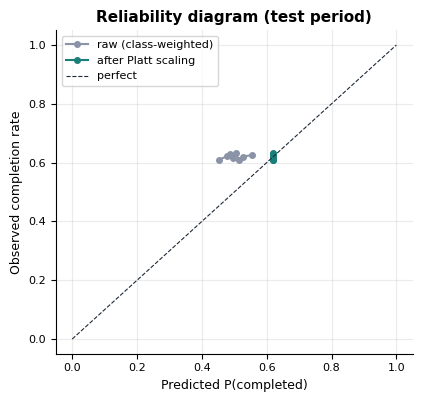

In [29]:
final_raw = models["LightGBM (tuned)"]
p_raw_cal, p_raw_test = final_raw.predict_proba(X_cal)[:, 1], final_raw.predict_proba(X_test)[:, 1]
logit = lambda p: np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6)))
platt = LogisticRegression(C=1e6).fit(logit(p_raw_cal).reshape(-1, 1), y_cal)
calibrate = lambda p: platt.predict_proba(logit(p).reshape(-1, 1))[:, 1]
p_cal, p_test = calibrate(p_raw_cal), calibrate(p_raw_test)
fig, ax = plt.subplots(figsize=(4.6, 4.2))
for p_, lab, col in [(p_raw_test, "raw (class-weighted)", C_NEUT), (p_test, "after Platt scaling", C_OK)]:
    fr, mp = calibration_curve(y_test, p_, n_bins=8, strategy="quantile")
    ax.plot(mp, fr, "o-", label=lab, color=col, ms=4)
ax.plot([0, 1], [0, 1], "--", color=C_DARK, lw=.8, label="perfect")
ax.set_xlabel("Predicted P(completed)"); ax.set_ylabel("Observed completion rate"); ax.set_title("Reliability diagram (test period)")
ax.legend(); plt.show()
brier_raw, brier_cal = brier_score_loss(y_test, p_raw_test), brier_score_loss(y_test, p_test)
brier_const = brier_score_loss(y_test, np.full(len(y_test), y_cal.mean()))
spread_p = np.quantile(p_test, [.01, .99])

In [30]:
md(f"""**Insight.** Raw class-weighted scores are far from honest probabilities (Brier {brier_raw:.3f}); after Platt scaling the Brier score is **{brier_cal:.4f}**, against {brier_const:.4f} for simply predicting the average completion rate every time.
The calibrated probabilities occupy a very narrow range: the 1st to 99th percentile of predicted P(completed) is {spread_p[0]:.3f} to {spread_p[1]:.3f}. A well-calibrated model can only separate rides to the extent that rides really differ, and these predictions say every ride is close to average.""")
R["brier_cal"], R["brier_const"] = brier_cal, brier_const

**Insight.** Raw class-weighted scores are far from honest probabilities (Brier 0.250); after Platt scaling the Brier score is **0.2354**, against 0.2354 for simply predicting the average completion rate every time.
The calibrated probabilities occupy a very narrow range: the 1st to 99th percentile of predicted P(completed) is 0.620 to 0.620. A well-calibrated model can only separate rides to the extent that rides really differ, and these predictions say every ride is close to average.

### D6. Operating points: F1-optimal threshold and cost-optimal threshold
Two thresholds are fixed **on the validation slice** and then applied unchanged to the test period:
1. **F1-optimal for the non-completed class**, used for the fairness analysis (Q7).
2. **Cost-optimal** thresholds under the Approach Document's cost logic. **Assumption (labelled):** a *false positive* (we predicted "will complete", but it failed) loses the fare, valued at the **mean booking value of completed training rides**; a *false negative* (we raised an alarm, the ride completed anyway) costs an unneeded intervention equal to the fare divided by the cost ratio (3:1 as the base case, with 1:1, 2:1 and 5:1 shown). A correct warning is assumed to cost nothing extra.

In [31]:
V = train_fit.loc[train_fit.completed == 1, "Booking Value"].mean()
# Thresholds are applied to the RAW score. Platt scaling is monotone, so rankings are identical, but because the
# calibrated scores are (almost) constant, a threshold grid on them would be degenerate.
def thr_grid(p): return np.unique(np.concatenate([[p.min() - 1e-6], np.quantile(p, np.linspace(.01, .99, 99)), [p.max() + 1e-6]]))
def f1_nc_at(y, p, t):
    pred = (p >= t).astype(int); return f1_score(y, pred, pos_label=0, zero_division=0)
def cost_at(y, p, t, ratio):
    pred_c = p >= t                      # predict "completed"
    fp = ((pred_c) & (y == 0)).sum(); fn = ((~pred_c) & (y == 1)).sum()
    return fp * V + fn * V / ratio
grid = thr_grid(p_raw_cal)
nc_rate_fit = 1 - y_fit.mean()
t_f1 = grid[np.argmax([f1_nc_at(y_cal, p_raw_cal, t) for t in grid])]       # F1-optimal threshold (validation)
t_topk = np.quantile(p_raw_cal, nc_rate_fit)                               # equal-volume rule: flag as many rides as are expected to fail
f1_opt_test = f1_nc_at(y_test, p_raw_test, t_f1); f1_topk_test = f1_nc_at(y_test, p_raw_test, t_topk)
f1_all_test = f1_score(y_test, np.zeros_like(y_test), pos_label=0)           # trivial policy: flag every ride
rows = []
for ratio in (1, 2, 3, 5):
    t_ = grid[np.argmin([cost_at(y_cal, p_raw_cal, t, ratio) for t in grid])]
    n = len(y_test)
    rows.append({"cost ratio (FP:FN)": f"{ratio}:1", "FN cost (Rs)": V / ratio, "share flagged": (p_raw_test < t_).mean(),
                 "cost/ride: model (Rs)": cost_at(y_test, p_raw_test, t_, ratio) / n,
                 "cost/ride: never flag (Rs)": cost_at(y_test, p_raw_test, p_raw_test.min() - 1, ratio) / n,
                 "cost/ride: flag all (Rs)": cost_at(y_test, p_raw_test, p_raw_test.max() + 1, ratio) / n})
cost_tbl = pd.DataFrame(rows).set_index("cost ratio (FP:FN)")
q = 1 - y_test.mean()
be = (1 - q) / q
display(cost_tbl.round(2).assign(**{"share flagged": cost_tbl["share flagged"].map(pct)}))

,FN cost (Rs),share flagged,cost/ride: model (Rs),cost/ride: never flag (Rs),cost/ride: flag all (Rs)
cost ratio (FP:FN),,,,,
1:1,506.25,0.0%,192.07,192.05,314.20
2:1,253.12,100.0%,157.12,192.05,157.10
3:1,168.75,100.0%,104.76,192.05,104.73
5:1,101.25,100.0%,62.87,192.05,62.84


In [32]:
md(f"""**Insight and assumption check.** Mean booking value of a completed ride (the fare at stake) is **Rs {V:,.0f}**. With the base-case 3:1 ratio the cost-optimal policy chosen on the validation slice flags {pct(cost_tbl.loc['3:1','share flagged'],0)} of rides
and costs Rs {cost_tbl.loc['3:1','cost/ride: model (Rs)']:.0f} per ride on the test period, versus Rs {cost_tbl.loc['3:1','cost/ride: never flag (Rs)']:.0f} for never intervening and Rs {cost_tbl.loc['3:1','cost/ride: flag all (Rs)']:.0f} for flagging everyone.
The result is driven by arithmetic more than by modelling skill: with {pct(q)} of rides failing, flagging *everyone* beats flagging *no one* whenever the cost ratio exceeds (1 - q) / q = **{be:.2f}**, and the model's scores are too flat to improve on those two extremes.
**F1 caution.** The F1-optimal threshold for the non-completed class flags {pct((p_raw_test < t_f1).mean(),0)} of test rides (F1 = {f1_opt_test:.3f}); the trivial policy "flag every ride" scores F1 = {f1_all_test:.3f}.
An equal-volume rule that flags the {pct(nc_rate_fit,0)} of rides with the highest predicted risk (matching the expected failure share) scores F1 = {f1_topk_test:.3f}, versus {pct(1-y_test.mean())} expected from flagging the same volume at random, a gap of {f1_topk_test-(1-y_test.mean()):+.3f} that is inside the sampling noise established in E1. This equal-volume rule is the operating point used for the fairness analysis in Q7.
**What this means:** a per-ride alarm only pays if the intervention is much cheaper than the lost fare *and* the model can rank risk; here only the first condition holds.""")
R["V"], R["be_ratio"] = V, be
R["f1_topk"], R["f1_all"] = f1_topk_test, f1_all_test

**Insight and assumption check.** Mean booking value of a completed ride (the fare at stake) is **Rs 506**. With the base-case 3:1 ratio the cost-optimal policy chosen on the validation slice flags 100% of rides
and costs Rs 105 per ride on the test period, versus Rs 192 for never intervening and Rs 105 for flagging everyone.
The result is driven by arithmetic more than by modelling skill: with 37.9% of rides failing, flagging *everyone* beats flagging *no one* whenever the cost ratio exceeds (1 - q) / q = **1.64**, and the model's scores are too flat to improve on those two extremes.
**F1 caution.** The F1-optimal threshold for the non-completed class flags 100% of test rides (F1 = 0.550); the trivial policy "flag every ride" scores F1 = 0.550.
An equal-volume rule that flags the 38% of rides with the highest predicted risk (matching the expected failure share) scores F1 = 0.385, versus 37.9% expected from flagging the same volume at random, a gap of +0.005 that is inside the sampling noise established in E1. This equal-volume rule is the operating point used for the fairness analysis in Q7.
**What this means:** a per-ride alarm only pays if the intervention is much cheaper than the lost fare *and* the model can rank risk; here only the first condition holds.

## Part E. Is there signal? Explainability, error analysis, what-if
### E1. Is there signal? Four direct checks
1. **Confidence interval** on the test ROC-AUC of the final model (0.5 = no better than a coin flip).
2. **Shuffled-label control.** The same model trained on randomly permuted labels shows what "no signal" looks like.
3. **Decile lift.** If predictions carried information, the actual failure rate would rise with the predicted-risk decile.
4. **Leakage demonstration.** Scores from the forbidden "availability" columns, to show what a leaky model would report.

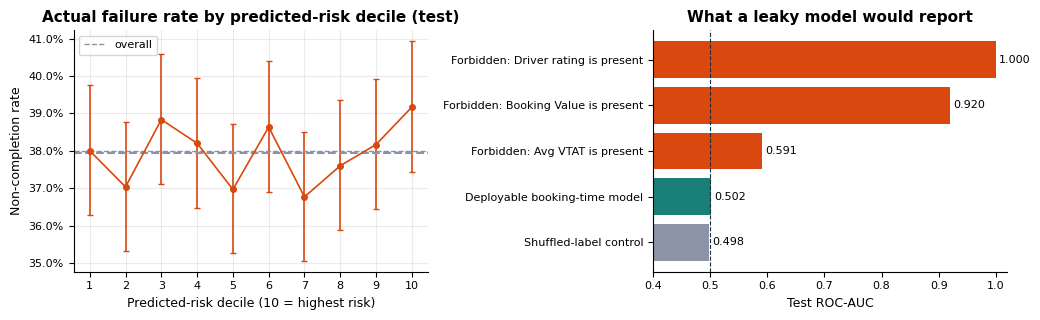

In [33]:
auc_pt, auc_lo, auc_hi = boot_auc(y_test, p_raw_test)
ap_pt = average_precision_score(1 - y_test, 1 - p_raw_test)
rng = np.random.default_rng(SEED)
ap_boot = []
for _ in range(200):
    i = rng.integers(0, len(y_test), len(y_test)); ap_boot.append(average_precision_score(1 - y_test[i], 1 - p_raw_test[i]))
ap_lo, ap_hi = np.quantile(ap_boot, [.025, .975])
shuf = lgb.LGBMClassifier(**{**LGB_BASE, **search.best_params_}).fit(X_fit, np.random.default_rng(SEED).permutation(y_fit))
auc_shuf = roc_auc_score(y_test, shuf.predict_proba(X_test)[:, 1])
# decile lift on test
dec = pd.DataFrame({"risk": 1 - p_raw_test, "nc": 1 - y_test})
dec["decile"] = pd.qcut(dec.risk.rank(method="first"), 10, labels=False) + 1
dtab = rate_table(dec, "decile", "nc")
fig, axs = plt.subplots(1, 2, figsize=(10.5, 3.3))
rate_plot(axs[0], dtab, "Predicted-risk decile (10 = highest risk)", "Actual failure rate by predicted-risk decile (test)", color=C_BAD)
axs[0].axhline(1 - y_test.mean(), color=C_NEUT, ls="--")
leak_rows = {
 "Forbidden: Booking Value is present": roc_auc_score(test.completed, test["Booking Value"].notna()),
 "Forbidden: Avg VTAT is present": roc_auc_score(test.completed, test["Avg VTAT"].notna()),
 "Forbidden: Driver rating is present": roc_auc_score(test.completed, test["Driver Ratings"].notna()),
 "Deployable booking-time model": auc_pt,
 "Shuffled-label control": auc_shuf}
lk = pd.Series(leak_rows).sort_values()
axs[1].barh(lk.index, lk.values, color=[C_BAD if "Forbidden" in i else (C_NEUT if "Shuffled" in i else C_OK) for i in lk.index])
axs[1].axvline(.5, color=C_DARK, lw=.8, ls="--")
for i, v in enumerate(lk.values): axs[1].text(v + .005, i, f"{v:.3f}", va="center", fontsize=8)
axs[1].set_xlim(.4, 1.02); axs[1].set_xlabel("Test ROC-AUC"); axs[1].set_title("What a leaky model would report"); axs[1].grid(False)
plt.tight_layout(); plt.show()
lift_top = dtab.loc[10, "rate"]; lift_bot = dtab.loc[1, "rate"]
slope_p = stats.spearmanr(dtab.index, dtab.rate)[1]

In [34]:
md(f"""**Insight: the honest answer is that there is no usable booking-time signal.**
* Final model test ROC-AUC = **{auc_pt:.3f}** (95% bootstrap CI {auc_lo:.3f} to {auc_hi:.3f}); {'the interval contains 0.5, so it is statistically indistinguishable from random ranking' if auc_lo <= .5 <= auc_hi else 'the interval excludes 0.5, but the effect size is tiny'}.
  PR-AUC for non-completion = {ap_pt:.3f} (CI {ap_lo:.3f} to {ap_hi:.3f}) versus {1-y_test.mean():.3f} for random guessing.
* A model trained on **shuffled labels** scores {auc_shuf:.3f}, the same as the real one: the real model is not learning anything the shuffled one is not.
* Actual failure rates barely move across predicted-risk deciles: {pct(lift_bot)} in the lowest-risk decile versus {pct(lift_top)} in the highest.
* By contrast, the forbidden columns score a ROC-AUC of {leak_rows['Forbidden: Booking Value is present']:.2f} (Booking Value present), {leak_rows['Forbidden: Avg VTAT is present']:.2f} (Avg VTAT present) and {leak_rows['Forbidden: Driver rating is present']:.2f} (rating present) with *no learning at all*. A leaky model would have looked impressive and would have been useless at booking time.

**What this means for the recommendations.** At the moment of booking, the available inputs (time, day, vehicle type, pickup, drop) do not discriminate between rides that will and will not complete. Any intervention that relies on **per-ride risk targeting** would perform like random targeting.
Recommendations in Q1 to Q7 are therefore framed as (a) **portfolio-level** actions that do not need ranking power, (b) **experiments** to run before scaling, and (c) **data to start collecting** so a real risk model becomes possible (e.g. live driver supply nearby, ETA at request, weather, surge multiplier).""")
R.update(auc=auc_pt, auc_lo=auc_lo, auc_hi=auc_hi, auc_shuf=auc_shuf, ap=ap_pt, leak_auc=leak_rows)

**Insight: the honest answer is that there is no usable booking-time signal.**
* Final model test ROC-AUC = **0.502** (95% bootstrap CI 0.495 to 0.508); the interval contains 0.5, so it is statistically indistinguishable from random ranking.
  PR-AUC for non-completion = 0.382 (CI 0.375 to 0.390) versus 0.379 for random guessing.
* A model trained on **shuffled labels** scores 0.498, the same as the real one: the real model is not learning anything the shuffled one is not.
* Actual failure rates barely move across predicted-risk deciles: 38.0% in the lowest-risk decile versus 39.2% in the highest.
* By contrast, the forbidden columns score a ROC-AUC of 0.92 (Booking Value present), 0.59 (Avg VTAT present) and 1.00 (rating present) with *no learning at all*. A leaky model would have looked impressive and would have been useless at booking time.

**What this means for the recommendations.** At the moment of booking, the available inputs (time, day, vehicle type, pickup, drop) do not discriminate between rides that will and will not complete. Any intervention that relies on **per-ride risk targeting** would perform like random targeting.
Recommendations in Q1 to Q7 are therefore framed as (a) **portfolio-level** actions that do not need ranking power, (b) **experiments** to run before scaling, and (c) **data to start collecting** so a real risk model becomes possible (e.g. live driver supply nearby, ETA at request, weather, surge multiplier).

### E2. Explainability: SHAP and permutation importance (with a noise yardstick)
SHAP shows how much each feature moves the model's output. Because a flexible model will always assign *some* importance to *some* features, we add a **pure-noise column** to a copy of the model: any real feature that is not clearly more important than the noise column is not carrying signal. Permutation importance (drop in non-completion PR-AUC on the validation slice when a feature is shuffled) provides that comparison.

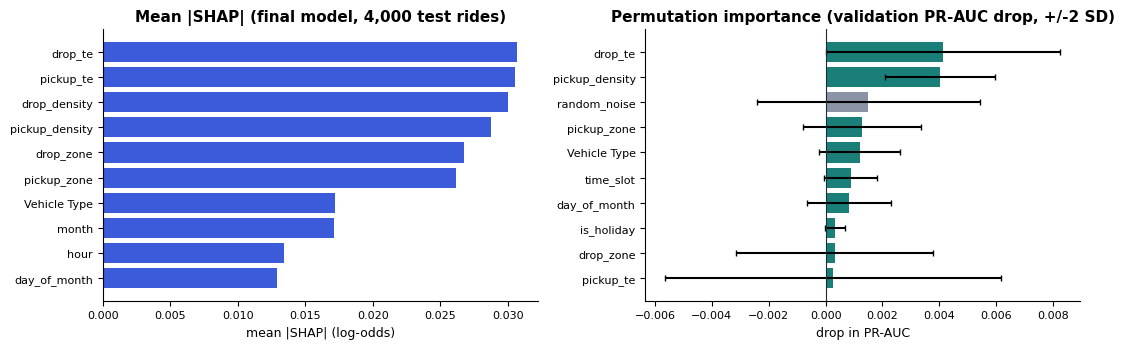

In [35]:
expl = shap.TreeExplainer(final_raw)
Xs = X_test.sample(4000, random_state=SEED)
sv = expl.shap_values(Xs, check_additivity=False)
sv = sv[1] if isinstance(sv, list) else sv
shap_imp = pd.Series(np.abs(sv).mean(0), index=Xs.columns).sort_values(ascending=False)

Xn_fit, Xn_cal = X_fit.assign(random_noise=np.random.default_rng(SEED).normal(size=len(X_fit))), X_cal.assign(random_noise=np.random.default_rng(SEED + 1).normal(size=len(X_cal)))
m_noise = lgb.LGBMClassifier(**{**LGB_BASE, **search.best_params_}).fit(Xn_fit, y_fit)
pi = permutation_importance(m_noise, Xn_cal, y_cal, scoring=ap_nc, n_repeats=5, random_state=SEED, n_jobs=1)
pi = pd.DataFrame({"mean": pi.importances_mean, "sd": pi.importances_std}, index=Xn_cal.columns).sort_values("mean", ascending=False)
noise_hi = pi.loc["random_noise", "mean"] + 2 * pi.loc["random_noise", "sd"]
beats_noise = pi[(pi["mean"] > noise_hi) & (pi.index != "random_noise")]
top = shap_imp.head(10)[::-1]
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
axs[0].barh(top.index, top.values, color=C_ACC); axs[0].set_title("Mean |SHAP| (final model, 4,000 test rides)"); axs[0].set_xlabel("mean |SHAP| (log-odds)"); axs[0].grid(False)
p10 = pi.head(10)[::-1]
axs[1].barh(p10.index, p10["mean"], xerr=2 * p10["sd"], color=[C_NEUT if i == "random_noise" else C_OK for i in p10.index], capsize=2)
axs[1].axvline(0, color=C_DARK, lw=.8); axs[1].set_title("Permutation importance (validation PR-AUC drop, +/-2 SD)"); axs[1].set_xlabel("drop in PR-AUC"); axs[1].grid(False)
plt.tight_layout(); plt.show()
NON_BEHAV_TOP3 = shap_imp.head(3).index.tolist()
R["shap_top3"] = NON_BEHAV_TOP3; R["n_beats_noise"] = len(beats_noise)

In [36]:
md(f"""**Insight.** By mean |SHAP|, the three most influential booking-time features are **{NON_BEHAV_TOP3[0]}**, **{NON_BEHAV_TOP3[1]}** and **{NON_BEHAV_TOP3[2]}** (all non-behavioural: no customer history exists in this data).
However, in the permutation test **{len(beats_noise)} of {X_fit.shape[1]} features** beat the pure-noise column by more than two standard deviations{'' if len(beats_noise)==0 else ' (' + ', '.join(beats_noise.index) + ')'}.
SHAP ranks features by how much the model *uses* them, not by whether using them *helps* out of sample; the high-cardinality location encodings and calendar features are exactly the ones a flexible model can use to memorise noise.
So Q3's booking-time ranking should be read as "where the model looked", not as "what drives failures".""")

**Insight.** By mean |SHAP|, the three most influential booking-time features are **drop_te**, **pickup_te** and **drop_density** (all non-behavioural: no customer history exists in this data).
However, in the permutation test **0 of 19 features** beat the pure-noise column by more than two standard deviations.
SHAP ranks features by how much the model *uses* them, not by whether using them *helps* out of sample; the high-cardinality location encodings and calendar features are exactly the ones a flexible model can use to memorise noise.
So Q3's booking-time ranking should be read as "where the model looked", not as "what drives failures".

### E3. The post-acceptance **diagnostic** model (not deployable)
To answer Q3 and Q4 on levers such as **VTAT, distance and fare**, we build a second, clearly separate model that *is allowed* to see them. **It cannot be deployed**: those values only exist after a driver accepts or the trip starts, and for some outcomes they never exist. Its purpose is purely diagnostic. Three variants separate real signal from missingness leakage:

| Variant | Rows | Question it answers |
|---|---|---|
| **A. Nulls left in** | all rides | What happens when the model is allowed to see `Avg VTAT`, `Ride Distance`, `Booking Value` with their nulls? |
| **A'. Null flags only** | all rides | Same model, but only three "is this value present?" flags (no values at all) |
| **B. VTAT on accepted rides** | rides with a driver (excludes *No Driver Found*) | Is VTAT itself informative, with no missingness to exploit? |
| **C. Distance and fare, Completed vs Incomplete** | rides where both exist | Do trip distance or fare separate finished from abandoned trips? |

,rows (test),test ROC-AUC
A. Nulls left in (leaky),30000,0.983
A'. Null flags only (leaky),30000,0.920
"B. VTAT, accepted rides",27928,0.658
"C. Distance/fare, Completed vs Incomplete",20434,0.892


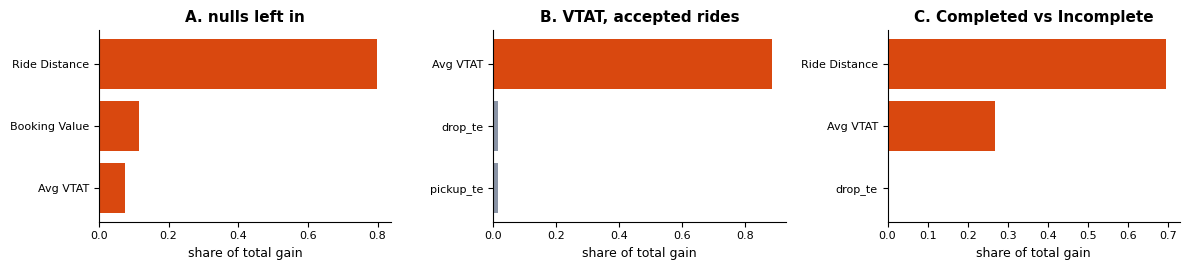

In [37]:
def diag_frame(d, X):
    D = X.copy()
    D["Avg VTAT"] = d["Avg VTAT"].values; D["Ride Distance"] = d["Ride Distance"].values; D["Booking Value"] = d["Booking Value"].values
    return D
Dfit, Dtest = diag_frame(train_fit, X_fit), diag_frame(test, X_test)
P = {**LGB_BASE, **search.best_params_}
def fit_eval(Xa, ya, Xb, yb, cols):
    m_ = lgb.LGBMClassifier(**P).fit(Xa[cols], ya)
    p_ = m_.predict_proba(Xb[cols])[:, 1]
    return m_, roc_auc_score(yb, p_), p_
base_cols = list(X_fit.columns)
res = {}
mA, aA, _ = fit_eval(Dfit, y_fit, Dtest, y_test, base_cols + ["Avg VTAT", "Ride Distance", "Booking Value"])
flagsF = Dfit.assign(f_vtat=Dfit["Avg VTAT"].notna().astype(int), f_dist=Dfit["Ride Distance"].notna().astype(int), f_val=Dfit["Booking Value"].notna().astype(int))
flagsT = Dtest.assign(f_vtat=Dtest["Avg VTAT"].notna().astype(int), f_dist=Dtest["Ride Distance"].notna().astype(int), f_val=Dtest["Booking Value"].notna().astype(int))
mA2, aA2, _ = fit_eval(flagsF, y_fit, flagsT, y_test, base_cols + ["f_vtat", "f_dist", "f_val"])
fa, ta = Dfit["Avg VTAT"].notna().values, Dtest["Avg VTAT"].notna().values
mB, aB, _ = fit_eval(Dfit[fa], y_fit[fa], Dtest[ta], y_test[ta], base_cols + ["Avg VTAT"])
fc, tc = Dfit["Booking Value"].notna().values, Dtest["Booking Value"].notna().values
mC, aC, _ = fit_eval(Dfit[fc], y_fit[fc], Dtest[tc], y_test[tc], base_cols + ["Avg VTAT", "Ride Distance", "Booking Value"])
diag = pd.DataFrame({"rows (test)": [len(Dtest), len(Dtest), ta.sum(), tc.sum()],
                     "test ROC-AUC": [aA, aA2, aB, aC]},
                    index=["A. Nulls left in (leaky)", "A'. Null flags only (leaky)", "B. VTAT, accepted rides", "C. Distance/fare, Completed vs Incomplete"])
display(diag.round(3))
def top_gain(m_, cols, k=3):
    g = pd.Series(m_.booster_.feature_importance("gain"), index=cols).sort_values(ascending=False)
    return (g / g.sum()).head(k)
gA, gB, gC = (top_gain(mA, base_cols + ["Avg VTAT", "Ride Distance", "Booking Value"]), top_gain(mB, base_cols + ["Avg VTAT"]),
              top_gain(mC, base_cols + ["Avg VTAT", "Ride Distance", "Booking Value"]))
fig, axs = plt.subplots(1, 3, figsize=(12, 2.8))
for ax, g_, t in zip(axs, (gA, gB, gC), ("A. nulls left in", "B. VTAT, accepted rides", "C. Completed vs Incomplete")):
    ax.barh(g_.index[::-1], g_.values[::-1], color=[C_BAD if i in ("Avg VTAT", "Ride Distance", "Booking Value") else C_NEUT for i in g_.index[::-1]])
    ax.set_title(t); ax.set_xlabel("share of total gain"); ax.grid(False)
plt.tight_layout(); plt.show()
R["diag"] = diag; R["gB"] = gB; R["gC"] = gC; R["gA"] = gA

In [38]:
vt_acc = df[df["Avg VTAT"].notna()]
md(f"""**Insight.**
* **Variant A reaches ROC-AUC {aA:.2f}**, and the variant that sees *only three present/absent flags* reaches {aA2:.2f}: **{(aA2-.5)/(aA-.5):.0%} of A's lift over chance is missingness leakage** (whether a value exists), and only the remainder comes from the values themselves. The Approach Document's `Is_..._Available` flag idea would produce exactly this inflated score.
* **Variant B (VTAT on accepted rides, no missingness)** reaches ROC-AUC {aB:.3f}: VTAT is {'a real but modest' if aB > .55 else 'not a'} signal once nulls are removed. Its gain share is {gB.iloc[0]:.0%} for **{gB.index[0]}**.
* **Variant C (Completed vs Incomplete)** reaches ROC-AUC {aC:.3f}; the top drivers are **{', '.join(gC.index[:3])}**. Incomplete rides cover a much shorter distance (mean {df.loc[df['Booking Status']=='Incomplete','Ride Distance'].mean():.1f} km vs {df.loc[df['Booking Status']=='Completed','Ride Distance'].mean():.1f} km for completed), which is what an abandoned trip looks like.
  Because the column is recorded for trips that already started, this reflects *how far the trip got*, not a pre-trip estimate, so it cannot be turned into a booking-time feature.
* Booking Value is uncorrelated with distance in this data (Pearson r = {df[['Booking Value','Ride Distance']].corr().iloc[0,1]:.3f} on {df[['Booking Value','Ride Distance']].dropna().shape[0]:,} rides), another sign the fare field behaves like random noise rather than a distance-based tariff.""")

**Insight.**
* **Variant A reaches ROC-AUC 0.98**, and the variant that sees *only three present/absent flags* reaches 0.92: **87% of A's lift over chance is missingness leakage** (whether a value exists), and only the remainder comes from the values themselves. The Approach Document's `Is_..._Available` flag idea would produce exactly this inflated score.
* **Variant B (VTAT on accepted rides, no missingness)** reaches ROC-AUC 0.658: VTAT is a real but modest signal once nulls are removed. Its gain share is 89% for **Avg VTAT**.
* **Variant C (Completed vs Incomplete)** reaches ROC-AUC 0.892; the top drivers are **Ride Distance, Avg VTAT, drop_te**. Incomplete rides cover a much shorter distance (mean 10.5 km vs 26.0 km for completed), which is what an abandoned trip looks like.
  Because the column is recorded for trips that already started, this reflects *how far the trip got*, not a pre-trip estimate, so it cannot be turned into a booking-time feature.
* Booking Value is uncorrelated with distance in this data (Pearson r = 0.005 on 102,000 rides), another sign the fare field behaves like random noise rather than a distance-based tariff.

### E3b. Prediction at acceptance: diagnostic variant B as a second, clearly labelled model
The Approach Document speaks of predicting "once accepted", while the problem statement says "at the time of booking". The headline model follows the problem statement. Variant B is the acceptance-time counterpart: **it is a second model, not the deployable one**. It uses the booking-time features plus `Avg VTAT` (recorded when a driver accepts), so it applies only to **accepted rides** (it excludes *No Driver Found*, which never reaches acceptance). Threshold: F1-optimal for the non-completed class on the validation slice, then applied unchanged to the test period.

In [39]:
Dcal = diag_frame(cal, X_cal)
mk_c, mk_t = Dcal["Avg VTAT"].notna().values, Dtest["Avg VTAT"].notna().values
colsB = base_cols + ["Avg VTAT"]
pB_cal, pB_test = mB.predict_proba(Dcal[mk_c][colsB])[:, 1], mB.predict_proba(Dtest[mk_t][colsB])[:, 1]
yB_cal, yB_test = y_cal[mk_c], y_test[mk_t]
gridB = thr_grid(pB_cal)
thrB = gridB[np.argmax([f1_nc_at(yB_cal, pB_cal, t) for t in gridB])]
predB = (pB_test >= thrB).astype(int)
aucB_pt, aucB_lo, aucB_hi = boot_auc(yB_test, pB_test)
apB = average_precision_score(1 - yB_test, 1 - pB_test)
flag_t = (p_raw_test < t_topk); pred_t = (~flag_t).astype(int)
cmp_b = pd.DataFrame({
    "Booking-time model (deployable)": [f"{auc_pt:.3f} ({auc_lo:.3f} to {auc_hi:.3f})", f"{ap_pt:.3f}", f"{1-y_test.mean():.3f}", f"{f1_score(y_test, pred_t, pos_label=0):.3f}", f"{f1_score(y_test, pred_t, pos_label=1):.3f}", f"{f1_score(y_test, pred_t, average='macro'):.3f}", f"{len(y_test):,}"],
    "Acceptance-time model B (diagnostic)": [f"{aucB_pt:.3f} ({aucB_lo:.3f} to {aucB_hi:.3f})", f"{apB:.3f}", f"{1-yB_test.mean():.3f}", f"{f1_score(yB_test, predB, pos_label=0):.3f}", f"{f1_score(yB_test, predB, pos_label=1):.3f}", f"{f1_score(yB_test, predB, average='macro'):.3f}", f"{len(yB_test):,}"]},
    index=["ROC-AUC (95% CI)", "PR-AUC, non-completed", "non-completion rate (= random PR-AUC)", "F1, non-completed", "F1, completed", "Macro F1", "test rides"])
display(cmp_b)

,Booking-time model (deployable),Acceptance-time model B (diagnostic)
ROC-AUC (95% CI),0.502 (0.495 to 0.508),0.658 (0.651 to 0.664)
"PR-AUC, non-completed",0.382,0.503
non-completion rate (= random PR-AUC),0.379,0.333
"F1, non-completed",0.385,0.557
"F1, completed",0.616,0.448
Macro F1,0.500,0.502
test rides,"30,000","27,928"


In [40]:
md(f"""**Insight.** Once `Avg VTAT` is known, ROC-AUC rises from {auc_pt:.3f} (booking time) to **{aucB_pt:.3f}** (CI {aucB_lo:.3f} to {aucB_hi:.3f}) and non-completion PR-AUC from {ap_pt:.3f} to **{apB:.3f}** against a {1-yB_test.mean():.3f} random level; F1 for the non-completed class is {f1_score(yB_test, predB, pos_label=0):.3f} (macro F1 {f1_score(yB_test, predB, average='macro'):.3f}) at the validation-chosen threshold.
This is the only real lift in the notebook, and it appears only at acceptance, which is why the headline model stays booking-time and VTAT is treated as a dispatch lever (Q3) rather than a booking-time feature. **⚠ Synthetic-data caution:** VTAT's per-outcome ranges are sharply separated (customer cancellations 5 to 20 min, driver cancellations 3 to 12, completed 2 to 15, incomplete 2 to 10), which real operations rarely show, so expect a smaller lift in live data.""")

**Insight.** Once `Avg VTAT` is known, ROC-AUC rises from 0.502 (booking time) to **0.658** (CI 0.651 to 0.664) and non-completion PR-AUC from 0.382 to **0.503** against a 0.333 random level; F1 for the non-completed class is 0.557 (macro F1 0.502) at the validation-chosen threshold.
This is the only real lift in the notebook, and it appears only at acceptance, which is why the headline model stays booking-time and VTAT is treated as a dispatch lever (Q3) rather than a booking-time feature. **⚠ Synthetic-data caution:** VTAT's per-outcome ranges are sharply separated (customer cancellations 5 to 20 min, driver cancellations 3 to 12, completed 2 to 15, incomplete 2 to 10), which real operations rarely show, so expect a smaller lift in live data.

### E4. Error analysis and what-if simulations
**Error analysis** at the equal-volume operating point (flag the highest-risk 38% of rides). The Approach Document argues a *false positive* (we say "will complete", it fails) is costlier than a *false negative* (we raise an alarm, it completes), so precision of the "will complete" call matters most. **What-if** simulations then quantify two of its proposed interventions using the model's actual scores.

In [41]:
flag = (p_raw_test < t_topk)                      # flagged as high risk (predict non-completion)
actual_fail = (y_test == 0)
tp = (flag & actual_fail).sum(); fp_alarm = (flag & ~actual_fail).sum()
missed = (~flag & actual_fail).sum(); tn = (~flag & ~actual_fail).sum()
prec_nc, rec_nc = tp / flag.sum(), tp / actual_fail.sum()
prec_c = tn / (~flag).sum()
cm = pd.DataFrame({"flagged high-risk": [tp, fp_alarm], "not flagged": [missed, tn]},
                  index=["actually failed", "actually completed"])
display(cm.map(lambda v: f"{v:,}"))
# what-if 1: dispatch penalty / intervention for rides with predicted risk > 0.8 (calibrated)
risk_cal = 1 - p_test
n_over_08 = int((risk_cal > .8).sum())
# what-if 2: targeted intervention that cuts failure probability by 10% (relative) for the top-risk decile
top_dec = dec.decile == 10
fails_top = int(dec.loc[top_dec, "nc"].sum()); fails_all = int(dec.nc.sum())
saved_targeted = .10 * fails_top
saved_random = .10 * fails_all * top_dec.mean()

,flagged high-risk,not flagged
actually failed,"4,436","6,945"
actually completed,"7,250","11,369"


In [42]:
md(f"""**Insight.** At the equal-volume operating point the alarm is right {pct(prec_nc)} of the time (precision for non-completion; the base rate is {pct(actual_fail.mean())}) and catches {pct(rec_nc)} of failures (recall).
The "will complete" call (the one the Approach Document wants to be precise) is right {pct(prec_c)} of the time against a {pct(1-actual_fail.mean())} base rate. Neither is meaningfully better than chance, consistent with E1.

**What-if 1: dispatch penalty for predicted risk above 0.8.** Only **{n_over_08:,} of {len(risk_cal):,}** test rides ({pct(n_over_08/len(risk_cal))}) have a calibrated failure risk above 0.8, so the policy would almost never fire and its revenue effect is nil with the current inputs.
**What-if 2: a 10% cut in failure probability for the top-risk decile.** Targeted by the model it saves ~{saved_targeted:.0f} rides over the {len(dec):,}-ride test period; picking the same number of rides at random would save ~{saved_random:.0f}, so **the model adds {saved_targeted-saved_random:+.0f} rides** over random targeting.
An intervention across *all* rides that cut failures by 10% relative would save ~{.10*fails_all:.0f} rides, which is why portfolio-level actions, not per-ride targeting, are recommended until better inputs exist.""")
R["prec_nc"], R["rec_nc"] = prec_nc, rec_nc

**Insight.** At the equal-volume operating point the alarm is right 38.0% of the time (precision for non-completion; the base rate is 37.9%) and catches 39.0% of failures (recall).
The "will complete" call (the one the Approach Document wants to be precise) is right 62.1% of the time against a 62.1% base rate. Neither is meaningfully better than chance, consistent with E1.

**What-if 1: dispatch penalty for predicted risk above 0.8.** Only **0 of 30,000** test rides (0.0%) have a calibrated failure risk above 0.8, so the policy would almost never fire and its revenue effect is nil with the current inputs.
**What-if 2: a 10% cut in failure probability for the top-risk decile.** Targeted by the model it saves ~118 rides over the 30,000-ride test period; picking the same number of rides at random would save ~114, so **the model adds +4 rides** over random targeting.
An intervention across *all* rides that cut failures by 10% relative would save ~1138 rides, which is why portfolio-level actions, not per-ride targeting, are recommended until better inputs exist.

## Business questions
Each section below follows the same pattern: **analysis, chart or table, Insight, Recommendation with expected impact**. Rates use the full-year data (150,000 rides) unless stated; the denominator is shown wherever a column has nulls. Differences are called "significant" only when they survive a chi-square or permutation test or when confidence intervals clearly separate.

## Q1. When is CTAT highest and completion lowest, and what surge / incentive design fits?
**Method.** For every hour and weekday we compute (i) the average CTAT (Average Customer Travel Time to Acceptance: per the Dataset Description, the average time a driver takes to reach the customer after acceptance), **only over rides where CTAT exists** (Completed and Incomplete rides, shown as *n* beside each figure), and (ii) the completion rate over **all** rides. Slots are then ranked, and we test whether the best and worst slots differ from what chance would give.

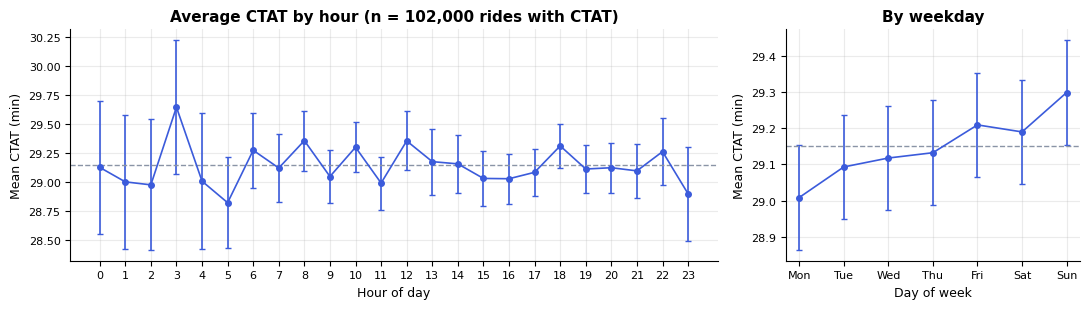

,rides,completion,CI,mean CTAT,n with CTAT
Sat 01:00,201,55.2%,48.3% to 61.9%,28.7,125
Mon 01:00,209,56.5%,49.7% to 63.0%,29.6,127
Sat 14:00,1036,58.1%,55.1% to 61.1%,28.9,670
Sat 05:00,412,58.3%,53.4% to 62.9%,28.4,267
Tue 13:00,753,58.3%,54.7% to 61.8%,29.2,480


,rides,completion,CI,mean CTAT,n with CTAT
Sat 03:00,190,64.2%,57.2% to 70.7%,31.2,129
Fri 04:00,204,61.8%,54.9% to 68.2%,30.4,132
Tue 02:00,206,65.5%,58.8% to 71.7%,30.3,146
Wed 00:00,208,61.5%,54.8% to 67.9%,30.2,134
Wed 13:00,793,64.6%,61.2% to 67.8%,30.1,557


In [43]:
ct = df.dropna(subset=["Avg CTAT"])
def mean_ci(d, by, col):
    g = d.groupby(by)[col].agg(["mean", "std", "count"])
    g["lo"] = g["mean"] - 1.96 * g["std"] / np.sqrt(g["count"]); g["hi"] = g["mean"] + 1.96 * g["std"] / np.sqrt(g["count"])
    return g
ctat_h, ctat_d = mean_ci(ct, "hour", "Avg CTAT"), mean_ci(ct, "dow", "Avg CTAT")
p_ctat_h = stats.kruskal(*[g["Avg CTAT"].values for _, g in ct.groupby("hour")])[1]
p_ctat_d = stats.kruskal(*[g["Avg CTAT"].values for _, g in ct.groupby("dow")])[1]
fig, axs = plt.subplots(1, 2, figsize=(11, 3.2), gridspec_kw={"width_ratios": [2.2, 1]})
for ax, t, xl, lab in [(axs[0], ctat_h, "Hour of day", None), (axs[1], ctat_d, "Day of week", ["Mon","Tue","Wed","Thu","Fri","Sat","Sun"])]:
    x = np.arange(len(t)); ax.errorbar(x, t["mean"], yerr=[t["mean"] - t["lo"], t["hi"] - t["mean"]], fmt="o-", color=C_ACC, ms=4, capsize=2, lw=1.2)
    ax.axhline(ct["Avg CTAT"].mean(), color=C_NEUT, ls="--", lw=1); ax.set_xticks(x); ax.set_xticklabels(lab if lab else t.index)
    ax.set_xlabel(xl); ax.set_ylabel("Mean CTAT (min)")
axs[0].set_title(f"Average CTAT by hour (n = {len(ct):,} rides with CTAT)"); axs[1].set_title("By weekday")
plt.tight_layout(); plt.show()

slot = df.groupby(["dow", "hour"]).agg(rides=("completed", "size"), completed=("completed", "sum"), ctat=("Avg CTAT", "mean"), n_ctat=("Avg CTAT", "count"))
slot["completion"] = slot.completed / slot.rides
slot["lo"], slot["hi"] = wilson(slot.completed, slot.rides)
slot.index = [f"{['Mon','Tue','Wed','Thu','Fri','Sat','Sun'][d]} {h:02d}:00" for d, h in slot.index]
low5 = slot.sort_values("completion").head(5); hi5 = slot.sort_values("ctat", ascending=False).head(5)
fmt = lambda t: t.assign(completion=t.completion.map(pct), CI=[f"{pct(a)} to {pct(b)}" for a, b in zip(t.lo, t.hi)], ctat=t.ctat.round(1))[["rides", "completion", "CI", "ctat", "n_ctat"]]
display(fmt(low5).rename(columns={"ctat": "mean CTAT", "n_ctat": "n with CTAT"}).style.format({"mean CTAT": "{:.1f}"}).set_caption("Five lowest-completion slots"))
display(fmt(hi5).rename(columns={"ctat": "mean CTAT", "n_ctat": "n with CTAT"}).style.format({"mean CTAT": "{:.1f}"}).set_caption("Five highest-CTAT slots"))
bad_c = set(slot.completion.nsmallest(17).index); bad_t = set(slot.ctat.nlargest(17).index)
overlap = len(bad_c & bad_t); exp_overlap = 17 * 17 / len(slot)
gain_1pp = 0.01 * low5.rides.sum()

In [44]:
pc = perm_test(pd.factorize(df.assign(c=df.dow * 24 + df.hour)["c"])[0], df.completed.values)
md(f"""**Insight.** The lowest-completion slot ({low5.index[0]}) completes {pct(low5.completion.iloc[0])} of its {int(low5.rides.iloc[0])} rides versus {pct(df.completed.mean())} overall, and its 95% interval ({pct(low5.lo.iloc[0])} to {pct(low5.hi.iloc[0])}) {'lies marginally below the overall rate when taken on its own' if low5.hi.iloc[0] < df.completed.mean() else 'still overlaps the overall rate'}, but it is not distinguishable from chance once all 168 slots are considered: the permutation test on the *worst* slot gives p {pv(pc['p_min'])}, so with 168 slots one this low is normal.
CTAT averages {ct['Avg CTAT'].mean():.1f} min overall; the slowest hour is {int(ctat_h['mean'].idxmax()):02d}:00 at {ctat_h['mean'].max():.1f} min and the fastest is {int(ctat_h['mean'].idxmin()):02d}:00 at {ctat_h['mean'].min():.1f} min, and CTAT does not differ significantly across hours (Kruskal-Wallis p = {p_ctat_h:.2f}) or weekdays (p = {p_ctat_d:.2f}).
The 17 worst-completion slots and the 17 highest-CTAT slots overlap in {overlap} slots, against {exp_overlap:.1f} expected by chance: **no slot is simultaneously slow and failing**.""")
md(f"""**Recommendation (Q1) and expected impact.**
1. **Do not hard-wire surge multipliers or incentive pools to particular hours or weekdays.** The data does not identify any slot whose supply problem is distinguishable from noise; a fixed "Friday 6 PM" rule would spend money on a pattern that is not there.
2. **Use a live, trigger-based design instead:** raise incentives or surge only when *real-time* supply signals deteriorate (searching-to-available-driver ratio, pickup ETA above a threshold), capped by a budget and ended automatically when the ratio recovers. This needs no historical slot pattern.
3. **Validate with a holdout.** Run the incentive in randomly chosen half of the weakest slots for 4 weeks; scale only if the completion lift is statistically significant.
4. **Size of the prize** (upper bound, from the table above): every 1 percentage-point lift in completion in the five weakest slots is worth about {gain_1pp:.0f} extra completed rides per year, or roughly Rs {gain_1pp * V:,.0f} of booking value at Rs {V:,.0f} per ride. Applied platform-wide, 1 point is {0.01*len(df):,.0f} rides and Rs {0.01*len(df)*V:,.0f}.
Slot-level targeting is therefore a **hypothesis to test**, not an established lever.""")

n_arm = int(2 * (1.96 + 0.84) ** 2 * df.completed.mean() * (1 - df.completed.mean()) / .01 ** 2)
trig = pd.DataFrame([
 ("Trigger metric", "Open requests per idle driver within 3 km, 5-minute rolling, per zone (live); fallback: median offered ETA"),
 ("Threshold (calibrate in the pilot)", "Ratio above 1.5 for two consecutive windows, or median offered ETA above 14 min (the level where customer cancellations rise sharply in Q3). Both values are design proposals, not estimates from this data"),
 ("Action", "Tiered driver bonus for accepting in the triggered zone; surge only if the ratio stays above the threshold after incentives"),
 ("Budget cap", f"Break-even: each 1 point of completion gained is worth Rs {0.01*V:.1f} per request (mean fare Rs {V:,.0f}), so spend per request in triggered windows must stay below that times the expected lift in points; add a daily ceiling set with finance"),
 ("Stop rule", "Stop when the ratio is below threshold for three consecutive windows, when the daily cap is reached, or when the 4-week readout shows a completion-lift interval that includes zero"),
 ("Holdout", f"Randomise 50% of triggered zone-hours to no incentive; primary metric completion rate; about {n_arm:,} requests per arm to detect a 1-point lift (80% power, 5% significance)")],
 columns=["Element", "Live incentive trigger (design proposal, thresholds illustrative)"])
md(trig.to_markdown(index=False))
R["q1_p_cell"] = pc["p_min"]; R["q1_gain_1pp_platform"] = 0.01 * len(df) * V

**Insight.** The lowest-completion slot (Sat 01:00) completes 55.2% of its 201 rides versus 62.0% overall, and its 95% interval (48.3% to 61.9%) lies marginally below the overall rate when taken on its own, but it is not distinguishable from chance once all 168 slots are considered: the permutation test on the *worst* slot gives p = 0.67, so with 168 slots one this low is normal.
CTAT averages 29.1 min overall; the slowest hour is 03:00 at 29.6 min and the fastest is 05:00 at 28.8 min, and CTAT does not differ significantly across hours (Kruskal-Wallis p = 0.39) or weekdays (p = 0.14).
The 17 worst-completion slots and the 17 highest-CTAT slots overlap in 2 slots, against 1.7 expected by chance: **no slot is simultaneously slow and failing**.

**Recommendation (Q1) and expected impact.**
1. **Do not hard-wire surge multipliers or incentive pools to particular hours or weekdays.** The data does not identify any slot whose supply problem is distinguishable from noise; a fixed "Friday 6 PM" rule would spend money on a pattern that is not there.
2. **Use a live, trigger-based design instead:** raise incentives or surge only when *real-time* supply signals deteriorate (searching-to-available-driver ratio, pickup ETA above a threshold), capped by a budget and ended automatically when the ratio recovers. This needs no historical slot pattern.
3. **Validate with a holdout.** Run the incentive in randomly chosen half of the weakest slots for 4 weeks; scale only if the completion lift is statistically significant.
4. **Size of the prize** (upper bound, from the table above): every 1 percentage-point lift in completion in the five weakest slots is worth about 26 extra completed rides per year, or roughly Rs 13,218 of booking value at Rs 506 per ride. Applied platform-wide, 1 point is 1,500 rides and Rs 759,374.
Slot-level targeting is therefore a **hypothesis to test**, not an established lever.

| Element                            | Live incentive trigger (design proposal, thresholds illustrative)                                                                                                                                                                    |
|:-----------------------------------|:-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|
| Trigger metric                     | Open requests per idle driver within 3 km, 5-minute rolling, per zone (live); fallback: median offered ETA                                                                                                                           |
| Threshold (calibrate in the pilot) | Ratio above 1.5 for two consecutive windows, or median offered ETA above 14 min (the level where customer cancellations rise sharply in Q3). Both values are design proposals, not estimates from this data                          |
| Action                             | Tiered driver bonus for accepting in the triggered zone; surge only if the ratio stays above the threshold after incentives                                                                                                          |
| Budget cap                         | Break-even: each 1 point of completion gained is worth Rs 5.1 per request (mean fare Rs 506), so spend per request in triggered windows must stay below that times the expected lift in points; add a daily ceiling set with finance |
| Stop rule                          | Stop when the ratio is below threshold for three consecutive windows, when the daily cap is reached, or when the 4-week readout shows a completion-lift interval that includes zero                                                  |
| Holdout                            | Randomise 50% of triggered zone-hours to no incentive; primary metric completion rate; about 36,942 requests per arm to detect a 1-point lift (80% power, 5% significance)                                                           |

## Q2. Which zones drive the highest cancellation and "No Driver Found" rates?
**Method.** Each pickup location is mapped to one of ten zones (Appendix A). For each zone we compute the **cancellation rate** (driver + customer cancellations) and the **No Driver Found rate** as a share of all requests in the zone, with Wilson 95% intervals. A zone is marked **significant** only if its interval excludes the platform-wide rate. **Faridabad contains a single pickup location and is shown but excluded from rankings** (too small for reliable rates).

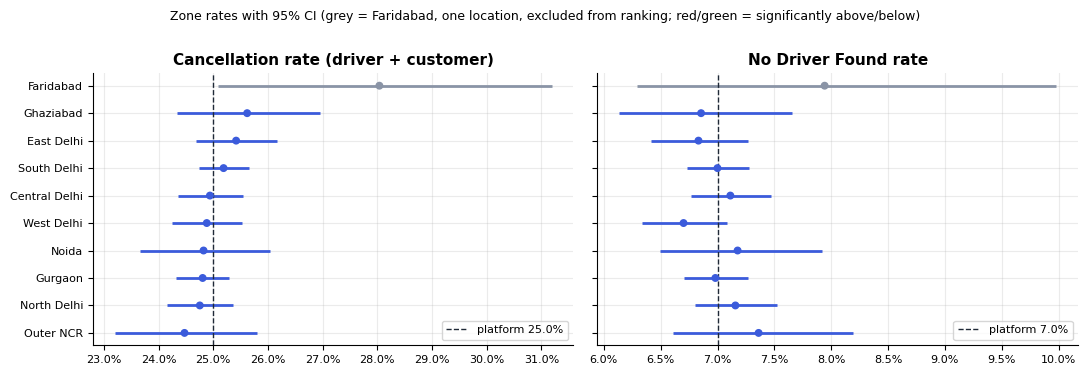

,rides,locations,cancel rate,cancel CI,cancel vs avg,NDF rate,NDF vs avg
pickup_zone,,,,,,,
Ghaziabad,4274,5,25.6%,24.3% to 27.0%,not significant,6.9%,not significant
East Delhi,13392,16,25.4%,24.7% to 26.2%,not significant,6.8%,not significant
South Delhi,34059,40,25.2%,24.7% to 25.7%,not significant,7.0%,not significant
Central Delhi,20554,24,24.9%,24.4% to 25.5%,not significant,7.1%,not significant
West Delhi,17266,20,24.9%,24.2% to 25.5%,not significant,6.7%,not significant
Noida,5072,6,24.8%,23.7% to 26.0%,not significant,7.2%,not significant
Gurgaon,30654,36,24.8%,24.3% to 25.3%,not significant,7.0%,not significant
North Delhi,19714,23,24.8%,24.2% to 25.4%,not significant,7.2%,not significant
Outer NCR,4184,5,24.5%,23.2% to 25.8%,not significant,7.4%,not significant


In [45]:
ZONE_ORDER_EXCL = [z for z in ZONE_FINE if z != "Faridabad"]
def zone_table(col):
    t = rate_table(df, "pickup_zone", col); ov = df[col].mean()
    t["sig"] = np.where((t.lo > ov), "higher", np.where(t.hi < ov, "lower", "not significant"))
    return t, ov
tc, ov_c = zone_table("cancelled"); tn, ov_n = zone_table("no_driver")
zt = pd.DataFrame({"rides": tc.n, "locations": df.groupby("pickup_zone")["Pickup Location"].nunique(),
                   "cancel rate": tc.rate, "cancel CI": [f"{pct(a)} to {pct(b)}" for a, b in zip(tc.lo, tc.hi)], "cancel vs avg": tc.sig,
                   "NDF rate": tn.rate, "NDF CI": [f"{pct(a)} to {pct(b)}" for a, b in zip(tn.lo, tn.hi)], "NDF vs avg": tn.sig})
zt.loc["Faridabad", ["cancel vs avg", "NDF vs avg"]] = "too small for reliable rates"
rank_c = zt.loc[ZONE_ORDER_EXCL].sort_values("cancel rate", ascending=False)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.7), sharey=True)
order = rank_c.index.tolist()[::-1] + ["Faridabad"]
for ax, t, ov, ttl in [(axs[0], tc, ov_c, "Cancellation rate (driver + customer)"), (axs[1], tn, ov_n, "No Driver Found rate")]:
    y = np.arange(len(order)); tt = t.loc[order]
    cols = [C_NEUT if z == "Faridabad" else (C_BAD if s == "higher" else C_OK if s == "lower" else C_ACC) for z, s in zip(order, tt.sig)]
    ax.hlines(y, tt.lo, tt.hi, color=cols, lw=2); ax.scatter(tt.rate, y, color=cols, zorder=3, s=22)
    ax.axvline(ov, color=C_DARK, ls="--", lw=1, label=f"platform {pct(ov)}"); ax.set_yticks(y); ax.set_yticklabels(order)
    ax.set_title(ttl); ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1%}")); ax.legend(loc="lower right")
fig.suptitle("Zone rates with 95% CI (grey = Faridabad, one location, excluded from ranking; red/green = significantly above/below)", fontsize=9, y=1.0)
plt.tight_layout(); plt.show()
display(zt.loc[rank_c.index.tolist() + ["Faridabad"]].assign(**{"cancel rate": zt["cancel rate"].map(pct), "NDF rate": zt["NDF rate"].map(pct)})[
    ["rides", "locations", "cancel rate", "cancel CI", "cancel vs avg", "NDF rate", "NDF vs avg"]])
p_zc = chi2_p(df[df.pickup_zone != "Faridabad"], "pickup_zone", "cancelled"); p_zn = chi2_p(df[df.pickup_zone != "Faridabad"], "pickup_zone", "no_driver")
# stability: are the high-risk locations of the training period still high-risk in the test period?
l_tr = train.groupby("Pickup Location").non_completed.mean(); l_te = test.groupby("Pickup Location").non_completed.mean()
rho, p_rho = stats.spearmanr(l_tr, l_te.reindex(l_tr.index))
z_tr = train.groupby("pickup_zone").non_completed.mean().drop("Faridabad"); z_te = test.groupby("pickup_zone").non_completed.mean().drop("Faridabad")
rho_z, p_rho_z = stats.spearmanr(z_tr, z_te.reindex(z_tr.index))
risk_by_zone = pd.Series(1 - p_raw_test, index=test.index).groupby(test.pickup_zone).mean()

In [46]:
n_sig_c = int((zt.loc[ZONE_ORDER_EXCL, "cancel vs avg"] != "not significant").sum()); n_sig_n = int((zt.loc[ZONE_ORDER_EXCL, "NDF vs avg"] != "not significant").sum())
top_c, top_n = rank_c.index[0], zt.loc[ZONE_ORDER_EXCL].sort_values("NDF rate", ascending=False).index[0]
md(f"""**Insight.** Cancellation rates run from {pct(zt.loc[ZONE_ORDER_EXCL,'cancel rate'].min())} to {pct(zt.loc[ZONE_ORDER_EXCL,'cancel rate'].max())} across the nine rankable zones (platform {pct(ov_c)}); the highest is **{top_c}** ({pct(rank_c['cancel rate'].iloc[0])}), and No Driver Found runs from {pct(zt.loc[ZONE_ORDER_EXCL,'NDF rate'].min())} to {pct(zt.loc[ZONE_ORDER_EXCL,'NDF rate'].max())}, highest in **{top_n}**.
**{n_sig_c} of 9 zones differ significantly on cancellation and {n_sig_n} of 9 on No Driver Found.** Chi-square tests across zones give p = {p_zc:.2f} (cancellation) and p = {p_zn:.2f} (No Driver Found); the zone ranking above is therefore not distinguishable from noise.
Persistence check: location-level non-completion in the training months correlates {rho:+.2f} with the test months (Spearman p = {p_rho:.2f}), and the zone-level correlation is {rho_z:+.2f} (p = {p_rho_z:.2f}). "High-risk" zones do not stay high-risk. The model's average raw (class-weighted) risk score by zone spans only {pct(risk_by_zone.min())} to {pct(risk_by_zone.max())}, so it cannot rank zones either.""")
md(f"""**Recommendation (Q2) and expected impact.**
1. **No zone-specific dispatch priority or premium driver pool is justified by this data.** Re-allocating the best drivers to a zone chosen from a ranking that does not persist from one quarter to the next would move supply with no expected gain.
2. **Make zone prioritisation dynamic.** Weight dispatch priority by *current* supply-demand imbalance (open requests per idle driver within 3 km) and refresh it every few minutes; the model's role is to score that imbalance once it is available as an input.
3. **Monitor, with guard-rails.** Track each zone's 4-week rolling cancellation and No Driver Found rates with confidence intervals and trigger action only when a zone's interval stays above the platform rate for several consecutive weeks (the evidence that would justify a static high-risk list).
4. **Impact if a real hot zone is found:** each 1-point reduction in No Driver Found in a zone of N rides recovers 0.01 x N rides; for the largest zone ({zt.loc[ZONE_ORDER_EXCL,'rides'].idxmax()}, {int(zt.loc[ZONE_ORDER_EXCL,'rides'].max()):,} rides/year) that is about {0.01*zt.loc[ZONE_ORDER_EXCL,'rides'].max():.0f} rides, or Rs {0.01*zt.loc[ZONE_ORDER_EXCL,'rides'].max()*V:,.0f} per year.""")
R.update(q2_p_cancel=p_zc, q2_p_ndf=p_zn, q2_rho=rho, q2_top_c=top_c, q2_top_n=top_n)

**Insight.** Cancellation rates run from 24.5% to 25.6% across the nine rankable zones (platform 25.0%); the highest is **Ghaziabad** (25.6%), and No Driver Found runs from 6.7% to 7.4%, highest in **Outer NCR**.
**0 of 9 zones differ significantly on cancellation and 0 of 9 on No Driver Found.** Chi-square tests across zones give p = 0.77 (cancellation) and p = 0.72 (No Driver Found); the zone ranking above is therefore not distinguishable from noise.
Persistence check: location-level non-completion in the training months correlates +0.03 with the test months (Spearman p = 0.72), and the zone-level correlation is -0.53 (p = 0.14). "High-risk" zones do not stay high-risk. The model's average raw (class-weighted) risk score by zone spans only 47.9% to 51.4%, so it cannot rank zones either.

**Recommendation (Q2) and expected impact.**
1. **No zone-specific dispatch priority or premium driver pool is justified by this data.** Re-allocating the best drivers to a zone chosen from a ranking that does not persist from one quarter to the next would move supply with no expected gain.
2. **Make zone prioritisation dynamic.** Weight dispatch priority by *current* supply-demand imbalance (open requests per idle driver within 3 km) and refresh it every few minutes; the model's role is to score that imbalance once it is available as an input.
3. **Monitor, with guard-rails.** Track each zone's 4-week rolling cancellation and No Driver Found rates with confidence intervals and trigger action only when a zone's interval stays above the platform rate for several consecutive weeks (the evidence that would justify a static high-risk list).
4. **Impact if a real hot zone is found:** each 1-point reduction in No Driver Found in a zone of N rides recovers 0.01 x N rides; for the largest zone (South Delhi, 34,059 rides/year) that is about 341 rides, or Rs 172,424 per year.

## Q3. Top three non-behavioural drivers of non-completion, and the operational levers
Two lenses are needed, because the deployable model has no real signal. **(i)** What the booking-time model leans on (SHAP, E2). **(ii)** What the *post-acceptance diagnostic* model finds when it is allowed to see VTAT, distance and fare (E3). All features here are non-behavioural: no customer-history feature exists in this data.

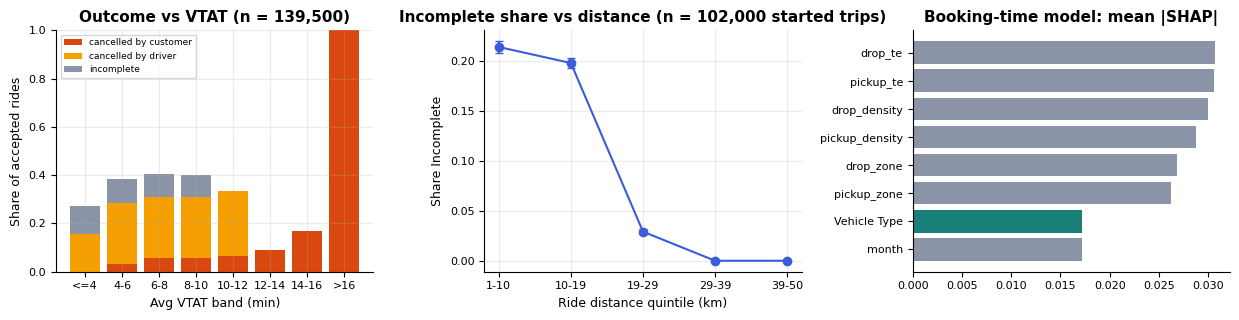

,Booking-time model (SHAP rank),Diagnostic B: accepted rides (gain),Diagnostic C: Completed vs Incomplete (gain)
1st,drop_te,Avg VTAT,Ride Distance
2nd,pickup_te,drop_te,Avg VTAT
3rd,drop_density,pickup_te,drop_te


In [47]:
vt_acc = df[df["Avg VTAT"].notna()].copy()
vt_acc["VTAT bin"] = pd.cut(vt_acc["Avg VTAT"], [0, 4, 6, 8, 10, 12, 14, 16, 20.5], labels=["<=4", "4-6", "6-8", "8-10", "10-12", "12-14", "14-16", ">16"])
vt_rates = vt_acc.groupby("VTAT bin", observed=True).agg(n=("completed", "size"), customer=("Booking Status", lambda s: (s == "Cancelled by Customer").mean()),
                                                        driver=("Booking Status", lambda s: (s == "Cancelled by Driver").mean()),
                                                        incomplete=("Booking Status", lambda s: (s == "Incomplete").mean()),
                                                        completed=("completed", "mean"))
p_vt = chi2_p(vt_acc, "VTAT bin", "completed")
started = df[df["Ride Distance"].notna()].copy()
started["Distance bin"] = pd.qcut(started["Ride Distance"], 5)
dist_rates = rate_table(started.assign(inc=(started["Booking Status"] == "Incomplete").astype(int)), "Distance bin", "inc")
veh_rank = list(shap_imp.index).index("Vehicle Type") + 1
fig, axs = plt.subplots(1, 3, figsize=(12.5, 3.3))
xl = [str(i) for i in vt_rates.index]
axs[0].bar(xl, vt_rates.customer, color=C_BAD, label="cancelled by customer"); axs[0].bar(xl, vt_rates.driver, bottom=vt_rates.customer, color="#f59f00", label="cancelled by driver")
axs[0].bar(xl, vt_rates.incomplete, bottom=vt_rates.customer + vt_rates.driver, color=C_NEUT, label="incomplete")
axs[0].set_xlabel("Avg VTAT band (min)"); axs[0].set_ylabel("Share of accepted rides"); axs[0].set_title(f"Outcome vs VTAT (n = {len(vt_acc):,})"); axs[0].legend(fontsize=6.5)
xd = [f"{i.left:.0f}-{i.right:.0f}" for i in dist_rates.index]
axs[1].errorbar(xd, dist_rates.rate, yerr=[dist_rates.rate - dist_rates.lo, dist_rates.hi - dist_rates.rate], fmt="o-", color=C_ACC, capsize=3)
axs[1].set_xlabel("Ride distance quintile (km)"); axs[1].set_ylabel("Share Incomplete"); axs[1].set_title(f"Incomplete share vs distance (n = {len(started):,} started trips)")
imp_plot = shap_imp.head(8)[::-1]
axs[2].barh(imp_plot.index, imp_plot.values, color=[C_OK if i == "Vehicle Type" else C_NEUT for i in imp_plot.index]); axs[2].set_title("Booking-time model: mean |SHAP|"); axs[2].grid(False)
plt.tight_layout(); plt.show()
q3 = pd.DataFrame({"Booking-time model (SHAP rank)": list(shap_imp.index[:3]),
                   "Diagnostic B: accepted rides (gain)": list(gB.index[:3]),
                   "Diagnostic C: Completed vs Incomplete (gain)": list(gC.index[:3])}, index=["1st", "2nd", "3rd"])
display(q3)

In [48]:
lo_b, mid_b, hi_b = vt_rates.iloc[0], vt_rates.loc["14-16"], vt_rates.loc[">16"]
max_vt_inc = df.loc[df["Booking Status"] == "Incomplete", "Avg VTAT"].max(); max_vt_dc = df.loc[df["Booking Status"] == "Cancelled by Driver", "Avg VTAT"].max()
md(f"""**Insight.** **Booking-time model:** the three features it leans on most are **{', '.join(shap_imp.index[:3])}**; `Vehicle Type` ranks #{veh_rank} of {len(shap_imp)}. None of them beats the noise column in the permutation test (E2), so they do not constitute demonstrated drivers.
**Diagnostic model:** the lever with real, interpretable signal is **Avg VTAT**. Among accepted rides ({len(vt_acc):,} with VTAT), the share cancelled by the customer is {pct(lo_b.customer)} when VTAT is at most 4 min, {pct(mid_b.customer)} in the 14-16 min band ({int(mid_b.n):,} rides) and **{pct(hi_b.customer)} above 16 min** ({int(hi_b.n):,} rides): every match with VTAT above 16 minutes ended in a customer cancellation. **⚠ Synthetic-data artefact:** a hard 100% cut-off at exactly 16 min (no Incomplete ride has a VTAT above {max_vt_inc:.0f} min and no driver cancellation above {max_vt_dc:.0f} min) is how generated data behaves; read it as the direction of the effect, not as a real-world magnitude.
Completion varies in a non-monotonic way across VTAT bands ({pct(vt_rates.completed.min())} to {pct(vt_rates.completed.max())}; chi-square p {'< 0.001' if p_vt < .001 else '= %.3f' % p_vt}) because short-VTAT matches are where driver cancellations and incomplete trips concentrate (no Incomplete ride has a VTAT above {max_vt_inc:.0f} min), while long-VTAT matches fail through customer cancellation.
**Trip distance** separates *Incomplete* rides ({pct(dist_rates.rate.iloc[0])} of the shortest-quintile started trips vs {pct(dist_rates.rate.iloc[-1])} of the longest), but this is a consequence of a trip that stopped early, not a booking-time risk.""")
inc_rs = df["Incomplete Rides Reason"].value_counts(normalize=True)
md(f"""**Recommendation (Q3) and expected impact.**
* **Routing / dispatch (highest value).** Reduce VTAT, the only lever with a visible effect: set a maximum VTAT at which a match is confirmed (re-dispatch above it), prefer lower-VTAT matches over higher-rated ones when the gap exceeds a few minutes, and show an honest arrival estimate so long-VTAT matches are not accepted by riders who then cancel. Quantified below.
* **Driver training.** Incomplete trips split across *{inc_rs.index[0]}* ({pct(inc_rs.iloc[0])}), *{inc_rs.index[1]}* ({pct(inc_rs.iloc[1])}) and *{inc_rs.index[2]}* ({pct(inc_rs.iloc[2])}); add a pre-shift vehicle checklist and a script for resolving customer-driven stops without abandoning the trip.
* **Vehicle restrictions: not supported.** Vehicle Type shows no relationship with non-completion (chi-square p = {R['p_veh']:.2f}, see Q6); restricting vehicle types would cost demand with no expected reliability gain.""")
late = vt_acc[vt_acc["Avg VTAT"] > 14]
late_cc = int((late["Booking Status"] == "Cancelled by Customer").sum()); all_cc = int((df["Booking Status"] == "Cancelled by Customer").sum())
conv = pd.DataFrame({"conversion scenario (illustrative assumption)": ["10%", "25%", "50%"],
                     "rides saved / year": [late_cc * c for c in (.10, .25, .50)],
                     "booking value recovered (Rs)": [late_cc * c * V for c in (.10, .25, .50)]}).set_index("conversion scenario (illustrative assumption)")
display(conv.round(0).map(lambda v: f"{v:,.0f}"))
md(f"**Expected impact of a VTAT cap.** Matches with VTAT above 14 min number {len(late):,} per year and contain {late_cc:,} customer cancellations, **{pct(late_cc/all_cc,0)} of all customer cancellations**. If a maximum-VTAT rule (re-dispatch instead of confirming a match above the cap) converted a quarter of them into completed rides, the platform would gain about {late_cc*.25:,.0f} rides and Rs {late_cc*.25*V:,.0f} of booking value per year (table above for 10% and 50%). The 10/25/50% conversion scenarios are **illustrative assumptions, not estimates**, and this is an association in observational data (⚠ on data with synthetic-looking VTAT), so pilot the rule in one region before scaling.")
R.update(q3_top=list(shap_imp.index[:3]), q3_late_cc=late_cc, q3_late_share=late_cc / all_cc, q3_hi_cust=hi_b.customer)

**Insight.** **Booking-time model:** the three features it leans on most are **drop_te, pickup_te, drop_density**; `Vehicle Type` ranks #7 of 19. None of them beats the noise column in the permutation test (E2), so they do not constitute demonstrated drivers.
**Diagnostic model:** the lever with real, interpretable signal is **Avg VTAT**. Among accepted rides (139,500 with VTAT), the share cancelled by the customer is 0.0% when VTAT is at most 4 min, 16.8% in the 14-16 min band (8,258 rides) and **100.0% above 16 min** (2,792 rides): every match with VTAT above 16 minutes ended in a customer cancellation. **⚠ Synthetic-data artefact:** a hard 100% cut-off at exactly 16 min (no Incomplete ride has a VTAT above 10 min and no driver cancellation above 12 min) is how generated data behaves; read it as the direction of the effect, not as a real-world magnitude.
Completion varies in a non-monotonic way across VTAT bands (0.0% to 91.1%; chi-square p < 0.001) because short-VTAT matches are where driver cancellations and incomplete trips concentrate (no Incomplete ride has a VTAT above 10 min), while long-VTAT matches fail through customer cancellation.
**Trip distance** separates *Incomplete* rides (21.4% of the shortest-quintile started trips vs 0.0% of the longest), but this is a consequence of a trip that stopped early, not a booking-time risk.

**Recommendation (Q3) and expected impact.**
* **Routing / dispatch (highest value).** Reduce VTAT, the only lever with a visible effect: set a maximum VTAT at which a match is confirmed (re-dispatch above it), prefer lower-VTAT matches over higher-rated ones when the gap exceeds a few minutes, and show an honest arrival estimate so long-VTAT matches are not accepted by riders who then cancel. Quantified below.
* **Driver training.** Incomplete trips split across *Customer Demand* (33.8%), *Vehicle Breakdown* (33.5%) and *Other Issue* (32.8%); add a pre-shift vehicle checklist and a script for resolving customer-driven stops without abandoning the trip.
* **Vehicle restrictions: not supported.** Vehicle Type shows no relationship with non-completion (chi-square p = 0.40, see Q6); restricting vehicle types would cost demand with no expected reliability gain.

,rides saved / year,booking value recovered (Rs)
conversion scenario (illustrative assumption),,
10%,418,"211,410"
25%,"1,044","528,525"
50%,"2,088","1,057,049"


**Expected impact of a VTAT cap.** Matches with VTAT above 14 min number 11,050 per year and contain 4,176 customer cancellations, **40% of all customer cancellations**. If a maximum-VTAT rule (re-dispatch instead of confirming a match above the cap) converted a quarter of them into completed rides, the platform would gain about 1,044 rides and Rs 528,525 of booking value per year (table above for 10% and 50%). The 10/25/50% conversion scenarios are **illustrative assumptions, not estimates**, and this is an association in observational data (⚠ on data with synthetic-looking VTAT), so pilot the rule in one region before scaling.

### Q3 answer: top-3 non-behavioural features from the diagnostic model's SHAP
The diagnostic models from E3 (B: accepted rides, C: started trips) are explained with SHAP. Features are ranked by mean |SHAP| as a **multiple of a pure-noise column's** in the same model, so the two models' different scales do not matter. Because a noise column is a weak yardstick when a couple of features dominate, a feature is called a **real driver only if it also passes a held-out permutation test** (shuffling it must hurt test ROC-AUC by more than shuffling the noise column does, by two standard deviations). All candidates are non-behavioural (no customer-history feature exists). Impact figures are **illustrative scenarios built on stated assumptions, not forecasts**.

In [49]:
def shap_and_perm(cols, Xa, ya, Xb, yb, seed=SEED):
    rg = np.random.default_rng(seed)
    Xa_n = Xa[cols].assign(random_noise=rg.normal(size=len(Xa))); Xb_n = Xb[cols].assign(random_noise=rg.normal(size=len(Xb)))
    m_ = lgb.LGBMClassifier(**P).fit(Xa_n, ya)
    smp = Xb_n.sample(min(3000, len(Xb_n)), random_state=SEED)
    sv_ = shap.TreeExplainer(m_).shap_values(smp, check_additivity=False)
    sv_ = sv_[1] if isinstance(sv_, list) else sv_
    s_ = pd.Series(np.abs(sv_).mean(0), index=smp.columns)
    pi_ = permutation_importance(m_, Xb_n, yb, scoring="roc_auc", n_repeats=5, random_state=seed, n_jobs=1)
    pm, ps = pd.Series(pi_.importances_mean, index=Xb_n.columns), pd.Series(pi_.importances_std, index=Xb_n.columns)
    bar = pm["random_noise"] + 2 * ps["random_noise"]
    return pd.DataFrame({"shap": s_.drop("random_noise"), "x_noise": s_.drop("random_noise") / s_["random_noise"],
                         "perm_ok": (pm - 2 * ps > max(bar, 0)).drop("random_noise"), "perm_drop": pm.drop("random_noise")})
mk_fa, mk_ta = Dfit["Avg VTAT"].notna().values, Dtest["Avg VTAT"].notna().values            # local masks (names tc/ta are reused elsewhere)
mk_fc, mk_tc = Dfit["Booking Value"].notna().values, Dtest["Booking Value"].notna().values
tB = shap_and_perm(base_cols + ["Avg VTAT"], Dfit[mk_fa], y_fit[mk_fa], Dtest[mk_ta], y_test[mk_ta]).assign(model="B: accepted rides")
tC = shap_and_perm(base_cols + ["Avg VTAT", "Ride Distance", "Booking Value"], Dfit[mk_fc], y_fit[mk_fc], Dtest[mk_tc], y_test[mk_tc]).assign(model="C: Completed vs Incomplete")
cand = pd.concat([tB, tC]).rename_axis("feature").reset_index().sort_values("x_noise", ascending=False).drop_duplicates("feature").head(3).reset_index(drop=True)
n_inc = int((df["Booking Status"] == "Incomplete").sum())
LEVER = {
 "Avg VTAT": ("VTAT cap: re-dispatch matches above ~14 min instead of confirming them; show an honest arrival estimate",
              f"{late_cc:,} customer cancellations a year sit above 14 min; converting 25% (illustrative assumption) = {late_cc*.25:,.0f} rides, Rs {late_cc*.25*V:,.0f}"),
 "Ride Distance": ("In-trip support and a pre-shift vehicle checklist (Incomplete trips split roughly equally across breakdown, customer demand and other). Not a booking-time lever: it records how far the trip got",
                   f"{n_inc:,} Incomplete trips a year; a 10% cut (illustrative assumption) = {.10*n_inc:,.0f} rides, Rs {.10*n_inc*V:,.0f}")}
ok = (cand.x_noise >= 2) & cand.perm_ok
cand["verdict"] = np.where(ok, "real driver (>= 2x noise and passes permutation test)", "not confirmed (fails the permutation test)")
cand["operational lever"] = [LEVER.get(f, ("None justified (no measurable effect)", ""))[0] if k else "None justified: not distinguishable from noise" for f, k in zip(cand.feature, ok)]
cand["expected impact (illustrative)"] = [LEVER.get(f, ("", ""))[1] if k else "No impact claimed" for f, k in zip(cand.feature, ok)]
out_ = cand.assign(rank=range(1, 4), shap=cand.shap.map(lambda v: f"{v:.3f}"), x_noise=cand.x_noise.map(lambda v: f"{v:.1f}x"), perm_drop=cand.perm_drop.map(lambda v: f"{v:+.4f}"))
out_ = out_[["rank", "feature", "model", "shap", "x_noise", "perm_drop", "verdict", "operational lever", "expected impact (illustrative)"]].rename(columns={"shap": "mean abs SHAP", "x_noise": "x noise column", "perm_drop": "test AUC drop when shuffled"})
md(out_.to_markdown(index=False))
Q3_TOP3 = list(cand.feature); Q3_REAL = int(ok.sum())

|   rank | feature       | model                      |   mean abs SHAP | x noise column   |   test AUC drop when shuffled | verdict                                               | operational lever                                                                                                                                                                                 | expected impact (illustrative)                                                                                           |
|-------:|:--------------|:---------------------------|----------------:|:-----------------|------------------------------:|:------------------------------------------------------|:--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|:-------------------------------------------------------------------------------------------------------------------------|
|      1 | Ride Distance | C: Completed vs Incomplete |           3.599 | 56.9x            |                        0.2967 | real driver (>= 2x noise and passes permutation test) | In-trip support and a pre-shift vehicle checklist (Incomplete trips split roughly equally across breakdown, customer demand and other). Not a booking-time lever: it records how far the trip got | 9,000 Incomplete trips a year; a 10% cut (illustrative assumption) = 900 rides, Rs 455,625                               |
|      2 | Avg VTAT      | B: accepted rides          |           0.688 | 35.6x            |                        0.1528 | real driver (>= 2x noise and passes permutation test) | VTAT cap: re-dispatch matches above ~14 min instead of confirming them; show an honest arrival estimate                                                                                           | 4,176 customer cancellations a year sit above 14 min; converting 25% (illustrative assumption) = 1,044 rides, Rs 528,525 |
|      3 | month         | C: Completed vs Incomplete |           0.104 | 1.6x             |                        0      | not confirmed (fails the permutation test)            | None justified: not distinguishable from noise                                                                                                                                                    | No impact claimed                                                                                                        |

In [50]:
md(f"""**Insight.** The top three non-behavioural features by diagnostic SHAP are **{', '.join(Q3_TOP3)}**; **{Q3_REAL} of them are confirmed as real drivers** by both the noise-multiple and the held-out permutation test{'' if Q3_REAL == 3 else ', and the rest are not distinguishable from noise, so no operational lever or impact is claimed for them'}.
{Q3_TOP3[0]} ranks first. Avg VTAT is the real driver that is both known before the trip starts (as an ETA) and actionable by dispatch; Ride Distance is real but describes how far an abandoned trip got, so it points to in-trip support, not booking-time routing.""")

**Insight.** The top three non-behavioural features by diagnostic SHAP are **Ride Distance, Avg VTAT, month**; **2 of them are confirmed as real drivers** by both the noise-multiple and the held-out permutation test, and the rest are not distinguishable from noise, so no operational lever or impact is claimed for them.
Ride Distance ranks first. Avg VTAT is the real driver that is both known before the trip starts (as an ETA) and actionable by dispatch; Ride Distance is real but describes how far an abandoned trip got, so it points to in-trip support, not booking-time routing.

## Q4. Booking Value vs driver cancellations: should long or high-value bookings carry a higher commission incentive?
**The direct comparison is impossible, and that is a finding.** `Booking Value` is recorded only when a trip starts. The first cell below shows how often it exists for each outcome. To still say something about the *fare a driver would have seen*, we build a **route-fare proxy**: the average fare of *other* rides on the same pickup-to-drop route (leave-one-out, so a ride's own fare is never used), plus the average fare per vehicle type.

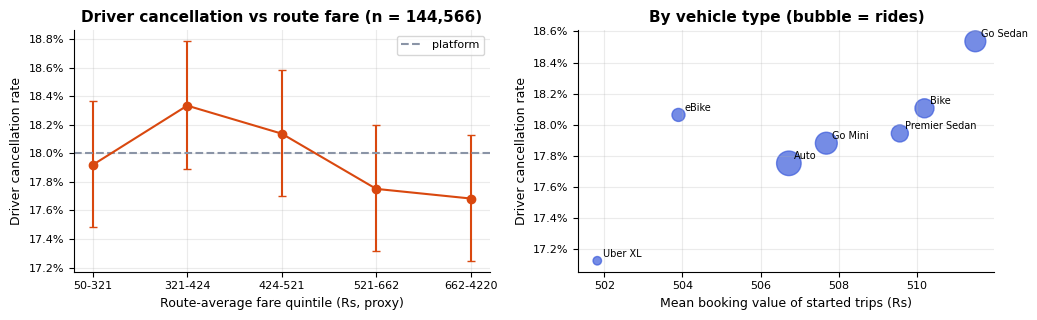

Booking Status,Completed,Incomplete,Cancelled by Driver,Cancelled by Customer,No Driver Found
Booking Value present,100%,100%,0%,0%,0%


In [51]:
bv_av = df.groupby("Booking Status")["Booking Value"].apply(lambda s: s.notna().mean()).loc[status_order]
key = df["Pickup Location"] + ">" + df["Drop Location"]
bv = df["Booking Value"]
s_sum = bv.groupby(key).transform("sum"); s_cnt = bv.groupby(key).transform("count")
loo = (s_sum - bv.fillna(0)) / (s_cnt - bv.notna().astype(int)).replace(0, np.nan)
df["route_fare_proxy"] = loo
px = df.dropna(subset=["route_fare_proxy"]).copy()
px["fare bin"] = pd.qcut(px["route_fare_proxy"], 5)
fr = rate_table(px, "fare bin", "driver_cancel")
p_fare = chi2_p(px, "fare bin", "driver_cancel"); rho_fare, p_rho_fare = stats.spearmanr(px.route_fare_proxy, px.driver_cancel)
veh = df.groupby("Vehicle Type").agg(fare=("Booking Value", "mean"), dcr=("driver_cancel", "mean"), n=("driver_cancel", "size"))
rho_veh, p_veh_fare = stats.spearmanr(veh.fare, veh.dcr)
p_veh_dcr = chi2_p(df, "Vehicle Type", "driver_cancel")
fare_dist_r = df[["Booking Value", "Ride Distance"]].corr().iloc[0, 1]
fig, axs = plt.subplots(1, 2, figsize=(10.5, 3.3))
xf = [f"{i.left:.0f}-{i.right:.0f}" for i in fr.index]
axs[0].errorbar(xf, fr.rate, yerr=[fr.rate - fr.lo, fr.hi - fr.rate], fmt="o-", color=C_BAD, capsize=3)
axs[0].axhline(df.driver_cancel.mean(), color=C_NEUT, ls="--", label="platform"); axs[0].legend()
axs[0].set_xlabel("Route-average fare quintile (Rs, proxy)"); axs[0].set_ylabel("Driver cancellation rate"); axs[0].set_title(f"Driver cancellation vs route fare (n = {len(px):,})")
axs[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1%}"))
axs[1].scatter(veh.fare, veh.dcr, s=veh.n / 120, color=C_ACC, alpha=.7)
for n_, r_ in veh.iterrows(): axs[1].annotate(n_, (r_.fare, r_.dcr), fontsize=7, xytext=(4, 3), textcoords="offset points")
axs[1].set_xlabel("Mean booking value of started trips (Rs)"); axs[1].set_ylabel("Driver cancellation rate"); axs[1].set_title("By vehicle type (bubble = rides)")
axs[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1%}"))
plt.tight_layout(); plt.show()
display(bv_av.map(lambda v: pct(v, 0)).to_frame("Booking Value present").T)

In [52]:
md(f"""**Insight.** `Booking Value` exists for {pct(bv_av['Cancelled by Driver'],0)} of driver-cancelled rides (and {pct(bv_av['Completed'],0)} of completed ones), so the fare-versus-cancellation relationship cannot be observed directly.
Using the leave-one-out route-fare proxy ({len(px):,} rides with at least one other fare on the route), driver cancellation runs from {pct(fr.rate.min())} to {pct(fr.rate.max())} across fare quintiles with no trend (chi-square p = {p_fare:.2f}; Spearman rho = {rho_fare:+.3f}, p = {p_rho_fare:.2f}).
Across the seven vehicle types, the rank correlation between mean fare and driver-cancellation rate is rho = {rho_veh:+.2f} (p = {p_veh_fare:.2f}, only 7 points); but mean fares differ by just Rs {veh.fare.max()-veh.fare.min():.0f} between the cheapest and dearest type, driver-cancellation rates span only {pct(veh.dcr.min())} to {pct(veh.dcr.max())}, and those rate differences are themselves not significant (chi-square p = {p_veh_dcr:.2f}). A correlation between two sets of near-identical numbers is not actionable.
A second data-quality finding bears on the commission question: fare is **uncorrelated with distance** (r = {fare_dist_r:+.3f}) in this dataset (**⚠ synthetic-data artefact:** real tariffs track distance), so "long-distance" and "high-value" are not the same bookings and neither predicts driver cancellation.""")
md(f"""**Recommendation (Q4) and expected impact.**
* **Do not roll out a higher commission-for-long-distance scheme on this evidence.** The proxy fare shows no trend, and the vehicle-type comparison rests on differences too small to be significant.
* **Run a controlled test instead.** Randomise a driver bonus (a share of the fare returned as an incentive, rather than a different commission rate, which is harder to revert) across comparable bookings and measure the driver-cancellation rate. Detecting a 1-point change in a rate near {pct(df.driver_cancel.mean())} needs roughly (80% power, 5% significance) {int(2 * (1.96 + 0.84)**2 * df.driver_cancel.mean() * (1 - df.driver_cancel.mean()) / .01**2):,} bookings per arm, achievable within days at this volume.
* **Fix the fare data first.** A fare uncorrelated with distance suggests either synthetic or mis-recorded values; incentive design needs a trustworthy fare-at-offer field.
* **Upper bound on the prize:** driver cancellations are {pct(df.driver_cancel.mean())} of requests ({int(df.driver_cancel.sum()):,} rides/year). Every 1 point of driver-cancellation prevented is worth about {0.01*len(df):,.0f} rides, or Rs {0.01*len(df)*V:,.0f} a year.""")
R.update(q4_p=p_fare, q4_fare_dist_r=fare_dist_r)

**Insight.** `Booking Value` exists for 0% of driver-cancelled rides (and 100% of completed ones), so the fare-versus-cancellation relationship cannot be observed directly.
Using the leave-one-out route-fare proxy (144,566 rides with at least one other fare on the route), driver cancellation runs from 17.7% to 18.3% across fare quintiles with no trend (chi-square p = 0.22; Spearman rho = -0.004, p = 0.16).
Across the seven vehicle types, the rank correlation between mean fare and driver-cancellation rate is rho = +0.79 (p = 0.04, only 7 points); but mean fares differ by just Rs 10 between the cheapest and dearest type, driver-cancellation rates span only 17.1% to 18.5%, and those rate differences are themselves not significant (chi-square p = 0.14). A correlation between two sets of near-identical numbers is not actionable.
A second data-quality finding bears on the commission question: fare is **uncorrelated with distance** (r = +0.005) in this dataset (**⚠ synthetic-data artefact:** real tariffs track distance), so "long-distance" and "high-value" are not the same bookings and neither predicts driver cancellation.

**Recommendation (Q4) and expected impact.**
* **Do not roll out a higher commission-for-long-distance scheme on this evidence.** The proxy fare shows no trend, and the vehicle-type comparison rests on differences too small to be significant.
* **Run a controlled test instead.** Randomise a driver bonus (a share of the fare returned as an incentive, rather than a different commission rate, which is harder to revert) across comparable bookings and measure the driver-cancellation rate. Detecting a 1-point change in a rate near 18.0% needs roughly (80% power, 5% significance) 23,143 bookings per arm, achievable within days at this volume.
* **Fix the fare data first.** A fare uncorrelated with distance suggests either synthetic or mis-recorded values; incentive design needs a trustworthy fare-at-offer field.
* **Upper bound on the prize:** driver cancellations are 18.0% of requests (27,000 rides/year). Every 1 point of driver-cancellation prevented is worth about 1,500 rides, or Rs 759,374 a year.

## Q5. Most frequent driver cancellation reasons and what they imply for onboarding and training
**Method.** Reasons exist only for *Cancelled by Driver* rides, so the denominator is those rides. We test whether any reason dominates (chi-square against equal shares) and whether the mix changes by vehicle type or time of day. Customer-side reasons are added because two of them (*Driver is not moving towards pickup*, *Driver asked to cancel*) describe **driver behaviour** reported by riders.

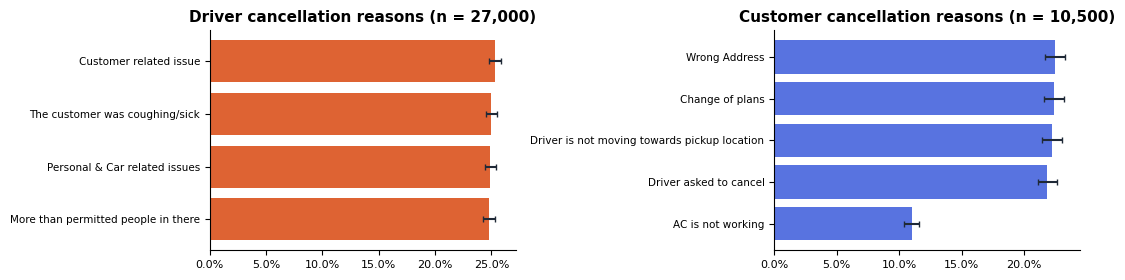

In [53]:
dr_df = df[df["Booking Status"] == "Cancelled by Driver"].copy()
dr_df["time_slot"] = static_features(dr_df)["time_slot"].values
rs = dr_df["Driver Cancellation Reason"].value_counts()
rs_t = pd.DataFrame({"k": rs, "n": len(dr_df)}); rs_t["rate"] = rs_t.k / rs_t.n; rs_t["lo"], rs_t["hi"] = wilson(rs_t.k, rs_t.n)
p_uniform = stats.chisquare(rs.values)[1]
p_r_veh = chi2_contingency(pd.crosstab(dr_df["Vehicle Type"], dr_df["Driver Cancellation Reason"]))[1]
p_r_slot = chi2_contingency(pd.crosstab(dr_df["time_slot"], dr_df["Driver Cancellation Reason"]))[1]
cu_df = df[df["Booking Status"] == "Cancelled by Customer"]
cs = cu_df["Reason for cancelling by Customer"].value_counts()
cs_t = pd.DataFrame({"k": cs, "n": len(cu_df)}); cs_t["rate"] = cs_t.k / cs_t.n; cs_t["lo"], cs_t["hi"] = wilson(cs_t.k, cs_t.n)
drv_behaviour = cs[["Driver is not moving towards pickup location", "Driver asked to cancel"]].sum()
fig, axs = plt.subplots(1, 2, figsize=(11, 2.9))
for ax, t, ttl, col in [(axs[0], rs_t, f"Driver cancellation reasons (n = {len(dr_df):,})", C_BAD), (axs[1], cs_t, f"Customer cancellation reasons (n = {len(cu_df):,})", C_ACC)]:
    t = t.sort_values("rate"); y = np.arange(len(t))
    ax.barh(y, t.rate, color=col, alpha=.85); ax.errorbar(t.rate, y, xerr=[t.rate - t.lo, t.hi - t.rate], fmt="none", ecolor=C_DARK, capsize=2)
    ax.set_yticks(y); ax.set_yticklabels(t.index, fontsize=7.5); ax.set_title(ttl); ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1%}")); ax.grid(False)
plt.tight_layout(); plt.show()
inc_t = df["Incomplete Rides Reason"].value_counts(normalize=True)

In [54]:
md(f"""**Insight.** The four driver reasons are almost equally common: {', '.join(f'**{i}** ({pct(r)})' for i, r in rs_t.sort_values('rate', ascending=False)['rate'].items())}. A chi-square test against equal shares gives p = {p_uniform:.2f}, so **no single reason dominates**, and the mix does not change by vehicle type (p = {p_r_veh:.2f}) or time of day (p = {p_r_slot:.2f}). **⚠ Synthetic-data artefact:** four reasons at almost exactly 25% each is what uniform random generation produces; real cancellation reasons are rarely this even, so rank reasons from production logs before prioritising modules.
Driver cancellations are {pct(len(dr_df)/df.non_completed.sum(),0)} of all failed rides ({len(dr_df):,} of {int(df.non_completed.sum()):,}), the largest single failure mode. Riders add that **{drv_behaviour:,} customer cancellations ({pct(drv_behaviour/len(cu_df),0)}) cite driver behaviour** ("not moving towards pickup" or "asked to cancel"), so driver-originated failures are larger than the driver-cancellation line alone.""")
md(f"""**Recommendation (Q5) and expected impact.** Because no reason dominates, training should be a **short, four-module curriculum delivered to every driver at onboarding and refreshed quarterly**, not a single-topic programme:
| Reason (about {pct(rs_t.rate.mean(),0)} of driver cancellations each) | Training / product response |
|---|---|
| Customer-related issue | Conflict-handling and in-app reporting scripts so problems are reported instead of resolved by cancelling; clearer pickup pins to reduce the customer-side friction behind it |
| Customer coughing / sick | Health-and-hygiene protocol (masks and sanitiser supply, rider-health guidance) plus an in-app "safety concern" route that is reviewed rather than penalised |
| Personal and car-related issues | Pre-shift vehicle checklist, an easy "go offline" toggle so drivers do not accept rides they cannot do, and breakdown-support access |
| More than permitted passengers | Show the passenger limit at booking, ask for headcount, and nudge groups to the XL category |
**Also** coach on pickup behaviour (riders cite "not moving towards pickup" and "asked to cancel") and add cancellation-reason prompts that are **tracked per driver**. Each 10% reduction in driver cancellations (an illustrative scenario) would avoid about {0.10*len(dr_df):,.0f} lost rides per year, roughly Rs {0.10*len(dr_df)*V:,.0f} of booking value. Because the reasons are self-reported, audit a sample against trip telemetry before basing penalties on them.""")
R.update(q5_p_uniform=p_uniform, q5_driver_share=len(dr_df) / df.non_completed.sum(), q5_beh=drv_behaviour / len(cu_df))

**Insight.** The four driver reasons are almost equally common: **Customer related issue** (25.3%), **The customer was coughing/sick** (25.0%), **Personal & Car related issues** (24.9%), **More than permitted people in there** (24.8%). A chi-square test against equal shares gives p = 0.61, so **no single reason dominates**, and the mix does not change by vehicle type (p = 0.52) or time of day (p = 0.54). **⚠ Synthetic-data artefact:** four reasons at almost exactly 25% each is what uniform random generation produces; real cancellation reasons are rarely this even, so rank reasons from production logs before prioritising modules.
Driver cancellations are 47% of all failed rides (27,000 of 57,000), the largest single failure mode. Riders add that **4,630 customer cancellations (44%) cite driver behaviour** ("not moving towards pickup" or "asked to cancel"), so driver-originated failures are larger than the driver-cancellation line alone.

**Recommendation (Q5) and expected impact.** Because no reason dominates, training should be a **short, four-module curriculum delivered to every driver at onboarding and refreshed quarterly**, not a single-topic programme:
| Reason (about 25% of driver cancellations each) | Training / product response |
|---|---|
| Customer-related issue | Conflict-handling and in-app reporting scripts so problems are reported instead of resolved by cancelling; clearer pickup pins to reduce the customer-side friction behind it |
| Customer coughing / sick | Health-and-hygiene protocol (masks and sanitiser supply, rider-health guidance) plus an in-app "safety concern" route that is reviewed rather than penalised |
| Personal and car-related issues | Pre-shift vehicle checklist, an easy "go offline" toggle so drivers do not accept rides they cannot do, and breakdown-support access |
| More than permitted passengers | Show the passenger limit at booking, ask for headcount, and nudge groups to the XL category |
**Also** coach on pickup behaviour (riders cite "not moving towards pickup" and "asked to cancel") and add cancellation-reason prompts that are **tracked per driver**. Each 10% reduction in driver cancellations (an illustrative scenario) would avoid about 2,700 lost rides per year, roughly Rs 1,366,874 of booking value. Because the reasons are self-reported, audit a sample against trip telemetry before basing penalties on them.

## Q6. Completion and demand by vehicle type: should supply or pricing favour the best performer?
**Method.** For each vehicle type we show demand (share of all requests), completion rate with a 95% interval, and the pickup/arrival times that determine customer wait (VTAT where it exists, CTAT where it exists, with the denominator). Then we test whether the best type really beats the worst, and size a hypothetical re-allocation.

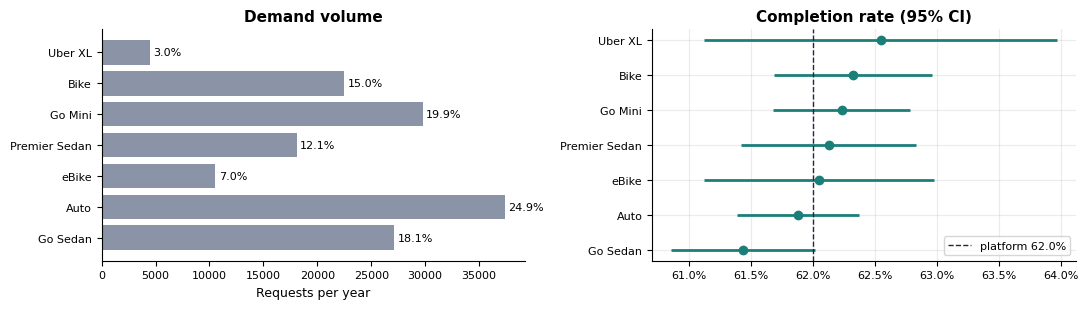

,requests,share,completion,VTAT,n with VTAT,CTAT,n with CTAT
Vehicle Type,,,,,,,
Uber XL,4449,3.0%,62.6%,8.58,4134,29.2,3045
Bike,22517,15.0%,62.3%,8.50,21014,29.2,15362
Go Mini,29806,19.9%,62.2%,8.47,27791,29.2,20364
Premier Sedan,18111,12.1%,62.1%,8.44,16831,29.2,12315
eBike,10557,7.0%,62.1%,8.48,9811,29.2,7181
Auto,37419,24.9%,61.9%,8.45,34738,29.1,25415
Go Sedan,27141,18.1%,61.4%,8.40,25181,29.0,18318


,rides shifted 5% of Go Sedan demand,rides shifted 10% of Go Sedan demand
rides moved,"1,357","2,714"
extra completions (point),15,30
extra completions (CI low),-6,-12
extra completions (CI high),36,72


In [55]:
vtab = rate_table(df, "Vehicle Type", "completed")
vtab["share"] = vtab.n / vtab.n.sum()
vtab["VTAT"] = df.groupby("Vehicle Type")["Avg VTAT"].mean(); vtab["n_VTAT"] = df.groupby("Vehicle Type")["Avg VTAT"].count()
vtab["CTAT"] = df.groupby("Vehicle Type")["Avg CTAT"].mean(); vtab["n_CTAT"] = df.groupby("Vehicle Type")["Avg CTAT"].count()
vtab = vtab.sort_values("rate")
p_vc = chi2_p(df, "Vehicle Type", "completed")
best, worst = vtab.index[-1], vtab.index[0]
d_rate = vtab.loc[best, "rate"] - vtab.loc[worst, "rate"]
se_d = np.sqrt(vtab.loc[best, "rate"] * (1 - vtab.loc[best, "rate"]) / vtab.loc[best, "n"] + vtab.loc[worst, "rate"] * (1 - vtab.loc[worst, "rate"]) / vtab.loc[worst, "n"])
d_lo, d_hi = d_rate - 1.96 * se_d, d_rate + 1.96 * se_d
fig, axs = plt.subplots(1, 2, figsize=(11, 3.2))
y = np.arange(len(vtab))
axs[0].barh(y, vtab.n, color=C_NEUT); axs[0].set_yticks(y); axs[0].set_yticklabels(vtab.index); axs[0].set_xlabel("Requests per year"); axs[0].set_title("Demand volume"); axs[0].grid(False)
for i, (n_, s_) in enumerate(zip(vtab.n, vtab.share)): axs[0].text(n_ + 300, i, pct(s_), va="center", fontsize=8)
axs[1].hlines(y, vtab.lo, vtab.hi, color=C_OK, lw=2); axs[1].scatter(vtab.rate, y, color=C_OK, zorder=3)
axs[1].axvline(df.completed.mean(), color=C_DARK, ls="--", lw=1, label=f"platform {pct(df.completed.mean())}"); axs[1].set_yticks(y); axs[1].set_yticklabels(vtab.index)
axs[1].set_title("Completion rate (95% CI)"); axs[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1%}")); axs[1].legend(loc="lower right")
plt.tight_layout(); plt.show()
display(vtab.assign(share=vtab.share.map(pct), rate=vtab.rate.map(pct), VTAT=vtab.VTAT.round(2), CTAT=vtab.CTAT.round(1))[["n", "share", "rate", "VTAT", "n_VTAT", "CTAT", "n_CTAT"]]
        .rename(columns={"n": "requests", "rate": "completion", "n_VTAT": "n with VTAT", "n_CTAT": "n with CTAT"}).iloc[::-1])
shift_tbl = pd.DataFrame({f"rides shifted {s:.0%} of {worst} demand": [s * vtab.loc[worst, "n"], s * vtab.loc[worst, "n"] * d_rate, s * vtab.loc[worst, "n"] * d_lo, s * vtab.loc[worst, "n"] * d_hi] for s in (.05, .10)},
                         index=["rides moved", "extra completions (point)", "extra completions (CI low)", "extra completions (CI high)"]).round(0)
display(shift_tbl.map(lambda v: f"{v:,.0f}"))

In [56]:
md(f"""**Insight.** Completion rates sit in a {pct(vtab.rate.min())} to {pct(vtab.rate.max())} band; the highest is **{best}** ({pct(vtab.loc[best,'rate'])}, {int(vtab.loc[best,'n']):,} requests) and the lowest is **{worst}** ({pct(vtab.loc[worst,'rate'])}, {int(vtab.loc[worst,'n']):,} requests). The chi-square test across all types gives p = {p_vc:.2f}, and the best-vs-worst gap of {100*d_rate:.1f} points has a 95% interval of {100*d_lo:+.1f} to {100*d_hi:+.1f} points, {'which includes zero' if d_lo <= 0 <= d_hi else 'which excludes zero'}.
Demand is concentrated in {vtab.sort_values('n').index[-1]} ({pct(vtab.sort_values('share').share.iloc[-1],0)} of requests) and {vtab.sort_values('n').index[-2]} ({pct(vtab.sort_values('share').share.iloc[-2],0)}), while {best} is {pct(vtab.loc[best,'share'],0)} of demand. Wait times are also nearly identical across types (VTAT {vtab.VTAT.min():.1f} to {vtab.VTAT.max():.1f} min, CTAT {vtab.CTAT.min():.1f} to {vtab.CTAT.max():.1f} min).""")
md(f"""**Recommendation (Q6) and expected impact.** **No: do not re-weight supply or pricing towards {best} on this evidence.**
* The completion gap is {'statistically indistinguishable from zero' if d_lo <= 0 <= d_hi else 'statistically detectable but tiny'}, and {best} is a {'small' if vtab.loc[best,'share'] < vtab.share.median() else 'large'}-volume type ({pct(vtab.loc[best,'share'],0)} of demand; the median type has {pct(vtab.share.median(),0)}){', so steering demand towards it would also strain its supply' if vtab.loc[best,'share'] < vtab.share.median() else ''}.
* Even if the point estimate were real, shifting 10% of {worst}'s demand would add about {shift_tbl.iloc[1,1]:,.0f} completions a year (interval {shift_tbl.iloc[2,1]:,.0f} to {shift_tbl.iloc[3,1]:,.0f}), while changing mix could raise waits for the displaced riders, which is not a good trade at this size.
* Keep supply allocation **demand-led** (largest types first), keep pricing type-neutral, and re-test quarterly with the same confidence-interval rule; act only if one type's interval stays clear of the platform average.""")
R.update(q6_p=p_vc, q6_best=best, q6_worst=worst, q6_gap=d_rate)

**Insight.** Completion rates sit in a 61.4% to 62.6% band; the highest is **Uber XL** (62.6%, 4,449 requests) and the lowest is **Go Sedan** (61.4%, 27,141 requests). The chi-square test across all types gives p = 0.40, and the best-vs-worst gap of 1.1 points has a 95% interval of -0.4 to +2.6 points, which includes zero.
Demand is concentrated in Auto (25% of requests) and Go Mini (20%), while Uber XL is 3% of demand. Wait times are also nearly identical across types (VTAT 8.4 to 8.6 min, CTAT 29.0 to 29.2 min).

**Recommendation (Q6) and expected impact.** **No: do not re-weight supply or pricing towards Uber XL on this evidence.**
* The completion gap is statistically indistinguishable from zero, and Uber XL is a small-volume type (3% of demand; the median type has 15%), so steering demand towards it would also strain its supply.
* Even if the point estimate were real, shifting 10% of Go Sedan's demand would add about 30 completions a year (interval -12 to 72), while changing mix could raise waits for the displaced riders, which is not a good trade at this size.
* Keep supply allocation **demand-led** (largest types first), keep pricing type-neutral, and re-test quarterly with the same confidence-interval rule; act only if one type's interval stays clear of the platform average.

## Q7. Fairness: is the model's F1 equal across pickup zones, and if not, what is the mitigation?
**Setup.** Fairness is evaluated on the **test period** using the final LightGBM and the **equal-volume operating point** from D6 (flag the 38% highest-risk rides; threshold fixed on the validation slice). Three zone views are used so the result does not depend on one arbitrary boundary: **North / South / Other**, **Delhi vs satellite cities** and the ten **fine zones**.
Headline metric: **F1 on the non-completed class**, with completed-class F1 and macro F1 beside it. Intervals are bootstrap 95% CIs; a **permutation test** asks whether the largest gap between zones is bigger than random zone labels would produce. A flag-everyone policy has an F1 that depends only on a zone's base rate, shown as a reference column.

In [57]:
def group_f1_boot(y, flag, g, reps=300, seed=SEED):
    """Per-group bootstrap CI of F1 for the non-completed class, plus the max-min gap and its permutation p-value."""
    y = np.asarray(y); flag = np.asarray(flag).astype(bool); g = pd.factorize(np.asarray(g), sort=True)
    codes, names = g[0], g[1]; k = len(names); n = len(y); nc = (y == 0)
    def f1_groups(cd, ncv, fl):
        tp = np.bincount(cd, weights=(ncv & fl), minlength=k); fp = np.bincount(cd, weights=(~ncv & fl), minlength=k); fn = np.bincount(cd, weights=(ncv & ~fl), minlength=k)
        return 2 * tp / np.maximum(2 * tp + fp + fn, 1)
    pt = f1_groups(codes, nc, flag)
    rng = np.random.default_rng(seed); bs = np.empty((reps, k))
    for r in range(reps):
        i = rng.integers(0, n, n); bs[r] = f1_groups(codes[i], nc[i], flag[i])
    gap_obs = pt.max() - pt.min(); gap_ci = np.quantile(bs.max(1) - bs.min(1), [.025, .975])
    null_gaps = np.array([(lambda f: f.max() - f.min())(f1_groups(rng.permutation(codes), nc, flag)) for _ in range(reps)])
    return pd.DataFrame({"F1 non-comp.": pt, "lo": np.quantile(bs, .025, axis=0), "hi": np.quantile(bs, .975, axis=0)}, index=names), gap_obs, gap_ci, (null_gaps >= gap_obs).mean()

def fairness_table(flag, view, d=None):
    d = test if d is None else d
    out = []
    for gname, sub in d.groupby(view):
        idx = d.index.get_indexer(sub.index); yy = y_test[idx]; ff = np.asarray(flag)[idx]
        b = boot_f1(yy, (~ff).astype(int), reps=200)
        tpr = ((yy == 0) & ff).sum() / max((yy == 0).sum(), 1); fpr = ((yy == 1) & ff).sum() / max((yy == 1).sum(), 1)
        out.append({"group": gname, "rides (test)": len(sub), "non-comp. rate": 1 - yy.mean(), "flagged": ff.mean(),
                    "F1 non-comp.": b["F1 non-completed"][0], "F1 CI": f"{b['F1 non-completed'][1]:.3f} to {b['F1 non-completed'][2]:.3f}",
                    "F1 completed": b["F1 completed"][0], "Macro F1": b["Macro F1"][0],
                    "recall (TPR)": tpr, "false-alarm (FPR)": fpr,
                    "ROC-AUC": roc_auc_score(yy, p_raw_test[idx]) if len(np.unique(yy)) > 1 else np.nan,
                    "F1 if flag all": 2 * (1 - yy.mean()) / (1 + (1 - yy.mean()))})
    return pd.DataFrame(out).set_index("group")

**North / South / Other**

,rides (test),non-comp. rate,flagged,F1 non-comp.,F1 CI,F1 completed,Macro F1,recall (TPR),false-alarm (FPR),ROC-AUC,F1 if flag all
group,,,,,,,,,,,
North,10888,37.6%,40.2%,0.386,0.375 to 0.398,0.609,0.497,39.9%,40.4%,0.499,0.547
Other,5933,38.5%,39.9%,0.400,0.381 to 0.416,0.613,0.507,40.7%,39.3%,0.511,0.556
South,13179,38.0%,37.5%,0.376,0.365 to 0.389,0.622,0.499,37.4%,37.5%,0.501,0.550


**Delhi vs satellite cities**

,rides (test),non-comp. rate,flagged,F1 non-comp.,F1 CI,F1 completed,Macro F1,recall (TPR),false-alarm (FPR),ROC-AUC,F1 if flag all
group,,,,,,,,,,,
Delhi,20925,37.7%,41.2%,0.397,0.387 to 0.405,0.607,0.502,41.6%,41.0%,0.503,0.547
Satellite cities,9075,38.6%,33.7%,0.354,0.339 to 0.367,0.634,0.494,33.1%,34.1%,0.502,0.557


**Fine zones**

,rides (test),non-comp. rate,flagged,F1 non-comp.,F1 CI,Macro F1,recall (TPR),false-alarm (FPR),ROC-AUC,F1 if flag all
group,,,,,,,,,,
Central Delhi,4096,38.6%,40.0%,0.403,0.382 to 0.425,0.509,41.1%,39.3%,0.510,0.557
East Delhi,2638,37.9%,43.2%,0.383,0.360 to 0.402,0.481,41.0%,44.5%,0.483,0.550
Faridabad,161,44.7%,60.2%,0.544,0.444 to 0.638,0.521,63.9%,57.3%,0.547,0.618
Ghaziabad,875,38.4%,44.2%,0.412,0.363 to 0.455,0.499,44.3%,44.2%,0.506,0.555
Gurgaon,6202,38.5%,29.8%,0.323,0.308 to 0.339,0.486,28.7%,30.5%,0.494,0.556
Noida,1010,37.3%,54.2%,0.452,0.412 to 0.489,0.495,55.4%,53.4%,0.530,0.544
North Delhi,3974,37.1%,39.2%,0.386,0.363 to 0.405,0.503,39.6%,38.9%,0.501,0.542
Outer NCR,827,39.4%,21.8%,0.281,0.237 to 0.331,0.482,21.8%,21.8%,0.512,0.565
South Delhi,6816,37.3%,44.0%,0.412,0.397 to 0.428,0.505,44.9%,43.4%,0.509,0.543


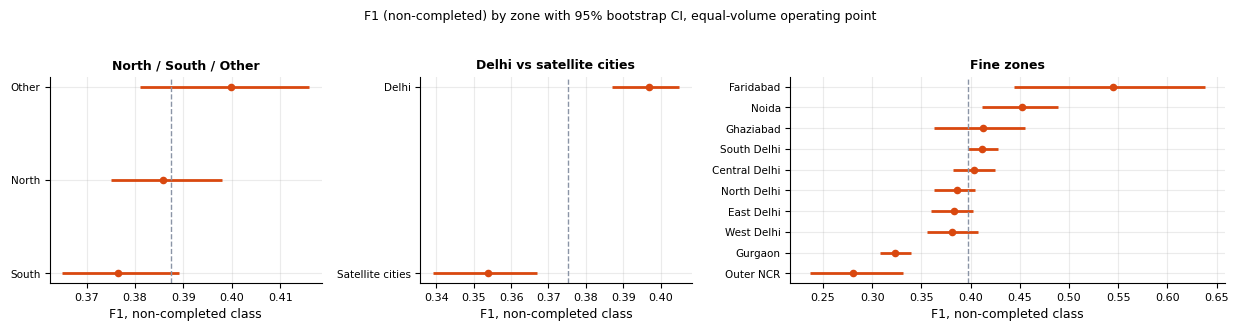

In [58]:
flag_base = p_raw_test < t_topk
views = {"North / South / Other": "region_nso", "Delhi vs satellite cities": "region_ds", "Fine zones": "pickup_zone"}
fair, gaps = {}, {}
for lab, col in views.items():
    fair[lab] = fairness_table(flag_base, col)
    _, gap, gci, gp = group_f1_boot(y_test, flag_base, test[col].values)
    gaps[lab] = (gap, gci, gp)
    p_comp_rate = chi2_p(df, col, "completed")
    gaps[lab] += (p_comp_rate,)
fmt_f = lambda t: t.assign(**{c: t[c].map(lambda v: f"{v:.3f}") for c in ["F1 non-comp.", "F1 completed", "Macro F1", "ROC-AUC", "F1 if flag all"]},
                          **{c: t[c].map(pct) for c in ["non-comp. rate", "flagged", "recall (TPR)", "false-alarm (FPR)"]})
for lab in ["North / South / Other", "Delhi vs satellite cities", "Fine zones"]:
    md(f"**{lab}**"); display(fmt_f(fair[lab]).drop(columns=["F1 completed"] if lab == "Fine zones" else []))
fig, axs = plt.subplots(1, 3, figsize=(12.5, 3.2), gridspec_kw={"width_ratios": [1, 1, 1.6]})
for ax, (lab, t) in zip(axs, fair.items()):
    t = t.copy(); lo = t["F1 CI"].str.split(" to ").str[0].astype(float); hi = t["F1 CI"].str.split(" to ").str[1].astype(float)
    t = t.assign(lo=lo, hi=hi).sort_values("F1 non-comp."); y = np.arange(len(t))
    ax.hlines(y, t.lo, t.hi, color=C_BAD, lw=2); ax.scatter(t["F1 non-comp."], y, color=C_BAD, zorder=3, s=20)
    ax.axvline(t["F1 non-comp."].mean(), color=C_NEUT, ls="--", lw=1); ax.set_yticks(y); ax.set_yticklabels(t.index, fontsize=7.5)
    ax.set_xlabel("F1, non-completed class"); ax.set_title(lab, fontsize=9)
fig.suptitle("F1 (non-completed) by zone with 95% bootstrap CI, equal-volume operating point", fontsize=9, y=1.02)
plt.tight_layout(); plt.show()

In [59]:
g1, g2, g3 = (gaps[k] for k in views)
fz, nso, dsv = fair["Fine zones"], fair["North / South / Other"], fair["Delhi vs satellite cities"]
big = fz[fz["rides (test)"] >= 1000]
det = lambda p: "statistically detectable" if p < .05 else "not statistically detectable"
md(f"""**Insight: outcomes are equal across zones, but the model's treatment of zones is not.**
* **Outcomes and skill are equal.** Completion rates do not differ by zone (chi-square p = {g1[3]:.2f}, {g2[3]:.2f}, {g3[3]:.2f} for the three views), and the model's ROC-AUC is about 0.5 in every zone ({nso['ROC-AUC'].min():.3f} to {nso['ROC-AUC'].max():.3f} for North / South / Other).
* **But at one global threshold the model flags very different shares of rides by zone.** Flagged share: {pct(nso['flagged'].min())} to {pct(nso['flagged'].max())} for North / South / Other; **{pct(dsv.loc['Delhi','flagged'])} in Delhi vs {pct(dsv.loc['Satellite cities','flagged'])} in satellite cities**; and from **{pct(fz['flagged'].min())} ({fz['flagged'].idxmin()}) to {pct(fz['flagged'].max())} ({fz['flagged'].idxmax()})** across the ten fine zones, against a {pct(1-y_test.mean())} base rate. Zone-level offsets that the model learned from noise (the pickup-zone category and the location encodings) shift scores up in some zones and down in others.
* **F1 follows the flagged share, not skill.** F1 on the non-completed class: {nso['F1 non-comp.'].min():.3f} to {nso['F1 non-comp.'].max():.3f} for North / South / Other (largest gap {g1[0]:.3f}, bootstrap CI {g1[1][0]:.3f} to {g1[1][1]:.3f}, permutation p {pv(g1[2])}: {det(g1[2])});
  {dsv.loc['Delhi','F1 non-comp.']:.3f} (Delhi) vs {dsv.loc['Satellite cities','F1 non-comp.']:.3f} (satellite): gap {g2[0]:.3f}, p {pv(g2[2])}, {det(g2[2])};
  and {fz['F1 non-comp.'].min():.3f} to {fz['F1 non-comp.'].max():.3f} across fine zones (gap {g3[0]:.3f}, p {pv(g3[2])}, {det(g3[2])}). Among fine zones with at least 1,000 test rides the range is {big['F1 non-comp.'].min():.3f} to {big['F1 non-comp.'].max():.3f}; the extremes come from the smallest groups ({fz.loc['Faridabad','rides (test)']} and {fz.loc['Outer NCR','rides (test)']} rides), where intervals are widest.
* **Reading the gaps.** The F1 gap is therefore a **selection-rate disparity**: some zones are flagged for intervention far more often than others for no outcome-based reason. Because every F1 here is far below the trivial flag-everyone F1 ({nso['F1 if flag all'].min():.2f} to {nso['F1 if flag all'].max():.2f}), the absolute F1 values should not be compared with business-useful performance.
  Macro F1 is {nso['Macro F1'].min():.2f} to {nso['Macro F1'].max():.2f} everywhere, consistent with a model that has no signal (E1).""")

**Insight: outcomes are equal across zones, but the model's treatment of zones is not.**
* **Outcomes and skill are equal.** Completion rates do not differ by zone (chi-square p = 0.91, 0.91, 0.66 for the three views), and the model's ROC-AUC is about 0.5 in every zone (0.499 to 0.511 for North / South / Other).
* **But at one global threshold the model flags very different shares of rides by zone.** Flagged share: 37.5% to 40.2% for North / South / Other; **41.2% in Delhi vs 33.7% in satellite cities**; and from **21.8% (Outer NCR) to 60.2% (Faridabad)** across the ten fine zones, against a 37.9% base rate. Zone-level offsets that the model learned from noise (the pickup-zone category and the location encodings) shift scores up in some zones and down in others.
* **F1 follows the flagged share, not skill.** F1 on the non-completed class: 0.376 to 0.400 for North / South / Other (largest gap 0.023, bootstrap CI 0.006 to 0.044, permutation p = 0.06: not statistically detectable);
  0.397 (Delhi) vs 0.354 (satellite): gap 0.043, p < 0.002, statistically detectable;
  and 0.281 to 0.544 across fine zones (gap 0.264, p < 0.002, statistically detectable). Among fine zones with at least 1,000 test rides the range is 0.323 to 0.452; the extremes come from the smallest groups (161 and 827 rides), where intervals are widest.
* **Reading the gaps.** The F1 gap is therefore a **selection-rate disparity**: some zones are flagged for intervention far more often than others for no outcome-based reason. Because every F1 here is far below the trivial flag-everyone F1 (0.55 to 0.56), the absolute F1 values should not be compared with business-useful performance.
  Macro F1 is 0.50 to 0.51 everywhere, consistent with a model that has no signal (E1).

### Mapping sensitivity
The zone mapping contains judgement calls (e.g. *Rajiv Nagar*, *Ambience Mall*, *MG Road*, *Gwal Pahari*, *IGI Airport*). The check below moves **all uncertain locations to their alternative zone at once** (list in Appendix A) and recomputes completion rates and F1 by North / South / Other, using the same predictions.

In [60]:
alt_zone = df["Pickup Location"].map(lambda l: ALT_ZONE.get(l)).fillna(df["pickup_zone"])
test_alt = test.assign(region_alt=alt_zone.loc[test.index].map(REGION_NSO).values)
df_alt_region = alt_zone.map(REGION_NSO)
f_alt = fairness_table(flag_base, "region_alt", d=test_alt)
sens_tbl = pd.DataFrame({"completion rate (primary)": df.groupby("region_nso").completed.mean(), "completion rate (alt. mapping)": df.groupby(df_alt_region).completed.mean(),
                         "F1 non-comp. (primary)": fair["North / South / Other"]["F1 non-comp."], "F1 non-comp. (alt. mapping)": f_alt["F1 non-comp."],
                         "rides moved": df.groupby("region_nso").size() - df.groupby("region_nso").apply(lambda g: (df_alt_region.loc[g.index] == g.name).sum())})
display(sens_tbl.assign(**{c: sens_tbl[c].map(pct) for c in sens_tbl.columns if c.startswith("completion")}, **{c: sens_tbl[c].map(lambda v: f"{v:.3f}") for c in sens_tbl.columns if c.startswith("F1")}))
max_move_f1 = (sens_tbl["F1 non-comp. (primary)"] - sens_tbl["F1 non-comp. (alt. mapping)"]).abs().max()
max_move_c = (df.groupby("region_nso").completed.mean() - df.groupby(df_alt_region).completed.mean()).abs().max()
n_moved = int((alt_zone != df["pickup_zone"]).sum())

,completion rate (primary),completion rate (alt. mapping),F1 non-comp. (primary),F1 non-comp. (alt. mapping),rides moved
North,62.1%,62.0%,0.386,0.380,2626
Other,61.9%,62.0%,0.400,0.404,1713
South,62.0%,62.0%,0.376,0.379,3445


In [61]:
md(f"""**Insight.** Moving {len(ALT_ZONE)} uncertain locations ({n_moved:,} rides) to their alternative zones changes any region's completion rate by at most **{100*max_move_c:.2f} percentage points** and its F1 by at most **{max_move_f1:.3f}**. The conclusion does not hinge on the mapping.""")

**Insight.** Moving 17 uncertain locations (14,591 rides) to their alternative zones changes any region's completion rate by at most **0.07 percentage points** and its F1 by at most **0.006**. The conclusion does not hinge on the mapping.

### Mitigation: three options, re-run on every zone view
Because the disparity is a selection-rate gap created by zone offsets, three mitigations are compared with the baseline, each re-evaluated on North / South / Other, Delhi vs satellite cities and the ten fine zones:
* **(a) Zone-aware sample re-weighting** ("balanced loss"). The model is retrained so that every (zone, outcome) cell carries equal total weight, which stops large zones from dominating the loss.
* **(b) Per-zone thresholds.** The baseline scores are kept, but each zone gets its own cut-off, set on the validation slice so that every zone flags the same share (38%) of its rides.
* **(c) Drop the location features** (pickup and drop zone, location encodings, location density, cross-zone flag). Justified by E2: none of them beat the noise column. Time, day and vehicle-type features stay.

The permutation p-value tests whether the largest between-zone F1 gap exceeds what random zone labels would produce (a small p means a real gap).

overall F1 non-comp. overall ROC-AUC flagged share (min to max)        F1 range  \
zone view                 scenario                                                                                                     
North / South / Other     Baseline                                  0.385           0.502             37.5% to 40.2%  0.376 to 0.400   
                          (a) Zone re-weighting                     0.379           0.502             36.8% to 39.7%  0.367 to 0.394   
                          (b) Per-zone thresholds                   0.385           0.502             38.3% to 41.1%  0.380 to 0.404   
                          (c) Drop location features                0.380           0.500             37.5% to 38.6%  0.368 to 0.386   
Delhi vs satellite cities Baseline                                  0.385           0.502             33.7% to 41.2%  0.354 to 0.397   
                          (a) Zone re-weighting                     0.383           0.500             36.5% to 43.4%  0.371 to 0.408   
                          (b) Per-zone thresholds                   0.387           0.502             39.2% to 39.3%  0.387 to 0.388   
                          (c) Drop location features                0.380           0.500             38.0% to 38.3%  0.375 to 0.391   
Fine zones                Baseline                                  0.385           0.502             21.8% to 60.2%  0.281 to 0.544   
                          (a) Zone re-weighting                     0.386           0.506             29.1% to 62.3%  0.325 to 0.535   
                          (b) Per-zone thresholds                   0.391           0.502             35.8% to 42.3%  0.360 to 0.448   
                          (c) Drop location features                0.380           0.500             36.5% to 39.9%  0.354 to 0.420   

                                                     max F1 gap      gap 95% CI  perm. p  
zone view                 scenario                                                        
North / South / Other     Baseline                        0.023  0.006 to 0.044     0.06  
                          (a) Zone re-weighting           0.027  0.013 to 0.050     0.03  
                          (b) Per-zone thresholds         0.025  0.007 to 0.051     0.03  
                          (c) Drop location features      0.018  0.005 to 0.041     0.17  
Delhi vs satellite cities Baseline                        0.043  0.024 to 0.062  < 0.002  
                          (a) Zone re-weighting           0.037  0.020 to 0.056  < 0.002  
                          (b) Per-zone thresholds         0.001  0.000 to 0.022     0.90  
                          (c) Drop location features      0.015  0.001 to 0.033     0.10  
Fine zones                Baseline                        0.264  0.172 to 0.352  < 0.002  
                          (a) Zone re-weighting           0.210  0.150 to 0.297  < 0.002  
                          (b) Per-zone thresholds         0.088  0.053 to 0.187     0.30  
                          (c) Drop location features      0.065  0.055 to 0.158     0.50

**F1 on the non-completed class by zone, before and after: North / South / Other**

group,North,Other,South
Baseline,0.386 (0.375 to 0.398),0.400 (0.381 to 0.416),0.376 (0.365 to 0.389)
(a) Zone re-weighting,0.387 (0.374 to 0.398),0.394 (0.373 to 0.410),0.367 (0.357 to 0.381)
(b) Per-zone thresholds,0.380 (0.369 to 0.392),0.404 (0.387 to 0.420),0.380 (0.368 to 0.393)
(c) Drop location features,0.386 (0.371 to 0.401),0.368 (0.349 to 0.386),0.380 (0.367 to 0.393)


**F1 on the non-completed class by zone, before and after: Delhi vs satellite cities**

group,Delhi,Satellite cities
Baseline,0.397 (0.387 to 0.405),0.354 (0.339 to 0.367)
(a) Zone re-weighting,0.371 (0.363 to 0.381),0.408 (0.394 to 0.421)
(b) Per-zone thresholds,0.387 (0.377 to 0.396),0.388 (0.374 to 0.401)
(c) Drop location features,0.375 (0.366 to 0.386),0.391 (0.378 to 0.405)


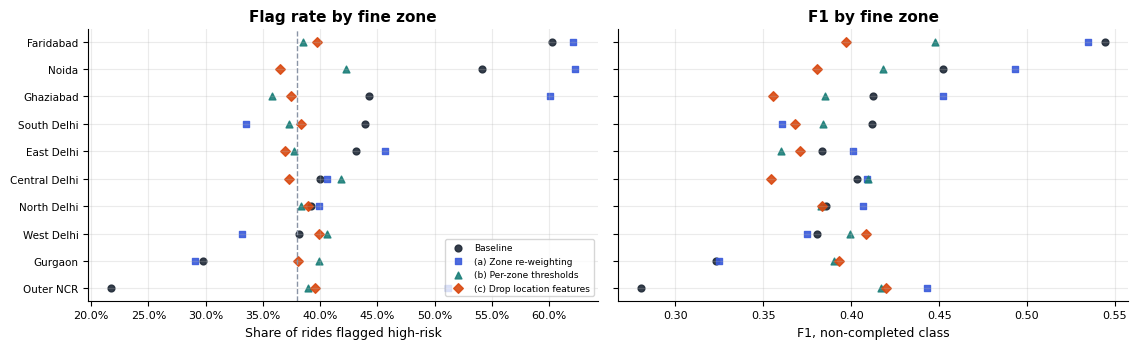

In [62]:
LOC_FEATS = ["pickup_zone", "drop_zone", "pickup_te", "drop_te", "pickup_density", "drop_density", "cross_zone"]
keep_cols = [c for c in X_fit.columns if c not in LOC_FEATS]
P_ = {**LGB_BASE, **search.best_params_}
model_c = lgb.LGBMClassifier(**P_).fit(X_fit[keep_cols], y_fit)
pc_cal, pc_test = model_c.predict_proba(X_cal[keep_cols])[:, 1], model_c.predict_proba(X_test[keep_cols])[:, 1]
flag_c = pc_test < np.quantile(pc_cal, nc_rate_fit)

def cell_weights(groups, y):
    key = pd.Series(groups).astype(str) + "|" + pd.Series(y).astype(str)
    return (len(key) / (key.nunique() * key.map(key.value_counts()))).values        # equal total weight per (zone, outcome) cell

mit_rows, group_f1 = [], {}
for lab, col in views.items():
    m_a = lgb.LGBMClassifier(**{**P_, "class_weight": None}).fit(X_fit, y_fit, sample_weight=cell_weights(train_fit[col].values, y_fit))
    pa_cal, pa_test = m_a.predict_proba(X_cal)[:, 1], m_a.predict_proba(X_test)[:, 1]
    thr_zone = {r: np.quantile(p_raw_cal[(cal[col] == r).values], nc_rate_fit) for r in cal[col].unique()}
    scen = {"Baseline": (flag_base, p_raw_test), "(a) Zone re-weighting": (pa_test < np.quantile(pa_cal, nc_rate_fit), pa_test),
            "(b) Per-zone thresholds": (p_raw_test < test[col].map(thr_zone).values, p_raw_test), "(c) Drop location features": (flag_c, pc_test)}
    for name, (fl, sc) in scen.items():
        t_ = fairness_table(fl, col)
        _, gap, gci, gp = group_f1_boot(y_test, fl, test[col].values)
        group_f1[(lab, name)] = t_
        mit_rows.append({"zone view": lab, "scenario": name, "overall F1 non-comp.": f1_score(y_test, (~fl).astype(int), pos_label=0), "overall ROC-AUC": roc_auc_score(y_test, sc),
                         "flagged share (min to max)": f"{pct(t_['flagged'].min())} to {pct(t_['flagged'].max())}", "F1 range": f"{t_['F1 non-comp.'].min():.3f} to {t_['F1 non-comp.'].max():.3f}",
                         "max F1 gap": gap, "gap 95% CI": f"{gci[0]:.3f} to {gci[1]:.3f}", "perm. p": gp})
mit = pd.DataFrame(mit_rows).set_index(["zone view", "scenario"])
display(mit.assign(**{c: mit[c].map(lambda v: f"{v:.3f}") for c in ["overall F1 non-comp.", "overall ROC-AUC", "max F1 gap"]}, **{"perm. p": mit["perm. p"].map(lambda v: "< 0.002" if v < 0.002 else f"{v:.2f}")}))
SCEN = ["Baseline", "(a) Zone re-weighting", "(b) Per-zone thresholds", "(c) Drop location features"]
for lab in ["North / South / Other", "Delhi vs satellite cities"]:
    tb = pd.DataFrame({name: group_f1[(lab, name)].apply(lambda r: f"{r['F1 non-comp.']:.3f} ({r['F1 CI']})", axis=1) for name in SCEN}).T
    md(f"**F1 on the non-completed class by zone, before and after: {lab}**"); display(tb)
fine_order = fair["Fine zones"].sort_values("flagged").index
fig, axs = plt.subplots(1, 2, figsize=(11.5, 3.6), sharey=True)
mk = dict(zip(SCEN, [("o", C_DARK), ("s", C_ACC), ("^", C_OK), ("D", C_BAD)]))
for name, (m_, c_) in mk.items():
    axs[0].scatter(group_f1[("Fine zones", name)].loc[fine_order, "flagged"], np.arange(len(fine_order)), marker=m_, color=c_, s=24, label=name, alpha=.9)
    axs[1].scatter(group_f1[("Fine zones", name)].loc[fine_order, "F1 non-comp."], np.arange(len(fine_order)), marker=m_, color=c_, s=24, alpha=.9)
axs[0].axvline(nc_rate_fit, color=C_NEUT, ls="--", lw=1); axs[0].set_yticks(np.arange(len(fine_order))); axs[0].set_yticklabels(fine_order, fontsize=7.5)
axs[0].set_xlabel("Share of rides flagged high-risk"); axs[0].set_title("Flag rate by fine zone"); axs[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1%}"))
axs[1].set_xlabel("F1, non-completed class"); axs[1].set_title("F1 by fine zone"); axs[0].legend(fontsize=6.5, loc="lower right")
plt.tight_layout(); plt.show()

In [63]:
def gaps_of(view): return mit.loc[view, "max F1 gap"]
def ps_of(view): return mit.loc[view, "perm. p"]
fz_flag = lambda sc: group_f1[("Fine zones", sc)]["flagged"]
best_fz = gaps_of("Fine zones").drop("Baseline").idxmin(); best_ds = gaps_of("Delhi vs satellite cities").drop("Baseline").idxmin()
G = lambda v, s: gaps_of(v)[s]
md(f"""**Insight (mitigation).**
* **Delhi vs satellite:** the F1 gap is {G('Delhi vs satellite cities','Baseline'):.3f} (p {pv(ps_of('Delhi vs satellite cities')['Baseline'])}) at baseline, {G('Delhi vs satellite cities','(a) Zone re-weighting'):.3f} with re-weighting (a), {G('Delhi vs satellite cities','(b) Per-zone thresholds'):.3f} with per-zone thresholds (b) and {G('Delhi vs satellite cities','(c) Drop location features'):.3f} without location features (c).
* **Fine zones:** the gap is {G('Fine zones','Baseline'):.3f} at baseline versus {G('Fine zones','(a) Zone re-weighting'):.3f} (a), {G('Fine zones','(b) Per-zone thresholds'):.3f} (b) and {G('Fine zones','(c) Drop location features'):.3f} (c). The flagged share across fine zones moves from {pct(fz_flag('Baseline').min())}-{pct(fz_flag('Baseline').max())} to {pct(fz_flag('(a) Zone re-weighting').min())}-{pct(fz_flag('(a) Zone re-weighting').max())} (a), {pct(fz_flag('(b) Per-zone thresholds').min())}-{pct(fz_flag('(b) Per-zone thresholds').max())} (b) and {pct(fz_flag('(c) Drop location features').min())}-{pct(fz_flag('(c) Drop location features').max())} (c).
* **North / South / Other:** gap {G('North / South / Other','Baseline'):.3f} at baseline versus {G('North / South / Other','(a) Zone re-weighting'):.3f} / {G('North / South / Other','(b) Per-zone thresholds'):.3f} / {G('North / South / Other','(c) Drop location features'):.3f}.
* **Cost to overall performance:** ROC-AUC {mit.loc[('Fine zones','Baseline'),'overall ROC-AUC']:.3f} at baseline, {mit.loc[('Fine zones','(a) Zone re-weighting'),'overall ROC-AUC']:.3f} (a), {mit.loc[('Fine zones','(b) Per-zone thresholds'),'overall ROC-AUC']:.3f} (b), {mit.loc[('Fine zones','(c) Drop location features'),'overall ROC-AUC']:.3f} (c): nothing is lost, because there was no skill to lose.
* The smallest fine-zone gap is achieved by **{best_fz}** and the smallest Delhi-vs-satellite gap by **{best_ds}**; the permutation p-values in the table show which remaining gaps are still larger than chance.""")
md(f"""**Recommendation (Q7) and expected impact.**
1. **Act on selection-rate parity now.** The zone-dependent flag rates are an avoidable, noise-driven disparity. Remove the location features from the booking-time model (option c), which gives the narrowest flag-rate spread, unless they demonstrate lift in a future validation; if they must stay, apply per-zone thresholds (b). **Re-weighting (a) did not fix it here** (fine-zone gap {G('Fine zones','(a) Zone re-weighting'):.3f} vs {G('Fine zones','Baseline'):.3f} at baseline), because it equalises loss weights, not the zone offsets in the scores; it becomes relevant only if zone data later proves informative.
2. **Monitor two things monthly, per zone:** (i) the flagged share against the platform average and (ii) F1 and false-negative rate with bootstrap CIs. **Trigger rule:** a gap whose 95% interval excludes zero in two consecutive months, in zones with enough volume for a stable interval.
3. **Collect more data from small zones.** The widest intervals belong to **Faridabad** ({int(fair['Fine zones'].loc['Faridabad','rides (test)'])} test rides) and **Outer NCR** ({int(fair['Fine zones'].loc['Outer NCR','rides (test)'])} rides). Interval width shrinks with the square root of volume, so about four times more rides are needed to halve a small zone's uncertainty; until then treat those zones' rates as provisional and pool Faridabad with neighbouring satellite cities for modelling.
4. **Expected impact.** With no predictive skill in any zone, the benefit of mitigation is **equal treatment, not accuracy**: it removes a spread of up to {100*(fz_flag('Baseline').max()-fz_flag('Baseline').min()):.0f} percentage points in intervention rates between zones, so no zone is systematically over- or under-served by incentives or penalties triggered by the score.
5. **Governance (Approach Document, E5).** Zone encodings can penalise low-income areas; here they add unequal treatment and no lift, so dropping them is both the fairest and the simplest choice.""")
R.update(q7_gap_nso=g1[0], q7_p_nso=g1[2], q7_gap_ds=g2[0], q7_p_ds=g2[2], q7_gap_fine=g3[0], q7_p_fine=g3[2], q7_move_f1=max_move_f1, q7_move_c=max_move_c,
         q7_flag_min=fz_flag("Baseline").min(), q7_flag_max=fz_flag("Baseline").max(), q7_best=best_fz, q7_mit=mit)

**Insight (mitigation).**
* **Delhi vs satellite:** the F1 gap is 0.043 (p < 0.002) at baseline, 0.037 with re-weighting (a), 0.001 with per-zone thresholds (b) and 0.015 without location features (c).
* **Fine zones:** the gap is 0.264 at baseline versus 0.210 (a), 0.088 (b) and 0.065 (c). The flagged share across fine zones moves from 21.8%-60.2% to 29.1%-62.3% (a), 35.8%-42.3% (b) and 36.5%-39.9% (c).
* **North / South / Other:** gap 0.023 at baseline versus 0.027 / 0.025 / 0.018.
* **Cost to overall performance:** ROC-AUC 0.502 at baseline, 0.506 (a), 0.502 (b), 0.500 (c): nothing is lost, because there was no skill to lose.
* The smallest fine-zone gap is achieved by **(c) Drop location features** and the smallest Delhi-vs-satellite gap by **(b) Per-zone thresholds**; the permutation p-values in the table show which remaining gaps are still larger than chance.

**Recommendation (Q7) and expected impact.**
1. **Act on selection-rate parity now.** The zone-dependent flag rates are an avoidable, noise-driven disparity. Remove the location features from the booking-time model (option c), which gives the narrowest flag-rate spread, unless they demonstrate lift in a future validation; if they must stay, apply per-zone thresholds (b). **Re-weighting (a) did not fix it here** (fine-zone gap 0.210 vs 0.264 at baseline), because it equalises loss weights, not the zone offsets in the scores; it becomes relevant only if zone data later proves informative.
2. **Monitor two things monthly, per zone:** (i) the flagged share against the platform average and (ii) F1 and false-negative rate with bootstrap CIs. **Trigger rule:** a gap whose 95% interval excludes zero in two consecutive months, in zones with enough volume for a stable interval.
3. **Collect more data from small zones.** The widest intervals belong to **Faridabad** (161 test rides) and **Outer NCR** (827 rides). Interval width shrinks with the square root of volume, so about four times more rides are needed to halve a small zone's uncertainty; until then treat those zones' rates as provisional and pool Faridabad with neighbouring satellite cities for modelling.
4. **Expected impact.** With no predictive skill in any zone, the benefit of mitigation is **equal treatment, not accuracy**: it removes a spread of up to 38 percentage points in intervention rates between zones, so no zone is systematically over- or under-served by incentives or penalties triggered by the score.
5. **Governance (Approach Document, E5).** Zone encodings can penalise low-income areas; here they add unequal treatment and no lift, so dropping them is both the fairest and the simplest choice.

## Closing summary

In [64]:
nsig = lambda col: int((zt.loc[ZONE_ORDER_EXCL, col] != "not significant").sum())
cm_ = R["q7_mit"]
HEAD = f"""**The question.** Can we predict, at the moment a ride is requested, whether it will be completed, so operations can intervene early? Across {len(df):,} NCR bookings in 2024, **{pct(df.non_completed.mean())}** did not complete.

**Headline result.** *Not with the information available at booking time.* The final LightGBM (time-based 80/20 split, class-weighted, tuned, calibrated) reaches a test ROC-AUC of **{R['auc']:.3f}** (95% CI {R['auc_lo']:.3f} to {R['auc_hi']:.3f}) and PR-AUC {R['ap']:.3f} against {1-y_test.mean():.3f} for random guessing. A model trained on shuffled labels scores {R['auc_shuf']:.3f}, and a stratified random split gives {R['auc_random_split']:.3f}. Every score that looked impressive used information that exists only after a driver accepts or the ride starts (flags alone reach {R['diag'].loc["A'. Null flags only (leaky)", 'test ROC-AUC']:.2f}); all of it was excluded from the deployable model and used only for diagnosis.

**What the data does show.** Avg VTAT is the one operational variable with a large effect: customers cancelled **{pct(R['q3_hi_cust'],0)}** of matches with VTAT above 16 minutes, and matches above 14 minutes hold **{pct(R['q3_late_share'],0)}** of all customer cancellations (⚠ the sharp cut-off looks like a synthetic-data artefact, so read it as direction, not magnitude).
"""
ROWS = [
 ("**Q1. Time slots**", f"No hour or weekday is distinguishable from noise (worst-slot permutation p = {R['q1_p_cell']:.2f}; hourly chi-square p = {R['p_hour']:.2f}); CTAT does not vary by hour.",
  "No fixed surge calendar; budget-capped live supply-ratio triggers with a holdout test.", f"High: n = {len(df):,}, narrow intervals, no effect found"),
 ("**Q2. Zones**", f"{nsig('cancel vs avg')} of 9 zones differ on cancellation, {nsig('NDF vs avg')} of 9 on No Driver Found (p = {R['q2_p_cancel']:.2f} / {R['q2_p_ndf']:.2f}); hot spots do not persist (Spearman {R['q2_rho']:+.2f}).",
  "No static high-risk list or premium driver pool; weight dispatch by live imbalance and monitor with CIs.", "High that zones are equal in this data; Medium for live data"),
 ("**Q3. Top drivers**", f"Booking-time model: {', '.join(R['q3_top'])} (none beats noise). Diagnostic SHAP top 3: {', '.join(Q3_TOP3)}; {Q3_REAL} pass both the noise-multiple and permutation checks; **Avg VTAT** is the one actionable at dispatch. ⚠ 100% cancellation beyond 16 min is a synthetic-data artefact.",
  f"Cap VTAT and re-dispatch matches above it ({R['q3_late_cc']:,} cancellations a year above 14 min); in-trip support for Incomplete trips; no vehicle restrictions.", "Medium for VTAT (large but observational, synthetic-looking); Low for booking-time drivers"),
 ("**Q4. Fare vs driver cancellations**", f"Booking Value is missing for every driver-cancelled ride; route-fare proxy shows no trend (p = {R['q4_p']:.2f}); fare is uncorrelated with distance (r = {R['q4_fare_dist_r']:+.3f}, ⚠ synthetic-data artefact).",
  "No commission change yet; randomised driver-bonus test; fix the fare field.", "Low: the key variable cannot be observed"),
 ("**Q5. Driver reasons**", f"Four reasons at about 25% each (p = {R['q5_p_uniform']:.2f}, ⚠ equal shares are a synthetic-data artefact); driver cancellations are {pct(R['q5_driver_share'],0)} of failures; {pct(R['q5_beh'],0)} of customer cancellations cite driver behaviour.",
  "Four-module onboarding plus quarterly refresher; per-driver reason tracking; rank reasons from production logs first.", "High that no reason dominates here; Medium for training priorities"),
 ("**Q6. Vehicle types**", f"Completion {pct(vtab.rate.min())} to {pct(vtab.rate.max())}; best-vs-worst gap {100*R['q6_gap']:.1f} points, p = {R['q6_p']:.2f}.",
  f"Keep supply demand-led and pricing neutral; do not favour {R['q6_best']}.", f"High: every type has at least {int(vtab.n.min()):,} requests; gap within noise"),
 ("**Q7. Fairness**", f"Equal outcomes and ROC-AUC about 0.5 in every zone, but the model flags **{pct(R['q7_flag_min'],0)} to {pct(R['q7_flag_max'],0)}** of rides by fine zone; Delhi-vs-satellite F1 gap {R['q7_gap_ds']:.3f} (p {pv(R['q7_p_ds'])}).",
  f"Drop location features (c) or per-zone thresholds (b): fine-zone gap {cm_.loc[('Fine zones','Baseline'),'max F1 gap']:.3f} to {cm_.loc[('Fine zones','(c) Drop location features'),'max F1 gap']:.3f} / {cm_.loc[('Fine zones','(b) Per-zone thresholds'),'max F1 gap']:.3f}; monthly parity monitor.", "High for the disparity (30,000 test rides); Medium for the fix (one test period)"),
]
TABLE = "| Question | Finding | Recommendation | Confidence |\n|---|---|---|---|\n" + "\n".join(f"| {a} | {b} | {c} | {d} |" for a, b, c, d in ROWS)
NOTE = "*Confidence is the analyst's judgement of how far the finding would survive in live data: sample size, effect size, whether the key variable is observed, and whether the pattern looks like a synthetic-data artefact (⚠).*"
update_display(Markdown("## Executive summary\n\n" + HEAD + "\n" + TABLE + "\n\n" + NOTE), display_id="exec_summary")
md(f"**Bottom line.** Booking-time data does not predict ride completion (test ROC-AUC {R['auc']:.3f}, 95% CI {R['auc_lo']:.3f} to {R['auc_hi']:.3f}). The actionable findings are the VTAT cap and the removal of location features for fairness. The full Q1-Q7 table with confidence ratings is in the **Executive summary** at the top.")
md("**One line per question.**\n" + "\n".join(f"* {a}: {c}" for a, b, c, d in ROWS))
md(f"""**Cost view.** Under the stated 3:1 assumption, flagging every ride beats flagging none whenever the cost ratio exceeds {R['be_ratio']:.2f}; with scores this flat, selective flagging adds nothing, so per-ride risk targeting would perform like random targeting. Impact figures throughout are **illustrative scenarios on stated assumptions**, not forecasts.

**What to do next.** (1) Pilot the VTAT-cap rule with a randomised holdout; (2) start logging **supply-side signals at request time** (idle drivers within a radius, ETA offered, surge multiplier, weather) so a real booking-time model becomes possible; (3) validate the fare field and test driver incentives experimentally; (4) deploy any booking-time score only with location features removed, behind a fairness monitor; (5) revisit quarterly with the same significance rules.

**Risks (Approach Document, E5).** *Latency:* LightGBM scores in milliseconds, so a sub-second dispatch budget is realistic once there is a model worth serving. *Fairness:* a real risk when zone features are used (shown in Q7); mitigated as recommended. *Data validity:* several fields behave like generated data (⚠ above); confirm magnitudes against production logs before acting.""")

**Bottom line.** Booking-time data does not predict ride completion (test ROC-AUC 0.502, 95% CI 0.495 to 0.508). The actionable findings are the VTAT cap and the removal of location features for fairness. The full Q1-Q7 table with confidence ratings is in the **Executive summary** at the top.

**One line per question.**
* **Q1. Time slots**: No fixed surge calendar; budget-capped live supply-ratio triggers with a holdout test.
* **Q2. Zones**: No static high-risk list or premium driver pool; weight dispatch by live imbalance and monitor with CIs.
* **Q3. Top drivers**: Cap VTAT and re-dispatch matches above it (4,176 cancellations a year above 14 min); in-trip support for Incomplete trips; no vehicle restrictions.
* **Q4. Fare vs driver cancellations**: No commission change yet; randomised driver-bonus test; fix the fare field.
* **Q5. Driver reasons**: Four-module onboarding plus quarterly refresher; per-driver reason tracking; rank reasons from production logs first.
* **Q6. Vehicle types**: Keep supply demand-led and pricing neutral; do not favour Uber XL.
* **Q7. Fairness**: Drop location features (c) or per-zone thresholds (b): fine-zone gap 0.264 to 0.065 / 0.088; monthly parity monitor.

**Cost view.** Under the stated 3:1 assumption, flagging every ride beats flagging none whenever the cost ratio exceeds 1.64; with scores this flat, selective flagging adds nothing, so per-ride risk targeting would perform like random targeting. Impact figures throughout are **illustrative scenarios on stated assumptions**, not forecasts.

**What to do next.** (1) Pilot the VTAT-cap rule with a randomised holdout; (2) start logging **supply-side signals at request time** (idle drivers within a radius, ETA offered, surge multiplier, weather) so a real booking-time model becomes possible; (3) validate the fare field and test driver incentives experimentally; (4) deploy any booking-time score only with location features removed, behind a fairness monitor; (5) revisit quarterly with the same significance rules.

**Risks (Approach Document, E5).** *Latency:* LightGBM scores in milliseconds, so a sub-second dispatch budget is realistic once there is a model worth serving. *Fairness:* a real risk when zone features are used (shown in Q7); mitigated as recommended. *Data validity:* several fields behave like generated data (⚠ above); confirm magnitudes against production logs before acting.

## Appendix A. Zone mapping (hand-built lookup of the 176 pickup locations)

In [65]:
amap = pd.DataFrame({"zone": list(ZONE_FINE), "locations": [len(v) for v in ZONE_FINE.values()],
                     "rides": [int((df.pickup_zone == z).sum()) for z in ZONE_FINE],
                     "North/South/Other": [REGION_NSO[z] for z in ZONE_FINE], "Delhi/satellite": [REGION_DS[z] for z in ZONE_FINE],
                     "pickup locations": [", ".join(sorted(v)) for v in ZONE_FINE.values()]}).set_index("zone")
md(amap.drop(columns="pickup locations").to_markdown())
for z, v in ZONE_FINE.items():
    md(f"<small>**{z}:** {', '.join(sorted(v))}</small>")
alt_tbl = pd.DataFrame({"primary zone": {l: LOC2ZONE[l] for l in ALT_ZONE}, "alternative zone (sensitivity check)": ALT_ZONE})
md("**Uncertain locations and their alternative zone** (used only in the Q7 mapping-sensitivity check):")
md(alt_tbl.to_markdown())

| zone          |   locations |   rides | North/South/Other   | Delhi/satellite   |
|:--------------|------------:|--------:|:--------------------|:------------------|
| North Delhi   |          23 |   19714 | North               | Delhi             |
| Central Delhi |          24 |   20554 | Other               | Delhi             |
| West Delhi    |          20 |   17266 | North               | Delhi             |
| East Delhi    |          16 |   13392 | North               | Delhi             |
| South Delhi   |          40 |   34059 | South               | Delhi             |
| Gurgaon       |          36 |   30654 | South               | Satellite cities  |
| Noida         |           6 |    5072 | Other               | Satellite cities  |
| Ghaziabad     |           5 |    4274 | North               | Satellite cities  |
| Faridabad     |           1 |     831 | South               | Satellite cities  |
| Outer NCR     |           5 |    4184 | Other               | Satellite cities  |

<small>**North Delhi:** Adarsh Nagar, Ashok Vihar, Azadpur, GTB Nagar, Inderlok, Jahangirpuri, Kanhaiya Nagar, Kashmere Gate, Kashmere Gate ISBT, Keshav Puram, Model Town, Netaji Subhash Place, Pitampura, Pulbangash, Rithala, Rohini, Rohini East, Rohini West, Samaypur Badli, Shastri Nagar, Tis Hazari, Vidhan Sabha, Vishwavidyalaya</small>

<small>**Central Delhi:** Barakhamba Road, Central Secretariat, Chanakyapuri, Chandni Chowk, Connaught Place, Delhi Gate, ITO, India Gate, Indraprastha, Jama Masjid, Jor Bagh, Karol Bagh, Khan Market, Lal Quila, Lok Kalyan Marg, Mandi House, New Delhi Railway Station, Paharganj, Patel Chowk, Pragati Maidan, Rajiv Chowk, Sarojini Nagar, Satguru Ram Singh Marg, Udyog Bhawan</small>

<small>**West Delhi:** Ashok Park Main, Dwarka Mor, Dwarka Sector 21, IGI Airport, Janakpuri, Kirti Nagar, Madipur, Moti Nagar, Mundka, Nawada, Paschim Vihar, Peeragarhi, Punjabi Bagh, Rajouri Garden, Ramesh Nagar, Shivaji Park, Subhash Nagar, Tagore Garden, Tilak Nagar, Uttam Nagar</small>

<small>**East Delhi:** Akshardham, Anand Vihar, Anand Vihar ISBT, Dilshad Garden, Jhilmil, Karkarduma, Laxmi Nagar, Mansarovar Park, Mayur Vihar, Nirman Vihar, Preet Vihar, Seelampur, Shahdara, Shastri Park, Welcome, Yamuna Bank</small>

<small>**South Delhi:** AIIMS, Arjangarh, Ashram, Aya Nagar, Badarpur, Bhikaji Cama Place, Chhatarpur, Chirag Delhi, Ghitorni, Ghitorni Village, Govindpuri, Greater Kailash, Green Park, Hauz Khas, Hauz Rani, IGNOU Road, IIT Delhi, INA Market, Jasola, Kalkaji, Lajpat Nagar, Maidan Garhi, Malviya Nagar, Mehrauli, Moolchand, Munirka, Nehru Place, Okhla, Panchsheel Park, Qutub Minar, RK Puram, Saidulajab, Saket, Saket A Block, Sarai Kale Khan, South Extension, Sultanpur, Tughlakabad, Vasant Kunj, Vinobapuri</small>

... (3 outputs left out)

<small>**Faridabad:** Faridabad Sector 15</small>

<small>**Outer NCR:** Bahadurgarh, Bhiwadi, Meerut, Panipat, Sonipat</small>

**Uncertain locations and their alternative zone** (used only in the Q7 mapping-sensitivity check):

|                  | primary zone   | alternative zone (sensitivity check)   |
|:-----------------|:---------------|:---------------------------------------|
| Rajiv Nagar      | Gurgaon        | North Delhi                            |
| New Colony       | Gurgaon        | South Delhi                            |
| Ambience Mall    | Gurgaon        | South Delhi                            |
| MG Road          | Gurgaon        | Central Delhi                          |
| Sultanpur        | South Delhi    | Gurgaon                                |
| Gwal Pahari      | Gurgaon        | South Delhi                            |
| Shastri Nagar    | North Delhi    | Ghaziabad                              |
| Mansarovar Park  | East Delhi     | Ghaziabad                              |
| Botanical Garden | Noida          | South Delhi                            |
| IGI Airport      | West Delhi     | Gurgaon                                |
| Sarai Kale Khan  | South Delhi    | East Delhi                             |
| Subhash Chowk    | Gurgaon        | West Delhi                             |
| Arjangarh        | South Delhi    | Gurgaon                                |
| Indraprastha     | Central Delhi  | East Delhi                             |
| Inderlok         | North Delhi    | Central Delhi                          |
| Pulbangash       | North Delhi    | Central Delhi                          |
| Welcome          | East Delhi     | North Delhi                            |

## Appendix B. Assumptions, decisions and reproducibility
* **Target:** Completed = 1; all other statuses = 0. **Prediction moment:** strict booking time.
* **Excluded from the deployable model:** VTAT, CTAT, Booking Value, Ride Distance, Payment Method, ratings, outcome flags and reason columns, and any availability flag built from them. The only use of Ride Distance is a route-average proxy fitted on training rows; it is dropped when it did not help validation (decision printed in D1).
* **Customer history:** not built; almost every customer ID occurs once. **Booking ID collisions** are kept (distinct customers and dates).
* **Split:** earliest 80% train (with the last 15% of it held out as validation/calibration), latest 20% test. Encodings are fitted on training rows only, out-of-fold for the rows they are fitted on.
* **Metric:** model selected on PR-AUC of the non-completed class; ROC-AUC, F1 (both classes) and macro F1 reported. Class weights, no SMOTE. Tuning: 12-iteration randomized search, 3-fold time-ordered CV.
* **Cost assumption (labelled):** false positive (predict "completes", it fails) costs the mean booking value of a completed ride; false negative costs that divided by the cost ratio (3:1 base case, sensitivity 1:1, 2:1, 5:1). A correct alert costs nothing extra.
* **Q3 assumption:** converting 10/25/50% of far-match customer cancellations to completions is an assumption, shown as a sensitivity table.
* **Intervals and tests:** Wilson 95% intervals for rates; bootstrap CIs (300 resamples) for F1 and AUC; permutation tests (500 shuffles) for between-group spread; chi-square and Kruskal-Wallis where stated. A "significant" difference means p < 0.05 or a confidence interval that excludes the comparison value; no formal multiple-comparison correction is applied except the Bonferroni check on pickup locations.
* **Zones:** hand-built mapping (Appendix A), including judgement calls; the sensitivity check in Q7 moves 17 uncertain locations. Faridabad has one pickup location and is excluded from rankings.
* **Reproducibility:** seed 42 throughout; relative paths only; no external downloads except `pip` in the first cell. Package versions are printed below.

In [66]:
import sys, sklearn, matplotlib
print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__} | lightgbm {lgb.__version__} | shap {shap.__version__} | matplotlib {matplotlib.__version__}")

Python 3.10.11 | pandas 2.3.3 | numpy 1.26.4 | scikit-learn 1.7.2 | lightgbm 4.7.0 | shap 0.49.1 | matplotlib 3.10.8
